# Laptop price and specification pipeline (K2 Horizon 3.7B)

**Goal.** Collect laptop listings from Indian retailers and a manufacturer store, keep every raw page for
traceability, turn each listing into a strict 42-field canonical record (identity, processor with power limit, memory,
graphics with VRAM and TGP, display, battery, adapter, weight, thickness, cooling, Wi-Fi, software), match identical
configurations across sellers (identical CPUs or GPUs at different stated power limits are different
configurations), and load everything into a queryable SQLite database with price history, per-field provenance,
freshness tracking and the lowest *current* comparable price per exact configuration.

**Data sources** (each checked on 2026-10-09/10 for robots.txt and terms; details in `RESEARCH.md`).
- Live: **Reliance Digital** and **Vijay Sales** (retailers) and **HP Store India** (manufacturer, full spec tables),
  discovered through their sitemaps (HP lists a plain-text product URL file in its robots.txt), filtered by robots.txt
  (RFC 9309 matcher), fetched slowly (6 s or more per host) with retries, conditional requests and a cache.
- Excluded on their terms or access controls, never bypassed: Flipkart, Amazon.in, Apple, ASUS, Intel, NVIDIA, Dell
  and Poorvika (terms forbid robots, scraping or storing content); Croma, Lenovo, MSI, JioMart and PrimeABGB (bot
  walls or HTTP 403); Tata CLiQ and Lenovo PSREF (data only through internal APIs). No retailer API credentials are
  configured. No permitted source of measured benchmarks, sustained performance or thermal limits was found, so the
  `benchmarks` table stays empty rather than holding scraped or invented numbers.
- Offline ground truth: 29 real product-page snapshots with hand-verified labels (22 retailer pages for the original
  21 fields, 7 HP Store pages for all 42), attached as a Kaggle dataset (the `fixtures/` folder of the repository).
  They drive the evaluation and seed the database, so the pipeline produces meaningful output even when the live
  sites are unreachable from Kaggle.

**Approach.** Deterministic code does everything that can be checked mechanically: HTML and page-state parsing, price
parsing, availability, condition, spec-table extraction with provenance (rules), source-conflict detection, schema
validation, grounding of every value against the source text, deduplication, matching, freshness and price
aggregation. The LLM only fills fields the structured data does not state: rule values are prefilled into its JSON,
and decoding is constrained (code writes every key; each value is restricted to its field grammar by filtering the
model's top-k tokens), so the output is always parseable.

**Production features.** Resume from the previous run's database (attach the previous output), schema migrations,
one scraping thread per site, oldest-first refresh, delisting on 404/410 or redirect, a `fresh`/`stale`/`delisted`
label on every current offer, run metrics, threshold alerts (`metrics/health.json`) and idempotent, re-runnable stages.

**Model facts verified on 2026-10-09** (model card, `config.json`, `modeling_k2_horizon.py`, `chat_template.jinja`):
dense decoder, about 5.05 B stored parameters (3.7 B core plus a 250,624-token vocabulary with untied embeddings),
BF16 weights (10.1 GB), `trust_remote_code=True`, validated with Transformers 5.15.0, SDPA attention supported, no
custom kernels. It is a reasoning model: the chat template always opens a thinking block, and `reasoning_effort`
(`high`, `medium`, `low`) selects `<ifm|think>`, `<ifm|think_fast>` or `<ifm|think_faster>`. T4 GPUs have no fast
BF16, so the weights are cast to FP16 (one full replica per GPU); a numerical sanity check falls back to FP32 split
across both GPUs if FP16 overflows.

**Hardware.** Kaggle GPU T4 x2. Both GPUs run their own model replica and normalise listings in parallel.

**Required Kaggle settings.** Accelerator *GPU T4 x2*; *Internet on* (pip install, model download, live scraping);
*Environment: Always use latest environment* (an older pinned image works too, but the first cell then has to
upgrade PyTorch, a download of about 2.5 GB); attach the fixtures dataset (upload the repository's `fixtures/` folder
as a private dataset); for incremental runs, also attach this notebook's previous output. Keep the notebook and its
outputs private: Vijay Sales' terms allow personal, non-commercial use only and forbid republishing content.

**Outputs in `/kaggle/working/`.**
```
db/laptops.sqlite      products, specifications with provenance, listings, price history, freshness, metrics, alerts
raw_html/<site>/       gzipped raw HTML, content-addressed by SHA-256 (needed to resume the next run)
schema/                canonical laptop JSON Schema (version 2.0)
metrics/               evaluation, run summary, health checks (JSON, CSV)
plots/                 all figures (PNG)
reports/               data-quality report, review queue, lowest prices
logs/                  pipeline log
outputs.zip            everything above, created by the last cell
```

## 1. Setup
### 1.1 Install pinned libraries
The model card validates K2 Horizon with Transformers 5.15.0, and its remote code imports recent Transformers modules
(`masking_utils`, `OutputRecorder`). Transformers 5.x also needs PyTorch 2.5 or newer (below that it silently disables
PyTorch and model loading fails) and a recent Accelerate for `device_map`. Older Kaggle images ship torch 2.0, so the
cell upgrades the torch stack to 2.6.0 (CUDA 12.4 wheels, which include T4 kernels) only when it is too old. It checks
versions with `importlib.metadata` (without importing torch or Transformers, so an upgrade takes effect in this
session) and installs only what is missing. Expected output: the versions in use.

In [1]:
import importlib.metadata as _md
import subprocess
import sys

from packaging.version import Version

PINNED = {"transformers": "5.15.0"}
# Transformers 5.x disables PyTorch below 2.5, and device_map loading needs a recent Accelerate.
# Older Kaggle images (for example a notebook pinned to its original environment) ship torch 2.0.
TORCH_MIN = "2.5"
TORCH_STACK = ["torch==2.6.0", "torchvision==0.21.0", "torchaudio==2.6.0"]
TORCH_INDEX = "https://download.pytorch.org/whl/cu124"  # CUDA 12.4 wheels include T4 (sm_75) kernels
ACCELERATE_MIN = "1.1.0"


def _installed(pkg):
    try:
        return _md.version(pkg)
    except _md.PackageNotFoundError:
        return None


def _older(pkg, minimum):
    v = _installed(pkg)
    return v is None or Version(v) < Version(minimum)


def _pip(*args):
    print("Installing:", " ".join(args), flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)


if _older("torch", TORCH_MIN):
    _pip(*TORCH_STACK, "--index-url", TORCH_INDEX)
_need = [f"{p}=={v}" for p, v in PINNED.items() if _installed(p) != v]
if _older("accelerate", ACCELERATE_MIN):
    _need.append(f"accelerate>={ACCELERATE_MIN}")
if _need:
    _pip(*_need)
for _p in [
    "torch",
    "transformers",
    "accelerate",
    "tokenizers",
    "safetensors",
    "huggingface-hub",
    "pandas",
    "matplotlib",
]:
    print(f"{_p:16s} {_installed(_p)}")

Installing: transformers==5.15.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 91.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 74.6 MB/s eta 0:00:00


torch            2.11.0+cu128
transformers     5.15.0
accelerate       1.14.0
tokenizers       0.22.2
safetensors      0.8.0
huggingface-hub  1.29.0
pandas           2.3.3
matplotlib       3.10.0


### 1.2 Imports
All imports live here. Scraping and parsing use only the standard library (`urllib`, `re`, `json`, `html`, `sqlite3`),
which keeps the deterministic stages dependency-free and easy to audit.

In [2]:
import datetime as dt
import gzip
import hashlib
import html
import json
import logging
import os
import queue
import random
import re
import shutil
import sqlite3
import threading
import time
import urllib.error
import urllib.request
import zipfile
import zlib
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass
from pathlib import Path
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from huggingface_hub import snapshot_download
from IPython.display import FileLink, Markdown, display
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, is_torch_available

### 1.3 Hardware check
Prints GPUs, VRAM, CPU cores, RAM and free disk, and asserts that two GPUs are visible because the normalisation stage
runs one model replica per GPU. It also asserts that Transformers can use PyTorch, so a version mismatch stops the run
here instead of at model loading.

In [3]:
assert (
    is_torch_available()
), f"Transformers cannot use torch {torch.__version__}; re-run the install cell and restart the session."
N_GPUS = torch.cuda.device_count()
for _i in range(N_GPUS):
    _p = torch.cuda.get_device_properties(_i)
    print(
        f"GPU {_i}: {_p.name}, {_p.total_memory / 2**30:.1f} GiB, compute capability {_p.major}.{_p.minor}"
    )
_vm = psutil.virtual_memory()
print(
    f"CPU cores: {os.cpu_count()} | RAM total {_vm.total / 2**30:.1f} GiB, available {_vm.available / 2**30:.1f} GiB"
)
print(
    f"Free disk in /kaggle/working: {shutil.disk_usage('/kaggle/working').free / 2**30:.1f} GiB"
)
assert (
    N_GPUS >= 2
), "Two GPUs are required: set the accelerator to 'GPU T4 x2' in the notebook settings."

GPU 0: Tesla T4, 14.6 GiB, compute capability 7.5
GPU 1: Tesla T4, 14.6 GiB, compute capability 7.5
CPU cores: 4 | RAM total 31.3 GiB, available 29.6 GiB
Free disk in /kaggle/working: 19.5 GiB


## 2. Configuration
Every tunable lives in this cell: paths, resume, sites, politeness limits, model and decoding settings, versions,
freshness rules and monitoring thresholds. The adapter, rules, prompt and decoder versions are part of the cache keys
(and the model's resolved commit hash is too), so changing one re-runs only the affected stage on the next run;
`DB_USER_VERSION` drives schema migrations.

Key choices:
- `MIN_REQUEST_INTERVAL_S = 6` per host (or the site's `Crawl-delay`, if larger), at most 3 retries with exponential
  backoff, a 15 MB response cap, and a circuit breaker that stops a host after 5 consecutive failures or at the first
  bot-protection page. Sites run in parallel; requests to one host never do.
- `MAX_FETCHES_PER_SITE = 80` caps each run's requests per site (about 8 to 10 minutes per site at 6 to 8 s); known
  listings are refreshed oldest first, so the budget goes to the stalest prices.
- `REASONING_EFFORT = "low"` with a 512-token thinking budget. The model card recommends `high` with 32k tokens,
  which would take tens of minutes per listing on a T4; truncated thinking is closed explicitly and counted in the
  metrics. Decoding is greedy, matching the card's near-greedy (temperature 0.01) function-calling setting.
- `PRICE_FRESHNESS_DAYS = 7`: an offer verified longer ago is `stale` and never used as a current price.

In [4]:
WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
DIRS = {
    name: WORK / name
    for name in [
        "db",
        "raw_html",
        "schema",
        "metrics",
        "plots",
        "reports",
        "logs",
        "cache",
    ]
}
for _d in DIRS.values():
    _d.mkdir(parents=True, exist_ok=True)
DB_PATH = DIRS["db"] / "laptops.sqlite"
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
SEED = 42

# Persistence: resume from a previous run's outputs attached under /kaggle/input (see section 2.2)
RESUME_FROM_PREVIOUS_RUN = True

# Scraping
ENABLE_LIVE_SCRAPE = True
SITES_ENABLED = ["reliancedigital", "vijaysales", "hpstore"]
MAX_NEW_PRODUCT_URLS_PER_SITE = 30
MAX_FETCHES_PER_SITE = 80
REFRESH_AFTER_HOURS = 20
SITEMAP_CACHE_HOURS = 24
MIN_REQUEST_INTERVAL_S = 6.0
REQUEST_JITTER_S = 2.0
HTTP_TIMEOUT_S = 30
HTTP_MAX_RETRIES = 3
HTTP_MAX_BYTES = 15 * 2**20
HOST_FAILURE_LIMIT = 5
CONTACT = ""  # optional contact URL or email for the User-Agent string
USER_AGENT_TOKEN = "LaptopPriceResearchBot"
USER_AGENT = f"{USER_AGENT_TOKEN}/0.2 (personal non-commercial research prototype{'; ' + CONTACT if CONTACT else ''})"

# LLM
MODEL_ID = "IFM/K2-Horizon-3.7B"
MODEL_REVISION = (
    "main"  # pin a commit hash for exact reproducibility; the resolved hash is logged
)
HF_CACHE = Path("/tmp/hf_cache")
REASONING_EFFORT = "low"
REASONING_BUDGET_TOKENS = 512
LLM_TOPK = 64
LLM_MAX_ATTEMPTS = 2
LLM_INPUT_MAX_CHARS = 7000
MAX_LISTINGS_TO_NORMALISE = 250

# Versions (part of cache keys and of the database schema)
SCHEMA_VERSION = "2.0"
DB_USER_VERSION = 2
ADAPTER_VERSION = "a2"
RULES_VERSION = "r1"
PROMPT_VERSION = "p2"
DECODER_VERSION = "d2"

# Prices and freshness
PRICE_FRESHNESS_DAYS = 7
MIN_VALID_PRICE_INR = 5_000
MAX_VALID_PRICE_INR = 1_000_000
SUSPICIOUS_DISCOUNT = 0.5  # MRP more than twice the price is flagged, not discarded

# Monitoring thresholds (section 21)
ALERT_FETCH_ERROR_RATE = 0.3
ALERT_EXTRACTION_FAILURE_RATE = 0.2
ALERT_MISSING_PRICE_RATE = 0.2
ALERT_STALE_SHARE = 0.5
ALERT_LLM_FAILURE_RATE = 0.1
ALERT_TRUNCATED_RATE = 0.5

RUN_CONFIG = {
    "seed": SEED,
    "sites": SITES_ENABLED,
    "live_scrape": ENABLE_LIVE_SCRAPE,
    "resume": RESUME_FROM_PREVIOUS_RUN,
    "max_new_urls_per_site": MAX_NEW_PRODUCT_URLS_PER_SITE,
    "max_fetches_per_site": MAX_FETCHES_PER_SITE,
    "refresh_after_hours": REFRESH_AFTER_HOURS,
    "min_request_interval_s": MIN_REQUEST_INTERVAL_S,
    "http_max_retries": HTTP_MAX_RETRIES,
    "user_agent": USER_AGENT,
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "reasoning_effort": REASONING_EFFORT,
    "reasoning_budget_tokens": REASONING_BUDGET_TOKENS,
    "llm_topk": LLM_TOPK,
    "llm_max_attempts": LLM_MAX_ATTEMPTS,
    "schema_version": SCHEMA_VERSION,
    "adapter_version": ADAPTER_VERSION,
    "rules_version": RULES_VERSION,
    "prompt_version": PROMPT_VERSION,
    "decoder_version": DECODER_VERSION,
    "price_freshness_days": PRICE_FRESHNESS_DAYS,
}
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Run", RUN_ID, "| DB", DB_PATH)

Run 20261009T192530Z | DB /kaggle/working/db/laptops.sqlite


### 2.1 Logging and small utilities
A logger writes to `logs/pipeline.log` and to the notebook. `stage_timer` records wall-clock time per stage for the
final summary and says whether the stage finished or failed. Hash helpers give content-addressed storage and cache keys.

In [5]:
LOG = logging.getLogger("pipeline")
LOG.setLevel(logging.INFO)
LOG.handlers.clear()
_fh = logging.FileHandler(DIRS["logs"] / "pipeline.log", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
LOG.addHandler(_fh)
LOG.propagate = False
STAGE_TIMES = {}
RUN_METRICS = (
    []
)  # (stage, metric, value); written to the run_metrics table in section 22


def metric(stage, name, value):
    RUN_METRICS.append((stage, name, None if value is None else float(value)))


def log(msg, level=logging.INFO):
    LOG.log(level, msg)
    print(msg, flush=True)


class stage_timer:
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        self.t0 = time.perf_counter()
        log(f"[{self.name}] started")
        return self

    def __exit__(self, exc_type, exc, tb):
        STAGE_TIMES[self.name] = (
            STAGE_TIMES.get(self.name, 0.0) + time.perf_counter() - self.t0
        )
        metric(self.name, "seconds", STAGE_TIMES[self.name])
        metric(self.name, "failed", exc_type is not None)
        if exc_type is None:
            log(f"[{self.name}] finished in {STAGE_TIMES[self.name]:.1f}s")
        else:
            log(
                f"[{self.name}] failed after {STAGE_TIMES[self.name]:.1f}s: {exc_type.__name__}",
                logging.ERROR,
            )


def now_iso():
    return dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")


def parse_iso(s):
    """ISO 8601 to an aware UTC datetime; accepts a trailing 'Z' and treats naive times as UTC."""
    d = dt.datetime.fromisoformat(str(s).strip().replace("Z", "+00:00"))
    return d if d.tzinfo else d.replace(tzinfo=dt.timezone.utc)


def age_hours(s):
    return (dt.datetime.now(dt.timezone.utc) - parse_iso(s)).total_seconds() / 3600


def sha256_bytes(b):
    return hashlib.sha256(b).hexdigest()


def sha256_text(s):
    return sha256_bytes(s.encode("utf-8"))


def jdump(o):
    return json.dumps(o, ensure_ascii=False, sort_keys=True)

### 2.2 Resume from the previous run
Kaggle starts every session with an empty `/kaggle/working`, so incremental updates need the previous state. Attach the
previous version of this notebook's output as an input (*Add Input > Your Work > this notebook*): this cell finds the
newest `db/laptops.sqlite` (or an `outputs.zip` containing it) under `/kaggle/input`, copies the database and the raw
HTML archive into `/kaggle/working`, and checks the database with `PRAGMA integrity_check`. A corrupt copy is set
aside and the run starts fresh. Without an attached previous run, the pipeline starts from an empty database and the
fixtures. Expected output: where the run resumed from.

In [6]:
def find_previous_run():
    """Newest previous-run database under /kaggle/input: a db/laptops.sqlite file, or one inside an outputs.zip."""
    dbs = sorted(
        INPUT.rglob("db/laptops.sqlite"), key=lambda p: p.stat().st_mtime, reverse=True
    )
    if dbs:
        return dbs[0], None
    for z in sorted(
        INPUT.rglob("outputs.zip"), key=lambda p: p.stat().st_mtime, reverse=True
    ):
        with zipfile.ZipFile(z) as zf:
            if "db/laptops.sqlite" in zf.namelist():
                return None, z
    return None, None


def safe_member(name):
    parts = Path(name).parts
    return (
        parts
        and parts[0] in ("db", "raw_html")
        and ".." not in parts
        and not Path(name).is_absolute()
    )


def db_is_healthy(path):
    c = None
    try:
        c = sqlite3.connect(
            path
        )  # closed explicitly: sqlite3's context manager only commits
        return c.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
    except sqlite3.DatabaseError:
        return False
    finally:
        if c is not None:
            c.close()


RESUMED_FROM = None
if RESUME_FROM_PREVIOUS_RUN and not DB_PATH.exists():
    _db_src, _zip_src = find_previous_run()
    if _db_src is not None:
        shutil.copy2(_db_src, DB_PATH)
        _raw_src = _db_src.parent.parent / "raw_html"
        if _raw_src.is_dir():
            shutil.copytree(_raw_src, DIRS["raw_html"], dirs_exist_ok=True)
        RESUMED_FROM = str(_db_src)
    elif _zip_src is not None:
        with zipfile.ZipFile(_zip_src) as _zf:
            _members = [m for m in _zf.namelist() if safe_member(m)]
            for _m in tqdm(_members, desc="Restoring previous run", unit="file"):
                _zf.extract(_m, WORK)
        RESUMED_FROM = str(_zip_src)
    if RESUMED_FROM and not db_is_healthy(DB_PATH):
        DB_PATH.rename(DB_PATH.with_suffix(f".corrupt-{RUN_ID}"))
        log(
            f"Previous database from {RESUMED_FROM} failed the integrity check; starting fresh.",
            logging.WARNING,
        )
        RESUMED_FROM = None
log(
    f"Resumed from {RESUMED_FROM}"
    if RESUMED_FROM
    else "Starting with a new database (no previous run attached, or resume disabled)."
)

Starting with a new database (no previous run attached, or resume disabled).


## 3. Canonical laptop schema (version 2.0, 42 fields)
The schema is defined once and drives everything: the rules, the LLM prompt, the decoding grammar, validation,
grounding, matching, the database columns and evaluation. Every field is nullable; `null` means "not stated in the
listing". Fields are grouped: identity (brand, series, model code, part number), processor (family, model, cores,
threads, base and boost clocks, cache, **configured power limit `cpu_tdp_w`**), memory and storage (size, type, speed,
maximum), graphics (type, model, VRAM size and type, **graphics power `gpu_tgp_w`**), display (size, resolution,
refresh, panel, brightness, colour gamut, touch), power and physical (battery Wh and cells, adapter W, weight,
thickness, cooling), and features (Wi-Fi, backlight, OS, Office, colour).

`critical` fields define an exact configuration for matching; the power limits are critical because the same CPU or
GPU ships at different limits (an RTX 5060 at 45 W and at 115 W are different products). Listing-level facts (price,
MRP, availability, condition, seller, images, URL) are extracted deterministically and live in the listing and price
tables. Measured performance (benchmarks, sustained clocks, temperatures) is not a listing fact; it has its own
`benchmarks` table keyed by product and power mode with provenance.

Conventions: storage in GB with 1 TB = 1024 GB; display size in inches; resolution as `WIDTHxHEIGHT` pixels;
`cpu_model` only when a full model number is stated; `weight_kg` is the laptop's own weight, never Reliance Digital's
"Net Weight" (the packed commodity weight: 3.26 kg for a 1.2 kg MacBook Air) or HP's "Package weight"; thickness is
the largest stated height. The cell also writes the JSON Schema to `schema/laptop_schema.json`.

In [7]:
@dataclass(frozen=True)
class Field:
    name: str
    type: str  # string | int | number | bool | enum
    description: str
    enum: tuple = ()
    minimum: float = None
    maximum: float = None
    pattern: str = None
    critical: bool = False
    group: str = "identity"


def F(name, typ, desc, group, **kw):
    return Field(name, typ, desc, group=group, **kw)


OS_VALUES = (
    "Windows 11 Home",
    "Windows 11 Pro",
    "Windows 11",
    "Windows 10",
    "macOS",
    "ChromeOS",
    "Linux",
    "DOS",
    "None",
)
FIELDS = (
    # Identity
    F(
        "brand",
        "string",
        "Manufacturer brand, e.g. ASUS, HP, Lenovo, Apple.",
        "identity",
        critical=True,
    ),
    F(
        "series",
        "string",
        "Product line without the model code, e.g. 'ROG Strix G16', 'IdeaPad Slim 3'.",
        "identity",
    ),
    F(
        "model_number",
        "string",
        "Manufacturer model code exactly as printed, e.g. 'G615JHR-S5005WS', '83K100CPIN', '15-fa2309TX'. "
        "Never the retailer item code.",
        "identity",
        critical=True,
    ),
    F(
        "part_number",
        "string",
        "Manufacturer product or part number (SKU) when printed separately from the model code, "
        "e.g. 'DL5J5PA#ACJ', 'MDHG4HN/A'.",
        "identity",
        critical=True,
    ),
    # Processor
    F(
        "cpu_brand",
        "enum",
        "Processor maker.",
        "processor",
        enum=("Intel", "AMD", "Apple", "Qualcomm", "MediaTek"),
        critical=True,
    ),
    F(
        "cpu_family",
        "string",
        "Processor family, e.g. 'Core i7', 'Core Ultra 5', 'Ryzen 9', 'Apple M5'.",
        "processor",
        critical=True,
    ),
    F(
        "cpu_model",
        "string",
        "Full processor model number only when stated, e.g. 'Core i7-14650HX', 'Ryzen 7 7445HS'; "
        "null when only the family or generation is given.",
        "processor",
        critical=True,
    ),
    F("cpu_cores", "int", "Total processor cores.", "processor", minimum=1, maximum=64),
    F(
        "cpu_threads",
        "int",
        "Total processor threads.",
        "processor",
        minimum=1,
        maximum=128,
    ),
    F(
        "cpu_base_ghz",
        "number",
        "Base clock in GHz.",
        "processor",
        minimum=0.4,
        maximum=6.5,
    ),
    F(
        "cpu_boost_ghz",
        "number",
        "Maximum boost or turbo clock in GHz.",
        "processor",
        minimum=0.8,
        maximum=6.5,
    ),
    F(
        "cpu_cache_mb",
        "int",
        "Largest stated processor cache in MB (L3, or L2 when only L2 is given).",
        "processor",
        minimum=1,
        maximum=256,
    ),
    F(
        "cpu_tdp_w",
        "number",
        "Processor power limit in watts as configured in this laptop (TDP, base or sustained power), only when stated.",
        "processor",
        minimum=3,
        maximum=250,
        critical=True,
    ),
    # Memory and storage
    F(
        "ram_gb",
        "int",
        "Installed RAM in GB.",
        "memory",
        minimum=1,
        maximum=256,
        critical=True,
    ),
    F(
        "ram_type",
        "enum",
        "Installed RAM type.",
        "memory",
        enum=("DDR4", "DDR5", "LPDDR4X", "LPDDR5", "LPDDR5X"),
    ),
    F(
        "ram_speed_mts",
        "int",
        "RAM transfer rate in MT/s (or MHz as stated).",
        "memory",
        minimum=1600,
        maximum=12000,
    ),
    F(
        "ram_max_gb",
        "int",
        "Maximum supported RAM in GB, when stated.",
        "memory",
        minimum=2,
        maximum=512,
    ),
    F(
        "storage_gb",
        "int",
        "Total primary storage in GB (1 TB = 1024).",
        "memory",
        minimum=16,
        maximum=16384,
        critical=True,
    ),
    F(
        "storage_type",
        "enum",
        "Primary storage type.",
        "memory",
        enum=("SSD", "HDD", "eMMC", "UFS"),
    ),
    # Graphics
    F(
        "gpu_type",
        "enum",
        "Integrated or dedicated graphics.",
        "graphics",
        enum=("integrated", "dedicated"),
        critical=True,
    ),
    F(
        "gpu_model",
        "string",
        "Graphics model, e.g. 'GeForce RTX 4050', 'Intel Arc Graphics'.",
        "graphics",
        critical=True,
    ),
    F(
        "gpu_vram_gb",
        "int",
        "Dedicated graphics memory in GB.",
        "graphics",
        minimum=1,
        maximum=48,
        critical=True,
    ),
    F(
        "gpu_vram_type",
        "enum",
        "Dedicated graphics memory type.",
        "graphics",
        enum=("GDDR5", "GDDR6", "GDDR6X", "GDDR7"),
    ),
    F(
        "gpu_tgp_w",
        "number",
        "Maximum graphics power (TGP, including Dynamic Boost when stated) in watts for this laptop, only when stated.",
        "graphics",
        minimum=5,
        maximum=250,
        critical=True,
    ),
    # Display
    F(
        "display_size_in",
        "number",
        "Screen diagonal in inches.",
        "display",
        minimum=7,
        maximum=20,
        critical=True,
    ),
    F(
        "display_resolution",
        "string",
        "Resolution as WIDTHxHEIGHT pixels, e.g. '1920x1080'.",
        "display",
        pattern=r"\d{3,4}x\d{3,4}",
    ),
    F(
        "display_refresh_hz",
        "int",
        "Maximum refresh rate in Hz.",
        "display",
        minimum=30,
        maximum=600,
    ),
    F(
        "display_panel",
        "enum",
        "Panel technology.",
        "display",
        enum=("IPS", "OLED", "Mini-LED", "TN", "VA", "LCD"),
    ),
    F(
        "display_brightness_nits",
        "int",
        "Typical (SDR) brightness in nits.",
        "display",
        minimum=100,
        maximum=3000,
    ),
    F(
        "display_color_gamut",
        "string",
        "Colour gamut as stated, e.g. '100% sRGB', '100% DCI-P3'.",
        "display",
    ),
    F("touchscreen", "bool", "Whether the display is a touchscreen.", "display"),
    # Power, battery and physical
    F(
        "battery_wh",
        "number",
        "Battery capacity in watt-hours.",
        "power",
        minimum=10,
        maximum=100,
    ),
    F(
        "battery_cells",
        "int",
        "Number of battery cells.",
        "power",
        minimum=1,
        maximum=12,
    ),
    F(
        "adapter_w",
        "int",
        "Bundled power adapter rating in watts.",
        "power",
        minimum=15,
        maximum=400,
    ),
    F(
        "weight_kg",
        "number",
        "Laptop weight in kg (never the package or net shipping weight).",
        "physical",
        minimum=0.5,
        maximum=6,
    ),
    F(
        "thickness_mm",
        "number",
        "Maximum stated thickness (height) in mm.",
        "physical",
        minimum=5,
        maximum=60,
    ),
    F(
        "cooling",
        "string",
        "Cooling system as stated, e.g. 'dual fans, vapour chamber'.",
        "physical",
    ),
    # Features and software
    F(
        "wifi_standard",
        "enum",
        "Wi-Fi generation.",
        "features",
        enum=("Wi-Fi 5", "Wi-Fi 6", "Wi-Fi 6E", "Wi-Fi 7"),
    ),
    F("backlit_keyboard", "bool", "Whether the keyboard is backlit.", "features"),
    F("os", "enum", "Pre-installed operating system.", "features", enum=OS_VALUES),
    F(
        "ms_office",
        "bool",
        "Whether Microsoft Office is bundled (a trial or 'sold separately' is not bundled).",
        "features",
    ),
    F("colour", "string", "Colour name as stated.", "features"),
)
FIELD_BY_NAME = {f.name: f for f in FIELDS}
FIELD_NAMES = [f.name for f in FIELDS]
CRITICAL_FIELDS = [f.name for f in FIELDS if f.critical]
POWER_FIELDS = ("cpu_tdp_w", "gpu_tgp_w")
MAX_STRING_LEN = 80


def json_schema():
    props = {}
    for f in FIELDS:
        base = {"description": f.description}
        if f.type == "enum":
            base["enum"] = list(f.enum)
        elif f.type == "string":
            base.update({"type": "string", "minLength": 1, "maxLength": MAX_STRING_LEN})
            if f.pattern:
                base["pattern"] = f"^{f.pattern}$"
        elif f.type in ("int", "number"):
            base.update(
                {
                    "type": "integer" if f.type == "int" else "number",
                    "minimum": f.minimum,
                    "maximum": f.maximum,
                }
            )
        elif f.type == "bool":
            base["type"] = "boolean"
        props[f.name] = {"anyOf": [base, {"type": "null"}]}
    return {
        "$schema": "https://json-schema.org/draft/2020-12/schema",
        "$id": f"laptop-canonical-{SCHEMA_VERSION}",
        "title": "Canonical laptop specification",
        "type": "object",
        "properties": props,
        "required": FIELD_NAMES,
        "additionalProperties": False,
    }


def validate_value(f, v):
    if v is None:
        return True
    if f.type == "string":
        return (
            isinstance(v, str)
            and 0 < len(v) <= MAX_STRING_LEN
            and (not f.pattern or re.fullmatch(f.pattern, v) is not None)
        )
    if f.type == "int":
        return (
            isinstance(v, int)
            and not isinstance(v, bool)
            and f.minimum <= v <= f.maximum
        )
    if f.type == "number":
        return (
            isinstance(v, (int, float))
            and not isinstance(v, bool)
            and f.minimum <= v <= f.maximum
        )
    if f.type == "bool":
        return isinstance(v, bool)
    return v in f.enum


def validate_record(rec):
    """Deterministic schema validation. Returns {field_or_'_record': error message}."""
    if not isinstance(rec, dict):
        return {"_record": "not an object"}
    errors = {}
    missing, extra = set(FIELD_NAMES) - set(rec), set(rec) - set(FIELD_NAMES)
    if missing or extra:
        errors["_record"] = f"missing={sorted(missing)} extra={sorted(extra)}"
    for f in FIELDS:
        if not validate_value(f, rec.get(f.name)):
            errors[f.name] = f"invalid value {rec.get(f.name)!r}"
    return errors


(DIRS["schema"] / "laptop_schema.json").write_text(
    json.dumps(json_schema(), indent=2), encoding="utf-8"
)
display(
    pd.DataFrame(
        [
            {
                "group": f.group,
                "field": f.name,
                "type": f.type,
                "critical": f.critical,
                "allowed": ", ".join(f.enum) if f.enum else "",
                "range": (
                    f"{f.minimum:g}-{f.maximum:g}" if f.minimum is not None else ""
                ),
                "description": f.description,
            }
            for f in FIELDS
        ]
    )
)

,group,field,type,critical,allowed,range,description
0,identity,brand,string,True,,,"Manufacturer brand, e.g. ASUS, HP, Lenovo, Apple."
1,identity,series,string,False,,,"Product line without the model code, e.g. 'ROG..."
2,identity,model_number,string,True,,,"Manufacturer model code exactly as printed, e...."
3,identity,part_number,string,True,,,Manufacturer product or part number (SKU) when...
4,processor,cpu_brand,enum,True,"Intel, AMD, Apple, Qualcomm, MediaTek",,Processor maker.
5,processor,cpu_family,string,True,,,"Processor family, e.g. 'Core i7', 'Core Ultra ..."
6,processor,cpu_model,string,True,,,"Full processor model number only when stated, ..."
7,processor,cpu_cores,int,False,,1-64,Total processor cores.
8,processor,cpu_threads,int,False,,1-128,Total processor threads.
9,processor,cpu_base_ghz,number,False,,0.4-6.5,Base clock in GHz.


## 4. Database
SQLite (standard library, single file, easy to ship in the zip and to attach to the next run). Tables:

| table | purpose |
| --- | --- |
| `scrape_runs`, `sites`, `fetch_log` | run config and status, site policy notes, every request with outcome, HTTP status and final URL |
| `pages` | one row per distinct page content (URL + SHA-256), raw HTML path, first and last fetch time, source (live or fixture) |
| `extractions` | adapter output per page and adapter version: payload, exact LLM input text, rule values with provenance |
| `seller_listings` | one row per seller listing (`site:product_id`): URL, seller, condition, images, conflicts, match status, delisting |
| `price_history` | one observation per listing and page version, with last-verified time and raw price and availability signals |
| `llm_normalisations` | output per unique input text, model revision, prompt, decoder and rules version: prefilled and decoded fields, validation, grounding, per-field origin |
| `canonical_products`, `product_specs` | matched products (with `power_limits_known`) and consolidated specs with per-field provenance and verification time |
| `match_candidates`, `match_reviews` | uncertain matches awaiting a human decision, and the decisions |
| `lowest_prices` | lowest current comparable price per product, with its age and the number of stale offers |
| `benchmarks` | measured performance per product and power mode, with source and date (no permitted source populates it yet) |
| `failures`, `run_metrics`, `alerts` | every logged failure, per-stage metrics of every run, and health-check alerts |

Views: `v_latest_offer` (each listing's most recently verified page version), `v_current_offers` (that offer with its
listing and a `fresh` / `stale` / `delisted` label) and `v_price_timeline` (every observation and re-verification).

Every write is an upsert keyed on natural identifiers, so re-running any stage is idempotent. `PRAGMA user_version`
records the schema version: opening an older database adds the new columns to raw tables and rebuilds the derived
tables (products, specs, prices, candidates, LLM cache); raw pages, fetches, prices, listings and review decisions are
kept.

In [8]:
DDL = """
CREATE TABLE IF NOT EXISTS scrape_runs (
  run_id TEXT PRIMARY KEY, started_at TEXT NOT NULL, finished_at TEXT, status TEXT, config_json TEXT, notes TEXT);
CREATE TABLE IF NOT EXISTS sites (
  site TEXT PRIMARY KEY, base_url TEXT, seller_default TEXT, terms_note TEXT, enabled INTEGER);
CREATE TABLE IF NOT EXISTS fetch_log (
  fetch_id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT, site TEXT, url TEXT, requested_at TEXT,
  http_status INTEGER, outcome TEXT, error TEXT, elapsed_s REAL, page_id INTEGER, final_url TEXT);
CREATE TABLE IF NOT EXISTS pages (
  page_id INTEGER PRIMARY KEY AUTOINCREMENT, url TEXT NOT NULL, site TEXT NOT NULL, content_sha256 TEXT NOT NULL,
  raw_path TEXT NOT NULL, http_status INTEGER, etag TEXT, last_modified TEXT,
  first_fetched_at TEXT NOT NULL, last_fetched_at TEXT NOT NULL, source TEXT NOT NULL, source_ref TEXT, run_id TEXT,
  UNIQUE (url, content_sha256));
CREATE TABLE IF NOT EXISTS extractions (
  extraction_id INTEGER PRIMARY KEY AUTOINCREMENT, page_id INTEGER NOT NULL REFERENCES pages(page_id),
  adapter TEXT NOT NULL, adapter_version TEXT NOT NULL, extracted_at TEXT NOT NULL, ok INTEGER NOT NULL, error TEXT,
  listing_id TEXT, payload_json TEXT, source_conflicts_json TEXT, llm_input_text TEXT, llm_input_sha256 TEXT,
  rules_version TEXT, rule_values_json TEXT,
  UNIQUE (page_id, adapter_version));
CREATE TABLE IF NOT EXISTS seller_listings (
  listing_id TEXT PRIMARY KEY, site TEXT NOT NULL, site_product_id TEXT NOT NULL, url TEXT NOT NULL,
  seller_name TEXT, seller_source TEXT, title TEXT, condition TEXT, image_urls_json TEXT,
  first_seen_at TEXT, last_seen_at TEXT, latest_extraction_id INTEGER, latest_normalisation_id INTEGER,
  conflicts_json TEXT, needs_review INTEGER DEFAULT 0, product_key TEXT, match_status TEXT, match_reason TEXT,
  delisted_at TEXT, delisted_reason TEXT);
CREATE TABLE IF NOT EXISTS price_history (
  listing_id TEXT NOT NULL, page_id INTEGER NOT NULL, observed_at TEXT NOT NULL, last_verified_at TEXT NOT NULL,
  price_inr REAL, mrp_inr REAL, currency TEXT, availability TEXT, price_signals_json TEXT, availability_signals_json TEXT,
  flags_json TEXT, PRIMARY KEY (listing_id, page_id));
CREATE TABLE IF NOT EXISTS llm_normalisations (
  normalisation_id INTEGER PRIMARY KEY AUTOINCREMENT, llm_input_sha256 TEXT NOT NULL, model_id TEXT NOT NULL,
  model_revision TEXT NOT NULL, prompt_version TEXT NOT NULL, decoder_version TEXT NOT NULL,
  rules_version TEXT NOT NULL, created_at TEXT NOT NULL,
  status TEXT NOT NULL, attempts INTEGER, device TEXT, raw_output_text TEXT, reasoning_text TEXT,
  reasoning_tokens INTEGER, reasoning_mode TEXT, forced_fields_json TEXT, prefilled_fields_json TEXT, schema_valid INTEGER,
  schema_errors_json TEXT, llm_values_json TEXT, validated_values_json TEXT, value_sources_json TEXT,
  nulled_fields_json TEXT, latency_s REAL, prompt_tokens INTEGER, generated_tokens INTEGER, error TEXT,
  UNIQUE (llm_input_sha256, model_id, model_revision, prompt_version, decoder_version, rules_version));
CREATE TABLE IF NOT EXISTS canonical_products (
  product_key TEXT PRIMARY KEY, brand TEXT, series TEXT, model_number TEXT, part_number TEXT, display_name TEXT,
  n_listings INTEGER, match_status TEXT, power_limits_known INTEGER, created_at TEXT NOT NULL, updated_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS product_specs (
  product_key TEXT PRIMARY KEY REFERENCES canonical_products(product_key), %SPEC_COLUMNS%,
  field_sources_json TEXT, specs_verified_at TEXT, updated_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS match_candidates (
  listing_a TEXT NOT NULL, listing_b TEXT NOT NULL, relation TEXT NOT NULL, reasons_json TEXT,
  status TEXT NOT NULL, created_at TEXT NOT NULL, PRIMARY KEY (listing_a, listing_b));
CREATE TABLE IF NOT EXISTS match_reviews (
  listing_a TEXT NOT NULL, listing_b TEXT NOT NULL, decision TEXT NOT NULL CHECK (decision IN ('same', 'different')),
  reviewer TEXT, decided_at TEXT, PRIMARY KEY (listing_a, listing_b));
CREATE TABLE IF NOT EXISTS lowest_prices (
  product_key TEXT PRIMARY KEY, lowest_price_inr REAL, listing_id TEXT, site TEXT, seller_name TEXT, url TEXT,
  last_verified_at TEXT, price_age_hours REAL, n_comparable_offers INTEGER, n_listings INTEGER, n_stale_offers INTEGER,
  computed_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS benchmarks (
  benchmark_id INTEGER PRIMARY KEY AUTOINCREMENT, product_key TEXT, listing_id TEXT, metric TEXT NOT NULL,
  value REAL NOT NULL, unit TEXT, power_mode TEXT, cpu_tdp_w REAL, gpu_tgp_w REAL, source TEXT NOT NULL,
  source_url TEXT, measured_at TEXT, recorded_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS failures (
  failure_id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT, stage TEXT, item TEXT, error TEXT, created_at TEXT);
CREATE TABLE IF NOT EXISTS run_metrics (
  run_id TEXT NOT NULL, stage TEXT NOT NULL, metric TEXT NOT NULL, value REAL, recorded_at TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS alerts (
  alert_id INTEGER PRIMARY KEY AUTOINCREMENT, run_id TEXT NOT NULL, severity TEXT NOT NULL, check_name TEXT NOT NULL,
  subject TEXT, value REAL, threshold REAL, message TEXT, created_at TEXT NOT NULL);
CREATE INDEX IF NOT EXISTS idx_pages_url ON pages(url);
CREATE INDEX IF NOT EXISTS idx_extr_sha ON extractions(llm_input_sha256);
CREATE INDEX IF NOT EXISTS idx_extr_listing ON extractions(listing_id);
CREATE INDEX IF NOT EXISTS idx_listing_product ON seller_listings(product_key);
CREATE INDEX IF NOT EXISTS idx_fetch_page ON fetch_log(page_id);
CREATE INDEX IF NOT EXISTS idx_metrics_run ON run_metrics(run_id);
"""
# Views are recreated every run: the freshness window is a setting.
VIEWS = """
DROP VIEW IF EXISTS v_latest_offer;
CREATE VIEW v_latest_offer AS
  SELECT ph.* FROM price_history ph
  WHERE ph.page_id = (SELECT ph2.page_id FROM price_history ph2 JOIN pages p2 ON p2.page_id = ph2.page_id
                      WHERE ph2.listing_id = ph.listing_id
                      ORDER BY p2.last_fetched_at DESC, p2.first_fetched_at DESC LIMIT 1);
DROP VIEW IF EXISTS v_current_offers;
CREATE VIEW v_current_offers AS
  SELECT o.*, l.site, l.seller_name, l.url, l.condition, l.product_key, l.match_status, l.delisted_at,
         CASE WHEN l.delisted_at IS NOT NULL THEN 'delisted'
              WHEN o.last_verified_at >= strftime('%Y-%m-%dT%H:%M:%S+00:00', 'now', '-%FRESH_DAYS% days') THEN 'fresh'
              ELSE 'stale' END AS freshness
  FROM v_latest_offer o JOIN seller_listings l USING (listing_id);
DROP VIEW IF EXISTS v_price_timeline;
CREATE VIEW v_price_timeline AS
  SELECT ph.listing_id, p.first_fetched_at AS observed_at, ph.price_inr, ph.mrp_inr, ph.availability, p.page_id,
         p.source || ':first_seen' AS event
  FROM price_history ph JOIN pages p ON p.page_id = ph.page_id
  UNION ALL
  SELECT ph.listing_id, f.requested_at, ph.price_inr, ph.mrp_inr, ph.availability, f.page_id, 'live:reverified'
  FROM fetch_log f JOIN price_history ph ON ph.page_id = f.page_id
  WHERE f.outcome IN ('fetched_same_content', 'not_modified');
"""
SPEC_SQL_TYPES = {
    "string": "TEXT",
    "enum": "TEXT",
    "int": "INTEGER",
    "number": "REAL",
    "bool": "INTEGER",
}
SPEC_COLUMNS = ", ".join(f"{f.name} {SPEC_SQL_TYPES[f.type]}" for f in FIELDS)
# Derived tables are rebuilt from the raw tables, so a schema upgrade drops them; raw pages, fetch log, price history,
# listings, runs, failures and human review decisions are kept.
DERIVED_TABLES = (
    "product_specs",
    "canonical_products",
    "lowest_prices",
    "match_candidates",
    "llm_normalisations",
)
ADDED_COLUMNS = (
    {  # columns added in schema version 2 to raw tables of an older database
        "fetch_log": {"final_url": "TEXT"},
        "extractions": {"rules_version": "TEXT", "rule_values_json": "TEXT"},
        "seller_listings": {"delisted_at": "TEXT", "delisted_reason": "TEXT"},
    }
)
SITE_NOTES = {
    "reliancedigital": (
        "https://www.reliancedigital.in",
        "Reliance Digital",
        "robots.txt allows /product/ pages (blocks query strings). Terms of use render client-side and "
        "could not be reviewed automatically; crawl slowly, personal research only.",
    ),
    "vijaysales": (
        "https://www.vijaysales.com",
        "Vijay Sales",
        "robots.txt allows /p/ pages. Terms: personal, non-commercial use; no copying or republishing.",
    ),
    "hpstore": (
        "https://www.hp.com/in-en/shop",
        "HP Store India",
        "Manufacturer store. robots.txt lists the India product URL file and allows product pages; the Acceptable Use "
        "Policy forbids high-volume automated access, so the crawl is low-volume; personal research only.",
    ),
}


def connect():
    conn = sqlite3.connect(DB_PATH, timeout=60)
    conn.row_factory = sqlite3.Row
    conn.execute("PRAGMA journal_mode=WAL")
    conn.execute("PRAGMA foreign_keys=ON")
    conn.execute("PRAGMA busy_timeout=60000")
    return conn


def migrate(conn):
    """Bring an older database to DB_USER_VERSION. Returns the version found."""
    found = conn.execute("PRAGMA user_version").fetchone()[0]
    tables = {
        r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")
    }
    if tables and found < DB_USER_VERSION:
        for t in DERIVED_TABLES:
            conn.execute(f"DROP TABLE IF EXISTS {t}")
        for t, cols in ADDED_COLUMNS.items():
            if t in tables:
                have = {r[1] for r in conn.execute(f"PRAGMA table_info({t})")}
                for c, typ in cols.items():
                    if c not in have:
                        conn.execute(f"ALTER TABLE {t} ADD COLUMN {c} {typ}")
    return found


def init_db(conn):
    found = migrate(conn)
    conn.executescript(DDL.replace("%SPEC_COLUMNS%", SPEC_COLUMNS))
    conn.executescript(VIEWS.replace("%FRESH_DAYS%", str(int(PRICE_FRESHNESS_DAYS))))
    conn.execute(f"PRAGMA user_version={DB_USER_VERSION}")
    for site, (base, seller, note) in SITE_NOTES.items():
        conn.execute(
            "INSERT INTO sites VALUES (?,?,?,?,?) ON CONFLICT(site) DO UPDATE SET base_url=excluded.base_url, "
            "seller_default=excluded.seller_default, terms_note=excluded.terms_note, enabled=excluded.enabled",
            (site, base, seller, note, int(site in SITES_ENABLED)),
        )
    conn.commit()
    return found


def record_failure(conn, stage, item, err):
    """conn must belong to the calling thread (scraping threads open their own connection)."""
    conn.execute(
        "INSERT INTO failures (run_id, stage, item, error, created_at) VALUES (?,?,?,?,?)",
        (RUN_ID, stage, str(item), str(err)[:2000], now_iso()),
    )
    conn.commit()
    LOG.warning(f"[{stage}] {item}: {err}")


CONN = connect()
_found_version = init_db(CONN)
if _found_version and _found_version < DB_USER_VERSION:
    log(
        f"Migrated database from schema version {_found_version} to {DB_USER_VERSION} (derived tables rebuilt)."
    )
CONN.execute(
    "INSERT OR REPLACE INTO scrape_runs (run_id, started_at, status, config_json) VALUES (?,?,?,?)",
    (RUN_ID, now_iso(), "running", jdump(RUN_CONFIG)),
)
CONN.commit()
print(
    "Tables and views:",
    [
        r[0]
        for r in CONN.execute(
            "SELECT name FROM sqlite_master WHERE type IN ('table','view') AND name NOT LIKE 'sqlite_%' ORDER BY name"
        )
    ],
)

Tables and views: ['alerts', 'benchmarks', 'canonical_products', 'extractions', 'failures', 'fetch_log', 'llm_normalisations', 'lowest_prices', 'match_candidates', 'match_reviews', 'pages', 'price_history', 'product_specs', 'run_metrics', 'scrape_runs', 'seller_listings', 'sites', 'v_current_offers', 'v_latest_offer', 'v_price_timeline']


## 5. Polite HTTP fetching
`RobotsPolicy` implements RFC 9309 matching (longest match wins, `Allow` wins ties, `*` and `$` wildcards, merged
groups for the same user agent, groups selected by exact product token). The standard library's
`urllib.robotparser` ignores wildcards, and Reliance Digital uses `Disallow: /*?*`. A `robots.txt` that returns 4xx
means no restrictions, unless the 4xx is a bot-protection page; 5xx or a network error means "disallow everything"
for that run.

`PoliteFetcher` adds per-host rate limiting (fixed interval plus jitter, or `Crawl-delay`) under a per-host lock, so
different sites can be fetched from parallel threads while one host never sees concurrent requests; retries with
exponential backoff and `Retry-After` for 429 and 5xx; conditional requests (`If-None-Match`, `If-Modified-Since`);
gzip handling; a response size cap; redirect tracking (a redirect away from product pages means the product was
removed); 404/410 reported as `gone`; and a circuit breaker per host. Bot-protection interstitials (Cloudflare,
DataDome, Akamai, Imperva, PerimeterX) are detected and stop the host for the run: they are never solved or bypassed.
It identifies itself honestly in the User-Agent.

In [9]:
class RobotsPolicy:
    def __init__(self, text, agent_token, allow_all=False, disallow_all=False):
        self.allow_all, self.disallow_all = allow_all, disallow_all
        self.rules, self.crawl_delay = [], None
        if text is None:
            return
        groups, current, last_was_agent = [], None, False
        for raw in text.splitlines():
            line = raw.split("#", 1)[0].strip()
            if ":" not in line:
                continue
            key, value = (s.strip() for s in line.split(":", 1))
            key = key.lower()
            if key == "user-agent":
                if not last_was_agent:
                    current = {"agents": [], "rules": [], "delay": None}
                    groups.append(current)
                current["agents"].append(value.lower())
                last_was_agent = True
                continue
            last_was_agent = False
            if current is None:
                continue
            if key in ("allow", "disallow") and value:
                current["rules"].append((key == "allow", value))
            elif key == "crawl-delay":
                try:
                    current["delay"] = float(value)
                except ValueError:
                    pass
        # RFC 9309: a group applies when its user-agent equals our product token (case-insensitive).
        token = agent_token.lower()
        specific = [g for g in groups if token in g["agents"]]
        chosen = specific or [g for g in groups if "*" in g["agents"]]
        for g in chosen:
            self.rules += [
                (allow, pat, self._compile(pat)) for allow, pat in g["rules"]
            ]
            if g["delay"] is not None:
                self.crawl_delay = max(self.crawl_delay or 0, g["delay"])

    @staticmethod
    def _compile(pattern):
        rx = re.escape(pattern).replace(r"\*", ".*")
        if rx.endswith(r"\$"):
            rx = rx[:-2] + "$"
        return re.compile(rx)

    def can_fetch(self, url):
        if self.allow_all:
            return True
        if self.disallow_all:
            return False
        u = urlparse(url)
        path = (u.path or "/") + (f"?{u.query}" if u.query else "")
        best = None
        for allow, pat, rx in self.rules:
            if rx.match(path):
                cand = (len(pat), allow)
                if best is None or cand[0] > best[0] or (cand[0] == best[0] and allow):
                    best = cand
        return True if best is None else best[1]


# Markers of bot-protection interstitials (Cloudflare, DataDome, Akamai, Imperva, PerimeterX). A challenge is never
# solved or bypassed: the host is stopped for the rest of the run and the outcome is recorded.
BOT_WALL_MARKERS = (
    "captcha-delivery.com",
    "/cdn-cgi/challenge-platform/",
    "<title>just a moment...</title>",
    "errors.edgesuite.net",
    "_incapsula_resource",
    "px-captcha",
    "please enable js and disable any ad blocker",
)


def is_bot_wall(body):
    head = (body or b"")[:20000].decode("utf-8", "replace").lower()
    return any(m in head for m in BOT_WALL_MARKERS)


@dataclass
class FetchResult:
    url: str
    outcome: str  # fetched | not_modified | robots_disallowed | host_blocked | bot_wall | gone | redirected_away | error
    status: int = None
    body: bytes = None
    etag: str = None
    last_modified: str = None
    error: str = None
    elapsed_s: float = 0.0
    final_url: str = None


class PoliteFetcher:
    """Per-host rate limiting, robots.txt, retries, conditional requests and a circuit breaker.

    Thread-safe across hosts: each host has its own lock, so different sites are fetched in parallel while requests
    to one host stay strictly sequential and spaced.
    """

    def __init__(self):
        self.robots, self.last_request = {}, {}
        self.consecutive_failures, self.blocked = Counter(), {}
        self._locks, self._guard = {}, threading.Lock()

    def host_lock(self, host):
        with self._guard:
            return self._locks.setdefault(host, threading.RLock())

    def _raw_get(self, url, headers):
        req = urllib.request.Request(
            url,
            headers={
                "User-Agent": USER_AGENT,
                "Accept-Encoding": "gzip, deflate",
                "Accept-Language": "en-IN,en;q=0.9",
                **headers,
            },
        )
        with urllib.request.urlopen(req, timeout=HTTP_TIMEOUT_S) as resp:
            body = resp.read(HTTP_MAX_BYTES + 1)
            if len(body) > HTTP_MAX_BYTES:
                raise ValueError(f"response larger than {HTTP_MAX_BYTES} bytes")
            enc = (resp.headers.get("Content-Encoding") or "").lower()
            if enc == "gzip":
                body = gzip.decompress(body)
            elif enc == "deflate":
                body = zlib.decompress(body)
            return resp.status, resp.headers, body, resp.geturl()

    def _wait(self, host):
        delay = MIN_REQUEST_INTERVAL_S
        policy = self.robots.get(host)
        if policy is not None and policy.crawl_delay:
            delay = max(delay, policy.crawl_delay)
        elapsed = time.monotonic() - self.last_request.get(host, -1e9)
        sleep_for = delay + random.uniform(0, REQUEST_JITTER_S) - elapsed
        if sleep_for > 0:
            time.sleep(sleep_for)
        self.last_request[host] = time.monotonic()

    def _block(self, host, reason):
        if host not in self.blocked:
            self.blocked[host] = reason
            log(
                f"Circuit breaker: stopping requests to {host} ({reason})",
                logging.WARNING,
            )

    def robots_for(self, host):
        with self.host_lock(host):
            if host not in self.robots:
                self._wait(host)
                try:
                    _, _, body, _ = self._raw_get(f"https://{host}/robots.txt", {})
                    if is_bot_wall(body):
                        self.robots[host] = RobotsPolicy(
                            None, USER_AGENT_TOKEN, disallow_all=True
                        )
                        self._block(host, "bot-protection page served for robots.txt")
                    else:
                        self.robots[host] = RobotsPolicy(
                            body.decode("utf-8", "replace"), USER_AGENT_TOKEN
                        )
                except urllib.error.HTTPError as e:
                    body = e.read() if e.fp else b""
                    wall = is_bot_wall(body)
                    # RFC 9309: 4xx means no restrictions; 5xx or unreachable means disallow all. A 4xx that is a
                    # bot-protection page is treated as a refusal, not as permission.
                    self.robots[host] = RobotsPolicy(
                        None,
                        USER_AGENT_TOKEN,
                        allow_all=400 <= e.code < 500 and not wall,
                        disallow_all=not (400 <= e.code < 500) or wall,
                    )
                    if wall:
                        self._block(
                            host, f"bot-protection page (HTTP {e.code}) for robots.txt"
                        )
                    elif e.code >= 500:
                        log(
                            f"robots.txt for {host}: HTTP {e.code}; not crawling {host} this run",
                            logging.WARNING,
                        )
                except (
                    Exception
                ) as e:  # timeouts, resets, DNS: RFC 9309 says disallow all
                    self.robots[host] = RobotsPolicy(
                        None, USER_AGENT_TOKEN, disallow_all=True
                    )
                    log(
                        f"robots.txt for {host} unreachable ({type(e).__name__}: {e}); "
                        f"not crawling {host} this run",
                        logging.WARNING,
                    )
            return self.robots[host]

    def get(self, url, etag=None, last_modified=None, same_page=None):
        """same_page(final_url) -> bool decides whether a redirect still lands on a product page."""
        host = urlparse(url).netloc
        t0 = time.perf_counter()
        if host in self.blocked:
            return FetchResult(url, "host_blocked", error=self.blocked[host])
        if not self.robots_for(host).can_fetch(url):
            return FetchResult(url, "robots_disallowed")
        headers = {}
        if etag:
            headers["If-None-Match"] = etag
        if last_modified:
            headers["If-Modified-Since"] = last_modified
        last_err, status = None, None
        with self.host_lock(host):
            for attempt in range(HTTP_MAX_RETRIES + 1):
                if host in self.blocked:
                    return FetchResult(url, "host_blocked", error=self.blocked[host])
                self._wait(host)
                try:
                    status, hdrs, body, final_url = self._raw_get(url, headers)
                    self.consecutive_failures[host] = 0
                    if is_bot_wall(body):
                        self._block(host, "bot-protection page")
                        return FetchResult(
                            url, "bot_wall", status, elapsed_s=time.perf_counter() - t0
                        )
                    if (
                        final_url != url
                        and same_page is not None
                        and not same_page(final_url)
                    ):
                        return FetchResult(
                            url,
                            "redirected_away",
                            status,
                            final_url=final_url,
                            elapsed_s=time.perf_counter() - t0,
                        )
                    return FetchResult(
                        url,
                        "fetched",
                        status,
                        body,
                        hdrs.get("ETag"),
                        hdrs.get("Last-Modified"),
                        elapsed_s=time.perf_counter() - t0,
                        final_url=final_url,
                    )
                except urllib.error.HTTPError as e:
                    status, last_err = e.code, f"HTTP {e.code}"
                    if e.code == 304:
                        self.consecutive_failures[host] = 0
                        return FetchResult(
                            url, "not_modified", 304, elapsed_s=time.perf_counter() - t0
                        )
                    body = e.read() if e.fp else b""
                    if is_bot_wall(body):
                        self._block(host, f"bot-protection page (HTTP {e.code})")
                        return FetchResult(
                            url, "bot_wall", e.code, elapsed_s=time.perf_counter() - t0
                        )
                    if e.code in (404, 410):
                        self.consecutive_failures[host] = 0
                        return FetchResult(
                            url, "gone", e.code, elapsed_s=time.perf_counter() - t0
                        )
                    if e.code == 429 or e.code >= 500:
                        retry_after = (
                            e.headers.get("Retry-After") if e.headers else None
                        )
                        wait = (
                            float(retry_after)
                            if retry_after and retry_after.isdigit()
                            else 5 * 2**attempt
                        )
                        time.sleep(min(wait, 120))
                        continue
                    break  # other 4xx: do not retry
                except Exception as e:  # timeouts, resets, DNS, oversized responses
                    last_err = f"{type(e).__name__}: {e}"
                    time.sleep(min(5 * 2**attempt, 60))
            self.consecutive_failures[host] += 1
            if self.consecutive_failures[host] >= HOST_FAILURE_LIMIT:
                self._block(host, f"{HOST_FAILURE_LIMIT} consecutive failures")
        return FetchResult(
            url, "error", status, error=last_err, elapsed_s=time.perf_counter() - t0
        )

## 6. Deterministic parsing helpers
Price parsing handles Indian digit grouping (`₹1,59,990.00`) and rejects out-of-range values; availability maps
schema.org values to `in_stock`, `out_of_stock`, `preorder` or `unknown`; condition comes only from the title and
product name (for example Vijay Sales' "Store Display Unit"), because descriptions mention words such as "used" in
other senses. JSON-LD blocks are flattened, including `@graph` and arrays.

In [10]:
# registered, trademark and copyright signs, the replacement character and the zero-width space
TRADEMARK_CHARS = re.compile(
    "[" + "".join(map(chr, (0xAE, 0x2122, 0xA9, 0xFFFD, 0x200B))) + "]"
)
FOOTNOTE_REF = re.compile(r"\s*\[\d+(?:\s*,\s*\d+)*\]")


def clean_spec_text(s):
    """Spec-table text without trademark signs and footnote references such as [6,7]."""
    return re.sub(
        r"\s+", " ", FOOTNOTE_REF.sub("", TRADEMARK_CHARS.sub("", s or ""))
    ).strip()


def html_to_text(s):
    if s is None:
        return ""
    s = re.sub(r"<(script|style)[^>]*>.*?</\1>", " ", str(s), flags=re.S | re.I)
    s = re.sub(r"<[^>]+>", " ", s)
    return re.sub(r"\s+", " ", html.unescape(s)).strip()


def find_jsonld(page_html):
    out = []
    for m in re.finditer(
        r"<script[^>]*application/ld\+json[^>]*>(.*?)</script>", page_html, re.S | re.I
    ):
        try:
            data = json.loads(m.group(1).strip(), strict=False)
        except json.JSONDecodeError:
            continue
        stack = data if isinstance(data, list) else [data]
        for d in stack:
            if isinstance(d, dict):
                out.append(d)
                out.extend(x for x in d.get("@graph", []) if isinstance(x, dict))
    return out


def name_of(x):
    return html_to_text(x.get("name") if isinstance(x, dict) else x)


def first_of_type(blocks, typ):
    for b in blocks:
        t = b.get("@type")
        if t == typ or (isinstance(t, list) and typ in t):
            return b
    return None


def meta_content(page_html, attr, value):
    m = re.search(
        rf'<meta[^>]*{attr}="{re.escape(value)}"[^>]*content="([^"]*)"', page_html, re.I
    )
    if not m:
        m = re.search(
            rf'<meta[^>]*content="([^"]*)"[^>]*{attr}="{re.escape(value)}"',
            page_html,
            re.I,
        )
    return html.unescape(m.group(1)).strip() if m else None


def page_title(page_html):
    m = re.search(r"<title[^>]*>(.*?)</title>", page_html, re.S | re.I)
    return html_to_text(m.group(1)) if m else ""


def canonical_link(page_html, fallback):
    m = re.search(r'<link[^>]*rel="canonical"[^>]*href="([^"]+)"', page_html, re.I)
    return html.unescape(m.group(1)) if m else fallback


def parse_inr(x):
    """Parse an INR amount from numbers or strings like '₹1,59,990.00' or 'Rs. 81,990'. Returns float or None."""
    if x is None or isinstance(x, bool):
        return None
    if isinstance(x, (int, float)):
        v = float(x)
    else:
        s = str(x).strip().lower()
        if s in ("", "null", "none", "nan", "undefined"):
            return None
        s = re.sub(r"^(₹|rs\.?|inr)\s*", "", s).replace(",", "").strip()
        if not re.fullmatch(r"\d+(\.\d{1,2})?", s):
            return None
        v = float(s)
    return v if MIN_VALID_PRICE_INR <= v <= MAX_VALID_PRICE_INR else None


def norm_availability(value):
    if value is None:
        return "unknown"
    if isinstance(value, bool):
        return "in_stock" if value else "out_of_stock"
    s = re.sub(r"[^a-z]", "", str(value).lower().rsplit("/", 1)[-1])
    return {
        "instock": "in_stock",
        "outofstock": "out_of_stock",
        "soldout": "out_of_stock",
        "discontinued": "out_of_stock",
        "preorder": "preorder",
        "backorder": "preorder",
        "limitedavailability": "in_stock",
    }.get(s, "unknown")


CONDITION_PATTERNS = [
    ("refurbished", r"\b(refurbished|renewed)\b"),
    ("open_box", r"\bopen[\s-]?box\b"),
    ("display_unit", r"\b(store\s+)?display\s+unit\b|\bdemo\s+unit\b"),
    ("used", r"\b(pre-?owned|second[\s-]?hand)\b"),
]


def detect_condition(texts, ld_condition=None):
    joined = " ".join(t for t in texts if t)
    for label, pat in CONDITION_PATTERNS:
        if re.search(pat, joined, re.I):
            return label, f"text matched {pat!r}"
    ld = (ld_condition or "").lower()
    for key, label in (
        ("refurbished", "refurbished"),
        ("used", "used"),
        ("damaged", "used"),
    ):
        if key in ld:
            return label, f"schema.org itemCondition {ld_condition}"
    return "new", "no non-new marker in title, product name or itemCondition"


def choose_price(primary, secondary, mrp):
    """Pick the selling price from two independent page signals and validate the MRP. Returns (price, mrp, flags)."""
    flags = []
    price = primary if primary is not None else secondary
    if primary is None and secondary is not None:
        flags.append("primary_price_missing_used_jsonld")
    if primary is not None and secondary is not None and abs(primary - secondary) > 0.5:
        flags.append(f"price_signals_disagree:{primary:.0f}!={secondary:.0f}")
    if mrp is not None and price is not None and mrp + 0.5 < price:
        flags.append("mrp_below_price_discarded")
        mrp = None
    if (
        mrp is not None
        and price is not None
        and price < mrp * (1 - SUSPICIOUS_DISCOUNT)
    ):
        flags.append(f"mrp_discount_above_{SUSPICIOUS_DISCOUNT:.0%}")
    return price, mrp, flags

## 7. Site adapters
Each adapter knows one site: how to discover product URLs from its sitemaps, how to recognise laptop and product URLs,
and how to parse a product page into a uniform payload. The payload keeps every raw signal (both price sources, both
availability sources, the spec table) so later stages and reviewers can trace any value back to the page.

- **Reliance Digital** server-renders a complete page state (`window.__INITIAL_STATE__`) with the spec table
  (`grouped_attributes`), images, seller name, effective price and MRP, and `product_meta.sellable`. Its JSON-LD says
  `InStock` even when the state says the item is not sellable, so availability comes from the state and the
  disagreement is recorded.
- **Vijay Sales** loads its spec table client-side from an internal API, which this pipeline does not call. Only
  server-rendered data is used: JSON-LD, title, meta keywords and `data-final-price` / `data-mrp` attributes. Spec
  coverage is therefore lower for Vijay Sales; the LLM reads the long product name.
- **HP Store India** (manufacturer) lists its India product URLs in a plain-text file named in robots.txt. Product pages
  server-render a full spec table (processor cores, threads and boost clock, RAM speed, VRAM type, brightness, colour
  gamut, battery Wh and cells, adapter W, device weight, dimensions, Wi-Fi), the sale price, the MRP, a stock label
  and the product number (`DL5J5PA#ACJ`). Laptops are recognised by the `/laptops/` category path rather than by
  slug words, because workstation slugs ("mobile workstation PC") do not say "laptop". HP's stated MRP is often more
  than twice the sale price; such prices are kept and flagged (`mrp_discount_above_50%`).

Discovery fails loudly: a sitemap that cannot be fetched is printed with its HTTP status or error, and a site whose
product sitemaps all fail raises instead of silently reporting zero URLs (Kaggle's cloud IPs can be blocked).

`build_llm_input` turns a payload into the labelled text the LLM sees (title, product name, part number, description,
keywords, spec table without packaging, importer, legal, warranty and security-feature groups), capped at
`LLM_INPUT_MAX_CHARS`. Prices are excluded, so a price change does not trigger a new LLM call.

In [11]:
LAPTOP_WORDS = ("laptop", "notebook", "macbook", "chromebook")
ACCESSORY_WORDS = (
    "bag",
    "sleeve",
    "backpack",
    "warranty",
    "care",
    "resq",
    "plan",
    "stand",
    "cooler",
    "cooling",
    "charger",
    "adapter",
    "skin",
    "lock",
    "cover",
    "mouse",
    "keyboard",
    "hub",
    "dock",
    "battery",
    "guard",
    "protector",
    "tablet",
    "table",
    "cable",
    "pen",
    "tray",
    "desk",
    "case",
    "power-bank",
)
# Spec groups that hold packaging, importer, legal, warranty or security-feature lists: never LLM input.
EXCLUDED_SPEC_GROUPS = {
    "manufacturing & packing information",
    "product information",
    "legal information",
    "warranty",
    "security management",
}
SPEC_VALUE_MAX = 200


def is_laptop_slug(slug):
    slug = slug.lower()
    if not any(w in slug for w in LAPTOP_WORDS) or re.search(
        r"(^|-)for-laptops?(-|$)", slug
    ):
        return False
    return not any(
        re.search(rf"(^|-){re.escape(w)}(-|$)", slug) for w in ACCESSORY_WORDS
    )


def sitemap_locs(text):
    """URLs from an XML sitemap (<loc>) or a plain-text sitemap (one URL per line)."""
    locs = [
        html.unescape(m.strip())
        for m in re.findall(
            r"<loc>\s*(?:<!\[CDATA\[)?\s*([^<\]]+?)\s*(?:\]\]>)?\s*</loc>", text
        )
    ]
    if locs or "<" in text[:200]:
        return locs
    return [l.strip() for l in text.splitlines() if l.strip().startswith("https://")]


class SiteAdapter:
    site = seller_default = sitemap_index = ""

    def __init__(self, sitemap_fetch):
        self.sitemap_fetch = sitemap_fetch  # callable(url, conn) -> text or None

    def product_id_from_url(self, url):
        raise NotImplementedError

    def is_laptop_url(self, url):
        raise NotImplementedError

    def is_product_url(self, url):
        """Any product page of this site (used to tell a moved product from a removed one after a redirect)."""
        raise NotImplementedError

    def product_sitemaps(self, index_locs):
        raise NotImplementedError

    def discover(self, conn):
        """All laptop URLs from the site's sitemaps; conn is the calling thread's database connection."""
        index = self.sitemap_fetch(self.sitemap_index, conn)
        if index is None:
            raise RuntimeError(f"could not fetch sitemap index {self.sitemap_index}")
        sitemaps = self.product_sitemaps(sitemap_locs(index))
        if not sitemaps:
            raise RuntimeError(f"no product sitemaps listed in {self.sitemap_index}")
        urls, failed = [], []
        for sm in sitemaps:
            text = self.sitemap_fetch(sm, conn)
            if text is None:
                failed.append(sm)
            else:
                urls += [u for u in sitemap_locs(text) if self.is_laptop_url(u)]
        if len(failed) == len(sitemaps):
            raise RuntimeError(f"could not fetch any product sitemap: {failed}")
        return list(dict.fromkeys(urls))

    def parse(self, url, page_html):
        raise NotImplementedError


class RelianceDigitalAdapter(SiteAdapter):
    site, seller_default = "reliancedigital", "Reliance Digital"
    sitemap_index = "https://www.reliancedigital.in/sitemap.xml"

    def product_id_from_url(self, url):
        m = re.search(r"-(\d{5,})/?$", urlparse(url).path)
        return m.group(1) if m else None

    def is_laptop_url(self, url):
        p = urlparse(url)
        return (
            p.netloc.endswith("reliancedigital.in")
            and p.path.startswith("/product/")
            and not p.query
            and is_laptop_slug(p.path.rsplit("/", 1)[-1])
        )

    def is_product_url(self, url):
        p = urlparse(url)
        return p.netloc.endswith("reliancedigital.in") and p.path.startswith(
            "/product/"
        )

    def product_sitemaps(self, index_locs):
        return [u for u in index_locs if "/sitemap/products/" in u]

    @staticmethod
    def initial_state(page_html):
        i = page_html.find("__INITIAL_STATE__=")
        if i < 0:
            return None
        try:
            return json.JSONDecoder().raw_decode(
                page_html, i + len("__INITIAL_STATE__=")
            )[0]
        except json.JSONDecodeError:
            return None

    def parse(self, url, page_html):
        state = self.initial_state(page_html) or {}
        pdp = state.get("productDetailsPage") or {}
        prod, meta = pdp.get("product") or {}, pdp.get("product_meta") or {}
        ld = first_of_type(find_jsonld(page_html), "Product") or {}
        if not prod and not ld:
            raise ValueError(
                "no product data in page state or JSON-LD (removed product, redirect or layout change)"
            )
        offer = ld.get("offers") or {}
        offer = offer[0] if isinstance(offer, list) and offer else offer
        title = re.sub(r"^\s*Buy\s+", "", page_title(page_html))
        title = re.sub(r"\s+at Reliance Digital\s*$", "", title)
        specs = []
        for group in prod.get("grouped_attributes") or []:
            for d in group.get("details") or []:
                value = html_to_text(d.get("value"))
                if d.get("key") and value:
                    specs.append(
                        [
                            html_to_text(group.get("title")),
                            html_to_text(d.get("key")),
                            value,
                        ]
                    )
        attrs = prod.get("attributes") or {}
        price_meta = meta.get("price") or {}
        state_price = parse_inr((price_meta.get("effective") or {}).get("min"))
        ld_price = parse_inr(offer.get("price"))
        mrp = parse_inr((price_meta.get("marked") or {}).get("min"))
        price, mrp, flags = choose_price(state_price, ld_price, mrp)
        sellable = meta.get("sellable")
        ld_avail = norm_availability(offer.get("availability"))
        availability = (
            norm_availability(sellable) if isinstance(sellable, bool) else ld_avail
        )
        if (
            isinstance(sellable, bool)
            and ld_avail != "unknown"
            and ld_avail != availability
        ):
            flags.append(
                f"availability_signals_disagree:state={availability},jsonld={ld_avail}"
            )
        product_name = html_to_text(prod.get("name") or ld.get("name"))
        condition, condition_evidence = detect_condition(
            [title, product_name], offer.get("itemCondition")
        )
        images = [
            m.get("url")
            for m in prod.get("medias") or []
            if m.get("type") == "image" and m.get("url")
        ]
        if not images and ld.get("image"):
            images = ld["image"] if isinstance(ld["image"], list) else [ld["image"]]
        model_field = next((v for g, k, v in specs if k.lower() == "model"), None)
        seller = attrs.get("name-of-seller")
        return {
            "site": self.site,
            "url": url,
            "canonical_url": canonical_link(page_html, url),
            "site_product_id": str(
                prod.get("uid")
                or ld.get("productID")
                or self.product_id_from_url(url)
                or ""
            ),
            "title": title,
            "product_name": product_name,
            "description": html_to_text(
                ld.get("description") or (prod.get("seo") or {}).get("description")
            ),
            "keywords": meta_content(page_html, "name", "keywords") or "",
            "specs": specs,
            "model_field": model_field,
            "part_number": None,
            "brand_hint": name_of(prod.get("brand") or ld.get("brand")),
            "image_urls": images,
            "seller_name": seller or self.seller_default,
            "seller_source": "page" if seller else "site_default",
            "price_inr": price,
            "mrp_inr": mrp,
            "currency": offer.get("priceCurrency") or "INR",
            "price_signals": {
                "state_effective": state_price,
                "jsonld_price": ld_price,
                "state_marked": parse_inr((price_meta.get("marked") or {}).get("min")),
            },
            "availability": availability,
            "availability_signals": {
                "state_sellable": sellable,
                "jsonld": offer.get("availability"),
                "state_quantity": [s.get("quantity") for s in meta.get("sizes") or []],
            },
            "condition": condition,
            "condition_evidence": condition_evidence,
            "flags": flags,
        }


class VijaySalesAdapter(SiteAdapter):
    site, seller_default = "vijaysales", "Vijay Sales"
    sitemap_index = "https://www.vijaysales.com/sitemap-index.xml"

    def product_id_from_url(self, url):
        m = re.search(r"/p/(?:P\d+/)?(\d+)/", urlparse(url).path)
        return m.group(1) if m else None

    def is_laptop_url(self, url):
        p = urlparse(url)
        return (
            p.netloc.endswith("vijaysales.com")
            and p.path.startswith("/p/")
            and not p.query
            and is_laptop_slug(p.path.rsplit("/", 1)[-1])
        )

    def is_product_url(self, url):
        p = urlparse(url)
        return p.netloc.endswith("vijaysales.com") and p.path.startswith("/p/")

    def product_sitemaps(self, index_locs):
        return [u for u in index_locs if "products-sitemap" in u]

    def parse(self, url, page_html):
        ld = first_of_type(find_jsonld(page_html), "Product") or {}
        if not ld:
            raise ValueError(
                "no schema.org Product JSON-LD (removed product, redirect or layout change)"
            )
        offer = ld.get("offers") or {}
        offer = offer[0] if isinstance(offer, list) and offer else offer
        title = re.sub(r"^\s*Buy\s+", "", page_title(page_html))
        title = re.sub(r"\s*(Online\s*)?\|\s*Vijay Sales?\s*$", "", title)
        final_prices = [
            parse_inr(v) for v in re.findall(r'data-final-price="([^"]*)"', page_html)
        ]
        mrps = [parse_inr(v) for v in re.findall(r'data-mrp="([^"]*)"', page_html)]
        attr_price = next((v for v in final_prices if v is not None), None)
        ld_price = parse_inr(offer.get("price") or offer.get("lowPrice"))
        price, mrp, flags = choose_price(
            attr_price, ld_price, next((v for v in mrps if v is not None), None)
        )
        product_name = html_to_text(ld.get("name")).replace("\\", "")
        condition, condition_evidence = detect_condition(
            [title, product_name], offer.get("itemCondition")
        )
        sku = str(ld.get("sku") or self.product_id_from_url(url) or "")
        images = ld.get("image") or []
        images = images if isinstance(images, list) else [images]
        if (
            not images
        ):  # JSON-LD image is often empty; use the product gallery thumbnails (not recommendations)
            images = list(
                dict.fromkeys(
                    html.unescape(u).split("?")[0]
                    for u in re.findall(
                        r'data-gallery-role="galleryitem"[^>]*>\s*<img[^>]*\bsrc="([^"]+)"',
                        page_html,
                    )
                )
            )
        return {
            "site": self.site,
            "url": url,
            "canonical_url": canonical_link(page_html, url),
            "site_product_id": sku,
            "title": title,
            "product_name": product_name,
            "description": html_to_text(ld.get("description")),
            "keywords": meta_content(page_html, "name", "keywords") or "",
            "specs": [],
            "model_field": None,
            "part_number": None,
            "brand_hint": name_of(ld.get("brand")),
            "image_urls": images,
            "seller_name": self.seller_default,
            "seller_source": "site_default",
            "price_inr": price,
            "mrp_inr": mrp,
            "currency": offer.get("priceCurrency") or "INR",
            "price_signals": {
                "data_final_price": attr_price,
                "jsonld_price": ld_price,
                "data_mrp": next((v for v in mrps if v is not None), None),
            },
            "availability": norm_availability(offer.get("availability")),
            "availability_signals": {
                "jsonld": offer.get("availability"),
                "offer_count": offer.get("offerCount"),
            },
            "condition": condition,
            "condition_evidence": condition_evidence,
            "flags": flags,
        }


HP_SPEC_GROUP = re.compile(
    r'tech-specs__detailedSpecWithSubSpecs"[^>]*><div[^>]*>([^<]*)</div>(.*?)(?=tech-specs__detailedSpecWithSubSpecs|$)',
    re.S,
)
HP_SPEC_ROW = re.compile(
    r"<p[^>]*>([^<]+)</p></div><div[^>]*>(.*?)</div></div></div>", re.S
)
HP_MODEL_CODE = re.compile(r"\b(\d{2}-[a-z]{2}\d{4}[a-z]{2})\b", re.I)


class HPStoreAdapter(SiteAdapter):
    """HP Store India (manufacturer). Server-rendered spec table, sale price, MRP and a stock label."""

    site, seller_default = "hpstore", "HP Store India"
    # robots.txt lists this plain-text file of India store product URLs as a sitemap.
    sitemap_index = (
        "https://www.hp.com/in-en/shop/media/facets_url/products_url_in_en.txt"
    )
    LAPTOP_PATH = "/in-en/shop/products/laptops/"

    def product_id_from_url(self, url):
        m = re.search(r"-([a-z0-9]{5,9})-([a-z0-9]{3})/?$", urlparse(url).path)
        return f"{m.group(1).upper()}#{m.group(2).upper()}" if m else None

    def is_laptop_url(self, url):
        p = urlparse(url)
        return (
            p.netloc == "www.hp.com"
            and p.path.startswith(self.LAPTOP_PATH)
            and not p.query
        )

    def is_product_url(self, url):
        p = urlparse(url)
        return p.netloc == "www.hp.com" and p.path.startswith("/in-en/shop/products/")

    def discover(self, conn):
        text = self.sitemap_fetch(self.sitemap_index, conn)
        if text is None:
            raise RuntimeError(f"could not fetch product URL list {self.sitemap_index}")
        return list(
            dict.fromkeys(u for u in sitemap_locs(text) if self.is_laptop_url(u))
        )

    @staticmethod
    def spec_rows(page_html):
        rows = []
        for g in HP_SPEC_GROUP.finditer(page_html):
            group = clean_spec_text(html.unescape(g.group(1)))
            for k, v in HP_SPEC_ROW.findall(g.group(2)):
                value = clean_spec_text(html_to_text(v))
                if value:
                    rows.append([group, clean_spec_text(html.unescape(k)), value])
        return rows

    def parse(self, url, page_html):
        specs = self.spec_rows(page_html)
        if not specs:
            raise ValueError(
                "no HP spec table (removed product, redirect or layout change)"
            )
        h1 = re.search(r"<h1[^>]*>(.*?)</h1>", page_html, re.S)
        product_name = clean_spec_text(html_to_text(h1.group(1))) if h1 else ""
        title = re.sub(r"\s*\|\s*HP Store India\s*$", "", page_title(page_html))
        sku = re.search(r"sku\W{2,8}([A-Z0-9]{5,9}#[A-Z0-9]{3})", page_html)
        part_number = sku.group(1) if sku else self.product_id_from_url(url)
        sale = re.search(
            r'price-block__sale-price--main-price"[^>]*>([^<]+)<', page_html
        )
        strike = re.search(
            r'price-block__strike-price--main-price"[^>]*aria-label="[^"]*?([\d,]+(?:\.\d+)?)"',
            page_html,
        )
        sale_price = parse_inr(html.unescape(sale.group(1))) if sale else None
        mrp_raw = parse_inr(strike.group(1)) if strike else None
        price, mrp, flags = choose_price(sale_price, None, mrp_raw)
        labels = [
            l.lower()
            for l in re.findall(
                r">(In Stock|Out of [Ss]tock|Coming [Ss]oon|Sold [Oo]ut)<", page_html
            )
        ]
        availability = (
            "in_stock"
            if labels and labels[0] == "in stock"
            else (
                "out_of_stock"
                if labels and labels[0] in ("out of stock", "sold out")
                else "preorder" if labels else "unknown"
            )
        )
        imgs = Counter(
            u.split("?")[0]
            for u in re.findall(
                r"https://www\.hp\.com/in-en/shop/media/catalog/product/[^\"'\s\\]+?\.(?:png|jpe?g|webp)",
                page_html,
                re.I,
            )
        )
        top = max(imgs.values(), default=0)
        images = [u for u, n in imgs.most_common() if n >= max(3, top / 2)]
        model = HP_MODEL_CODE.search(f"{product_name} {title}")
        condition, condition_evidence = detect_condition([title, product_name])
        return {
            "site": self.site,
            "url": url,
            "canonical_url": canonical_link(page_html, url),
            "site_product_id": part_number or "",
            "title": title,
            "product_name": product_name,
            "description": "",
            "keywords": "",
            "specs": specs,
            "model_field": model.group(1) if model else None,
            "part_number": part_number,
            "brand_hint": "HP",
            "image_urls": images,
            "seller_name": self.seller_default,
            "seller_source": "site_default",
            "price_inr": price,
            "mrp_inr": mrp,
            "currency": "INR",
            "price_signals": {"sale_price": sale_price, "strike_price_mrp": mrp_raw},
            "availability": availability,
            "availability_signals": {"stock_labels": labels[:5]},
            "condition": condition,
            "condition_evidence": condition_evidence,
            "flags": flags,
        }


def build_llm_input(payload):
    parts = [f"TITLE: {payload['title']}", f"PRODUCT NAME: {payload['product_name']}"]
    if payload.get("part_number"):
        parts.append(f"PART NUMBER: {payload['part_number']}")
    if payload.get("description"):
        parts.append(f"DESCRIPTION: {payload['description']}")
    if payload.get("keywords"):
        parts.append(f"KEYWORDS: {payload['keywords']}")
    spec_lines = [
        f"- {g} > {k}: {v[:SPEC_VALUE_MAX]}"
        for g, k, v in payload.get("specs") or []
        if g.lower() not in EXCLUDED_SPEC_GROUPS
    ]
    if spec_lines:
        parts.append("SPECIFICATIONS:\n" + "\n".join(spec_lines))
    return "\n".join(parts)[:LLM_INPUT_MAX_CHARS]


SITE_HOSTS = {
    "reliancedigital.in": "reliancedigital",
    "vijaysales.com": "vijaysales",
    "hp.com": "hpstore",
}


def site_of(url):
    host = urlparse(url).netloc.lower()
    return next(
        (s for h, s in SITE_HOSTS.items() if host == h or host.endswith("." + h)), None
    )


def _sitemap_fetch_factory(fetcher):
    def fetch_sitemap(url, conn):
        path = DIRS["cache"] / f"sitemap_{sha256_text(url)[:16]}.xml.gz"
        if (
            path.exists()
            and time.time() - path.stat().st_mtime < SITEMAP_CACHE_HOURS * 3600
        ):
            return gzip.decompress(path.read_bytes()).decode("utf-8", "replace")
        res = fetcher.get(url)
        conn.execute(
            "INSERT INTO fetch_log (run_id, site, url, requested_at, http_status, outcome, error, elapsed_s) "
            "VALUES (?,?,?,?,?,?,?,?)",
            (
                RUN_ID,
                site_of(url),
                url,
                now_iso(),
                res.status,
                "sitemap_" + res.outcome,
                res.error,
                res.elapsed_s,
            ),
        )
        conn.commit()
        if res.outcome != "fetched":
            log(
                f"Sitemap {url}: {res.outcome} (HTTP {res.status}, {res.error})",
                logging.WARNING,
            )
            return None
        path.write_bytes(gzip.compress(res.body))
        return res.body.decode("utf-8", "replace")

    return fetch_sitemap


FETCHER = PoliteFetcher()
ADAPTERS = {
    cls.site: cls(_sitemap_fetch_factory(FETCHER))
    for cls in (RelianceDigitalAdapter, VijaySalesAdapter, HPStoreAdapter)
}
print("Adapters:", list(ADAPTERS))

Adapters: ['reliancedigital', 'vijaysales', 'hpstore']


## 8. Normalisers, grounding and conflict detection
These deterministic checks guard every value (rule or LLM) and decide what is safe to match.

- **Normalisers** make equivalent spellings comparable: `norm_cpu('Intel Core i7-14650HX') == norm_cpu('i7-14650HX')`,
  `norm_gpu('NVIDIA GeForce RTX 5060 Laptop GPU') == norm_gpu('RTX 5060')`, model numbers compare on letters and
  digits, and part numbers ignore the locale suffix (`DL5J5PA#ACJ` equals `DL5J5PA`).
- **Grounding** keeps a value only if the source text contains evidence for it: the model or part number verbatim,
  every significant token of other strings, the number next to its unit (`5.1 GHz`, `83 Wh`, `280 W`, `2.47 kg`,
  `400 nits`, `16 threads`), or a keyword for enums and booleans. Ungrounded values become `null`, which is how
  "never hallucinate" is enforced in code rather than trusted to the prompt. A power limit is kept only when the text
  states a wattage, never because a component is named.
- **Source conflicts** are detected without the LLM: RAM and storage values are collected from each part of the page
  (title, product name, description, keywords, spec table), and the spec-table model is checked against the title.
  Any listing with a conflict in a critical field is never matched automatically.
- **Compatibility** for matching compares part numbers, CPU, RAM, storage, GPU, VRAM, display size, resolution and
  refresh rate, and the power limits: the same CPU or GPU at stated power limits more than 1 W apart is a different
  configuration. `null` on either side never conflicts; a product whose power limits are unknown is marked as such.

In [12]:
def alnum(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower()) if s is not None else ""


def text_tokens(s):
    return re.findall(r"[a-z0-9]+(?:\.\d+)?", str(s).lower())


CPU_DROP = re.compile(
    r"\b(intel|amd|apple|processor|chip|core|cpu|\d+(st|nd|rd|th)\s*gen(eration)?|gen)\b"
)
GPU_DROP = re.compile(
    r"\b(nvidia|geforce|amd|intel|apple|laptop|gpu|graphics|with|integrated|dedicated|discrete|\d+\s*gb|gddr\d*x?)\b"
)


def norm_cpu(s):
    return (
        alnum(CPU_DROP.sub(" ", str(s).lower().replace("®", "").replace("™", "")))
        if s
        else ""
    )


def norm_gpu(s):
    return alnum(GPU_DROP.sub(" ", str(s).lower().replace("-", " "))) if s else ""


def norm_model(s):
    return alnum(s).upper() if s else ""


def norm_series(s):
    """Series without generic marketing words: 'Victus Gaming' and 'Victus' compare equal."""
    return (
        alnum(
            re.sub(
                r"\b(gaming|laptop|notebook|thin and light|series|pc)\b",
                " ",
                str(s).lower(),
            )
        )
        if s
        else ""
    )


def product_name(*parts):
    """'HP' + 'HP 15' + '15-FD0901TU' -> 'HP 15 15-FD0901TU': drop a word that repeats the previous one."""
    words = " ".join(str(p) for p in parts if p).split()
    return " ".join(
        w for i, w in enumerate(words) if i == 0 or w.lower() != words[i - 1].lower()
    )


def norm_part(s):
    """Part numbers without the locale suffix: 'DL5J5PA#ACJ' and 'DL5J5PA' compare equal."""
    return alnum(str(s).split("#")[0]).upper() if s else ""


STRING_NORMALISERS = {
    "cpu_family": norm_cpu,
    "cpu_model": norm_cpu,
    "gpu_model": norm_gpu,
    "model_number": norm_model,
    "part_number": norm_part,
    "series": norm_series,
}


def norm_field(name, value):
    if value is None:
        return None
    f = FIELD_BY_NAME[name]
    if f.type == "string":
        return STRING_NORMALISERS.get(name, alnum)(value)
    if f.type == "enum":
        return str(value).lower()
    return value


GROUND_STOP = {
    "nvidia",
    "geforce",
    "graphics",
    "gpu",
    "laptop",
    "intel",
    "amd",
    "apple",
    "processor",
    "chip",
    "core",
    "with",
    "and",
    "the",
    "series",
    "edition",
}
ENUM_EVIDENCE = {
    "cpu_brand": {
        "Intel": r"\bintel\b",
        "AMD": r"\bamd\b|\bryzen\b",
        "Apple": r"\bapple\b|\bmacbook\b",
        "Qualcomm": r"qualcomm|snapdragon",
        "MediaTek": r"mediatek|kompanio",
    },
    "ram_type": {
        v: rf"(?<![a-z]){v.lower()}(?![a-z0-9])" for v in FIELD_BY_NAME["ram_type"].enum
    },
    "storage_type": {
        "SSD": r"\bssd\b|nvme",
        "HDD": r"\bhdd\b|hard\s*(disk|drive)",
        "eMMC": r"emmc",
        "UFS": r"\bufs\b",
    },
    "gpu_type": {
        "dedicated": r"\b(rtx|gtx)\b|radeon\s*rx|\bdedicated\b|gddr\d",
        "integrated": r"integrated|\buhd\b|\biris\b|\barc\b|radeon\s*graphics|radeon\s*\d{3}m|apple\s*m\d",
    },
    "display_panel": {
        "IPS": r"\bips\b",
        "OLED": r"oled",
        "Mini-LED": r"mini[\s-]?led",
        "TN": r"\btn\b",
        "VA": r"\bva\b",
        "LCD": r"\blcd\b|liquid\s*retina",
    },
    "gpu_vram_type": {
        v: rf"(?<![a-z]){v.lower()}(?![a-z0-9])"
        for v in FIELD_BY_NAME["gpu_vram_type"].enum
    },
    "wifi_standard": {
        "Wi-Fi 5": r"wi-?fi\s*5\b|802\.11\s*ac\b",
        "Wi-Fi 6": r"wi-?fi\s*6(?!\s*e)\b|802\.11\s*ax\b",
        "Wi-Fi 6E": r"wi-?fi\s*6\s*e\b",
        "Wi-Fi 7": r"wi-?fi\s*7\b|802\.11\s*be\b",
    },
    "os": {
        "Windows 11 Home": r"win(dows)?\s*11\s*home",
        "Windows 11 Pro": r"win(dows)?\s*11\s*pro",
        "Windows 11": r"win(dows)?\s*11",
        "Windows 10": r"win(dows)?\s*10",
        "macOS": r"mac\s?os",
        "ChromeOS": r"chrome\s?os",
        "Linux": r"linux|ubuntu",
        "DOS": r"\b(free\s?)?dos\b",
        "None": r"without\s+(os|operating system)|\bno\s+os\b",
    },
}
RESOLUTION_NAMES = {
    "1920x1080": r"full\s*hd(?!\s*\+)|\bfhd\b(?!\s*\+)",
    "1920x1200": r"\bwuxga\b|\bfhd\s*\+",
    "2560x1600": r"\bwqxga\b(?!\s*\+)",
    "2560x1440": r"\bw?qhd\b(?!\s*\+)",
    "2880x1800": r"\bwqxga\s*\+|\b2\.8k\b",
    "3840x2160": r"\b4k\b|\buhd\s*4k\b",
}
TOUCH_FALSE = r"touch\s*screen\s*[:=]?\s*no\b|non[\s-]?touch"
OFFICE_FALSE = (
    r"office\s+included\s*[:=]?\s*no\b|without\s+(ms\s+|microsoft\s+)?office|\bno\s+office\b"
    r"|office\s*\(?\s*sold\s+separately|trial\s+for\s+new\s+microsoft\s*365"
)


def _num_re(v):
    """Regex for a number as printed: 5 matches '5' and '5.0'; 5.1 matches '5.1' and '5.10'."""
    v = float(v)
    if v == int(v):
        return rf"{int(v)}(?:\.0+)?(?!\.?\d)"
    return re.escape(f"{v:g}") + r"0*(?!\d)"


def _has_num(v, unit_re, src):
    return bool(re.search(rf"(?<![\d.]){_num_re(v)}\s*-?\s*(?:{unit_re})", src))


def is_grounded(name, value, src):
    """src = lower-cased source text. Returns True when the text contains evidence for the value."""
    if value is None:
        return True
    f = FIELD_BY_NAME[name]
    if name in ("model_number", "part_number"):
        code = (
            alnum(str(value).split("#")[0]) if name == "part_number" else alnum(value)
        )
        return len(code) >= 4 and code in alnum(src)
    if name == "display_resolution":
        w, h = value.split("x")
        return bool(re.search(rf"\b{w}\s*[x×*]\s*{h}\b", src)) or bool(
            value in RESOLUTION_NAMES and re.search(RESOLUTION_NAMES[value], src)
        )
    if name == "gpu_model" and re.search(r"\bseries\b", str(value).lower()):
        return (
            False  # a product family such as 'GeForce RTX 50 Series' is not a GPU model
        )
    if f.type == "string":
        toks = [t for t in text_tokens(value) if t not in GROUND_STOP]
        src_toks = set(text_tokens(src))
        return all(t in src_toks for t in toks) if toks else alnum(value) in alnum(src)
    if name in ENUM_EVIDENCE:
        return bool(re.search(ENUM_EVIDENCE[name][value], src))
    if name == "ram_gb" or name == "gpu_vram_gb":
        return bool(re.search(rf"(?<![\d.]){value}\s*gb", src))
    if name == "storage_gb":
        if re.search(rf"(?<![\d.]){value}\s*gb", src):
            return True
        return value % 1024 == 0 and bool(
            re.search(rf"(?<![\d.]){value // 1024}\s*tb", src)
        )
    if name == "display_size_in":
        if re.search(
            rf"(?<![\d.]){_num_re(value)}\s*(inch|in\b|\"|”|''|-inch|\(\s*[\d.]+\s*cm)",
            src,
        ):
            return True
        return any(
            abs(float(cm) / 2.54 - value) < 0.06
            for cm in re.findall(r"(\d{2}(?:\.\d+)?)\s*cm", src)
        )
    if name == "display_refresh_hz":
        return bool(re.search(rf"(?<![\d.]){value}\s*hz", src))
    if name == "touchscreen":
        has_false = bool(re.search(TOUCH_FALSE, src))
        return has_false if value is False else ("touch" in src and not has_false)
    if name == "ms_office":
        has_false = bool(re.search(OFFICE_FALSE, src))
        return (
            has_false
            if value is False
            else (
                bool(re.search(r"office|\bm365\b|microsoft\s*365", src))
                and not has_false
            )
        )
    if name == "backlit_keyboard":
        has_false = bool(re.search(BACKLIT_FALSE, src))
        return (
            has_false
            if value is False
            else (bool(re.search(r"backlit|backlight", src)) and not has_false)
        )
    if name in NUMERIC_EVIDENCE:
        return any(_has_num(value, unit, src) for unit in NUMERIC_EVIDENCE[name])
    if name == "cpu_cores":
        return _has_num(value, r"cores?\b", src) or bool(
            re.search(rf"cores?\s*[:=]\s*{value}(?![\d.])", src)
        )
    if name == "ram_speed_mts":
        return _has_num(value, r"mt/s|mhz", src) or bool(
            re.search(rf"ddr\dx?-{value}(?!\d)", src)
        )
    if name == "thickness_mm":
        return _has_num(value, r"mm\b", src) or bool(
            re.search(rf"(?<![\d.]){_num_re(value / 10)}\s*cm", src)
        )
    return True


BACKLIT_FALSE = r"backlit\s*keyboard\s*[:=]?\s*no\b|non[\s-]?backlit"
# Numeric fields whose value must appear next to one of these units in the source text.
NUMERIC_EVIDENCE = {
    "cpu_threads": [r"threads?\b"],
    "cpu_base_ghz": [r"ghz"],
    "cpu_boost_ghz": [r"ghz"],
    "cpu_cache_mb": [r"mb\b"],
    "cpu_tdp_w": [r"w\b", r"watts?\b"],
    "gpu_tgp_w": [r"w\b", r"watts?\b"],
    "adapter_w": [r"w\b", r"watts?\b"],
    "ram_max_gb": [r"gb"],
    "display_brightness_nits": [r"nits?\b", r"cd/m"],
    "battery_wh": [r"wh\b", r"whr\b"],
    "battery_cells": [r"cells?\b"],
    "weight_kg": [r"kg\b"],
}


def ground_record(values, source_text):
    src = source_text.lower()
    kept, nulled = {}, []
    for name in FIELD_NAMES:
        v = values.get(name)
        if v is not None and not is_grounded(name, v, src):
            nulled.append(name)
            v = None
        kept[name] = v
    return kept, nulled


RAM_INLINE = re.compile(
    r"(?<![\d.])(\d{1,3})\s*gb\s*(?:(?:lp)?ddr\d\w*\s*)?(?:ram|memory)\b", re.I
)
RAM_LABEL = re.compile(r"\bram\s*[:=]\s*(\d{1,3})\s*gb", re.I)
RAM_SEGMENT = re.compile(r"\s*(\d{1,3})\s*gb\s*", re.I)
RAM_SIZES_GB = {2, 3, 4, 6, 8, 12, 16, 18, 24, 32, 36, 48, 64, 96, 128}
RAM_SPEC_KEYS = {"memory (ram)", "ram", "ram size", "system memory", "installed ram"}
STORAGE_INLINE = re.compile(
    r"(?<![\d.])(\d+(?:\.\d+)?)\s*(gb|tb)\s*(?:pcie\s*[\d.]*(?:x\d)?\s*)?(?:nvme\s*)?"
    r"(?:m\.2\s*)?(?:ssd|hdd|emmc|ufs|storage)\b",
    re.I,
)
STORAGE_LABEL = re.compile(
    r"internal\s+storage\s*[:=]\s*(\d+(?:\.\d+)?)\s*(gb|tb)", re.I
)
STORAGE_SPEC_KEYS = {
    "storage capacity",
    "storage type capacity",
    "ssd capacity",
    "hard disk capacity",
    "internal storage",
}


def _gb(num, unit):
    return int(round(float(num) * (1024 if unit.lower() == "tb" else 1)))


def text_sections(payload):
    return [
        (k, payload.get(k) or "")
        for k in ("title", "product_name", "description", "keywords")
    ]


def ram_mentions(payload):
    found = defaultdict(set)
    for sec, text in text_sections(payload):
        for m in RAM_INLINE.finditer(text):
            found[sec].add(int(m.group(1)))
        for m in RAM_LABEL.finditer(text):
            found[sec].add(int(m.group(1)))
        for seg in re.split(r"[/,()|]", text):
            m = RAM_SEGMENT.fullmatch(seg)
            # A bare "N GB" segment is RAM only at a RAM size; "(i5/8 GB/512 GB/...)" also lists storage that way.
            if m and int(m.group(1)) in RAM_SIZES_GB:
                found[sec].add(int(m.group(1)))
    for _, key, value in payload.get("specs") or []:
        m = re.match(r"\s*(\d{1,3})\s*gb", value, re.I)
        if key.lower() in RAM_SPEC_KEYS and m:
            found["specs"].add(int(m.group(1)))
    return {k: sorted(v) for k, v in found.items()}


def storage_mentions(payload):
    found = defaultdict(set)
    for sec, text in text_sections(payload):
        for m in list(STORAGE_INLINE.finditer(text)) + list(
            STORAGE_LABEL.finditer(text)
        ):
            found[sec].add(_gb(m.group(1), m.group(2)))
    for _, key, value in payload.get("specs") or []:
        m = re.match(r"\s*(\d+(?:\.\d+)?)\s*(gb|tb)", value, re.I)
        if key.lower() in STORAGE_SPEC_KEYS and m:
            found["specs"].add(_gb(m.group(1), m.group(2)))
    return {k: sorted(v) for k, v in found.items()}


def detect_source_conflicts(payload):
    conflicts = {}
    for name, mentions in (
        ("ram_gb", ram_mentions(payload)),
        ("storage_gb", storage_mentions(payload)),
    ):
        values = sorted({v for vs in mentions.values() for v in vs})
        if len(values) > 1:
            conflicts[name] = {"values": values, "by_section": mentions}
    model, title = payload.get("model_field"), payload.get("title") or ""
    rival = title_model_rival(model, title) if model and title else None
    if rival:
        conflicts["model_number"] = {
            "spec_table": model,
            "title": title,
            "title_code": rival,
        }
    return conflicts


def model_code(s):
    """The longest token with both letters and digits: 'Lenovo 83K1006SIN' -> '83K1006SIN'."""
    toks = [
        t
        for t in re.findall(r"[A-Za-z0-9][A-Za-z0-9/-]*", s)
        if re.search(r"\d", t) and re.search(r"[A-Za-z]", t)
    ]
    return max(toks, key=lambda t: len(alnum(t))) if toks else s


def code_shape(s):
    return re.sub(r"[a-z]", "a", re.sub(r"\d", "9", alnum(s)))


def title_model_rival(model, title):
    """A different model code of the same shape in the title (15-fa2654TX vs 15-FB3364AX), else None.

    A title that simply omits the code, or a spec value that adds the brand, is not a contradiction.
    """
    code = model_code(model)
    if len(alnum(code)) < 5 or alnum(code) in alnum(title):
        return None
    shape = code_shape(code)
    for tok in re.findall(r"[A-Za-z0-9][A-Za-z0-9/-]*", title):
        if code_shape(tok) == shape and alnum(tok) != alnum(code):
            return tok
    return None


def llm_vs_rules_conflicts(values, payload):
    """Values the LLM chose that disagree with every deterministic mention for that field."""
    out = {}
    for name, mentions in (
        ("ram_gb", ram_mentions(payload)),
        ("storage_gb", storage_mentions(payload)),
    ):
        seen = {v for vs in mentions.values() for v in vs}
        if values.get(name) is not None and seen and values[name] not in seen:
            out[name] = {"llm": values[name], "rules": sorted(seen)}
    return out


def specs_compatible(a, b):
    """a, b: validated spec dicts. Returns (compatible, reasons). Null on either side never conflicts."""
    reasons = []
    for name in (
        "part_number",
        "cpu_brand",
        "ram_gb",
        "storage_gb",
        "gpu_vram_gb",
        "gpu_type",
        "display_resolution",
        "display_refresh_hz",
    ):
        if (
            a.get(name) is not None
            and b.get(name) is not None
            and norm_field(name, a[name]) != norm_field(name, b[name])
        ):
            reasons.append(f"{name}: {a[name]} != {b[name]}")
    for name in ("cpu_family", "cpu_model", "gpu_model"):
        x, y = norm_field(name, a.get(name)), norm_field(name, b.get(name))
        if x and y and x != y:
            short, long_ = sorted((x, y), key=len)
            if not (len(short) >= 4 and long_.endswith(short)):
                reasons.append(f"{name}: {a[name]} != {b[name]}")
    if (
        a.get("display_size_in")
        and b.get("display_size_in")
        and abs(a["display_size_in"] - b["display_size_in"]) > 0.15
    ):
        reasons.append(
            f"display_size_in: {a['display_size_in']} != {b['display_size_in']}"
        )
    # Identical CPU or GPU models at different stated power limits are different configurations.
    for name in POWER_FIELDS:
        if (
            a.get(name) is not None
            and b.get(name) is not None
            and abs(a[name] - b[name]) > 1
        ):
            reasons.append(f"{name}: {a[name]} != {b[name]} (power limit)")
    return not reasons, reasons


def values_match(name, pred, gold):
    """Evaluation comparison. gold may be a list of acceptable values (None allowed)."""
    golds = gold if isinstance(gold, list) else [gold]
    for g in golds:
        if pred is None or g is None:
            if pred is None and g is None:
                return True
            continue
        f = FIELD_BY_NAME[name]
        if f.type == "number" and abs(float(pred) - float(g)) <= 0.05:
            return True
        if f.type in ("int", "bool") and pred == g:
            return True
        if f.type in ("string", "enum") and norm_field(name, pred) == norm_field(
            name, g
        ):
            return True
    return False

### 8.1 Deterministic spec extraction (rules)
Structured spec tables (Reliance Digital's page state, HP's spec table) already name most fields, so a rule table maps
spec keys to canonical fields and parses units: cores, threads, clocks, cache, RAM speed, VRAM type, brightness,
battery Wh and cells, adapter watts, device weight (never package or net shipping weight), thickness from dimensions,
Wi-Fi generation, backlight and bundled Office. Every value records its provenance (`spec:<group> > <key>`), and only
schema-valid values are kept. Rule values are later prefilled into the LLM's JSON, so the model spends tokens only on
fields the tables do not state, and the final record says per field whether the value came from a rule or the LLM.
Power limits (`cpu_tdp_w`, `gpu_tgp_w`) are extracted only when a page states them; no value is ever inferred from
the component name, because the same CPU or GPU ships at different limits.

In [13]:
def _first(rx, text, cast=float, group=1):
    m = re.search(rx, text, re.I)
    if not m:
        return None
    try:
        return cast(m.group(group))
    except (TypeError, ValueError):
        return None


def _int(rx):
    return lambda t: _first(rx, t, int)


def _num(rx):
    return lambda t: _first(rx, t, float)


def _gb_text(t):
    m = re.search(r"(\d+(?:\.\d+)?)\s*(gb|tb)\b", t, re.I)
    return _gb(m.group(1), m.group(2)) if m else None


def _yes_no(t):
    s = t.strip().lower()
    return (
        True
        if s in ("yes", "y", "true")
        else False if s in ("no", "n", "false") else None
    )


def _enum(name):
    def parse(t):
        s = t.lower()
        for value, rx in ENUM_EVIDENCE[name].items():
            if re.search(rx, s):
                return value
        return None

    return parse


def _text(t):
    return t.strip() or None


def _gpu_model(t):
    s = re.sub(r"\([^)]*\)", " ", t)
    return re.sub(r"\s+", " ", s).strip(" ,") or None


def _cpu_family(t):
    s = re.sub(r"\b(processor|\d+(st|nd|rd|th)\s+generation)\b", " ", t, flags=re.I)
    return re.sub(r"\s+", " ", s).strip() or None


def _display_size(t):
    m = re.search(r"([\d.]+)\s*(?:inch|\"|in\b)", t, re.I) or re.search(
        r"\(([\d.]+)\"?\)", t
    )
    return float(m.group(1)) if m else None


def _resolution(t):
    m = re.search(r"(\d{3,4})\s*[x×*]\s*(\d{3,4})", t)
    return f"{m.group(1)}x{m.group(2)}" if m else None


def _panel(t):
    s = t.lower()
    for value, rx in (
        ("OLED", r"oled"),
        ("Mini-LED", r"mini[\s-]?led"),
        ("IPS", r"\bips\b"),
        ("VA", r"\bva\b"),
        ("TN", r"\btn\b"),
    ):
        if re.search(rx, s):
            return value
    return None


def _thickness_mm(t):
    """Largest height in 'W x D x H' dimensions, in mm."""
    heights = [
        float(h) * (10 if unit.lower() == "cm" else 1)
        for h, unit in re.findall(
            r"[\d.]+\s*x\s*[\d.]+\s*x\s*([\d.]+)\s*(cm|mm)", t, re.I
        )
    ]
    return round(max(heights), 1) if heights else None


def _office(t):
    s = t.lower()
    if re.search(OFFICE_FALSE, s):
        return False
    if re.search(r"office\s+(home|student|20\d\d)|microsoft\s*365\s*basic", s):
        return True
    return None


def _backlit(t):
    s = t.lower()
    if re.search(BACKLIT_FALSE, s):
        return False
    return True if re.search(r"backlit|backlight", s) else None


def _cpu_brand(t):
    return _enum("cpu_brand")(t)


CPU_CODE = re.compile(r"\b[a-z]?\d{3,5}[a-z]{0,3}\b", re.I)


def _cpu_model_code(t):
    """A spec-table processor model only when it contains a model code (rejects 'Ultra 5' or 'M5 10C/10G')."""
    return t.strip() if CPU_CODE.search(t) else None


def _cpu_model_from_text(t):
    """'AMD Ryzen 7 8745HX (up to 5.1 GHz ...)' -> 'AMD Ryzen 7 8745HX'.

    Only the manufacturer format 'name (details)' qualifies, and a model code must end the name; free text such as
    'M5 10C/10G' or 'Core i7 Processor 14650HX 2.2 GHz (...)' gives None.
    """
    m = re.match(r"\s*([^()]*?\b[a-z]*\d{2,5}[a-z]{0,3})\s*\(", t, re.I)
    return m.group(1).strip() if m else None


# (field, spec-key regex, parser). Keys are matched case-insensitively against the whole key. Rules run in order and
# the first non-null value wins; packaging groups are never read (Reliance Digital's "Net Weight" is the packed weight).
SPEC_RULES = [
    ("brand", r"brand", _text),
    ("series", r"series|product series", _text),
    ("model_number", r"model|model number|model name", _text),
    ("colour", r"colou?r", _text),
    ("cpu_brand", r"processor brand", _cpu_brand),
    ("cpu_family", r"processor family", _cpu_family),
    ("cpu_model", r"processor model number", _cpu_model_code),
    ("cpu_model", r"processor", _cpu_model_from_text),
    ("cpu_cores", r"processor cores?|number of cores", _int(r"(\d+)")),
    ("cpu_cores", r"processor", _int(r"(\d+)\s*-?\s*cores?\b")),
    ("cpu_threads", r"processor|processor threads", _int(r"(\d+)\s*threads?\b")),
    (
        "cpu_base_ghz",
        r"processor speed|base (clock|frequency)",
        _num(r"([\d.]+)\s*ghz"),
    ),
    (
        "cpu_boost_ghz",
        r"processor|max(imum)? (turbo|boost).*",
        _num(r"up to\s*([\d.]+)\s*ghz"),
    ),
    ("cpu_cache_mb", r"processor cache|cache memory|cache", _int(r"(\d+)\s*mb")),
    (
        "cpu_tdp_w",
        r"(processor )?(base power|tdp|default tdp|thermal design power)",
        _num(r"([\d.]+)\s*w\b"),
    ),
    (
        "ram_gb",
        r"memory \(ram\)|ram|ram size|installed ram|memory",
        _int(r"(\d+)\s*gb"),
    ),
    ("ram_type", r"memory details|ram type|memory type|memory", _enum("ram_type")),
    (
        "ram_speed_mts",
        r"memory|memory note|standard memory note|ram speed|memory speed",
        _int(r"(\d{4,5})\s*(?:mt/s|mhz)"),
    ),
    (
        "ram_max_gb",
        r"expandable memory|max(imum)? memory.*",
        _int(r"up to\s*(\d+)\s*gb"),
    ),
    (
        "storage_gb",
        r"storage capacity|internal storage|ssd capacity|hard disk capacity",
        _gb_text,
    ),
    ("storage_type", r"storage type|internal storage", _enum("storage_type")),
    (
        "gpu_model",
        r"graphics card model|graphics \((discrete|integrated)\)",
        _gpu_model,
    ),
    (
        "gpu_type",
        r"graphics",
        lambda t: {"discrete": "dedicated", "integrated": "integrated"}.get(
            t.strip().lower()
        ),
    ),
    ("gpu_type", r"graphics \(discrete\)", lambda t: "dedicated"),
    ("gpu_type", r"graphics \(integrated\)", lambda t: "integrated"),
    (
        "gpu_vram_gb",
        r"graphic card memory|graphics memory|graphics \(discrete\)",
        _int(r"(\d+)\s*gb"),
    ),
    (
        "gpu_vram_type",
        r"graphic card memory|graphics memory|graphics \(discrete\)",
        _enum("gpu_vram_type"),
    ),
    (
        "gpu_tgp_w",
        r"(max(imum)? )?(graphics power|tgp|gpu power)",
        _num(r"([\d.]+)\s*w\b"),
    ),
    ("display_size_in", r"screen size.*|display size|display", _display_size),
    ("display_resolution", r"screen resolution|resolution|display", _resolution),
    ("display_refresh_hz", r"refresh rate|display", _int(r"(\d{2,3})\s*hz")),
    ("display_panel", r"panel type|display type|display", _panel),
    ("display_brightness_nits", r"brightness|display", _int(r"(\d{3,4})\s*nits")),
    ("display_color_gamut", r"colou?r gamut", _text),
    ("touchscreen", r"touch ?screen", _yes_no),
    (
        "battery_wh",
        r"battery type|battery|battery capacity|power consumption",
        _num(r"([\d.]+)\s*wh\b"),
    ),
    (
        "battery_cells",
        r"battery cell|battery type|battery",
        _int(r"(\d+)\s*-?\s*cells?\b"),
    ),
    (
        "adapter_w",
        r"power supply type|power supply|power|adapter|in the box",
        _int(r"(\d{2,3})\s*w\b[^,;]*?(adapter|charger)"),
    ),
    ("weight_kg", r"weight|product weight", _num(r"([\d.]+)\s*kg")),
    ("thickness_mm", r"dimensions.*", _thickness_mm),
    ("cooling", r"cooling|thermal( solution)?|fans?", _text),
    ("wifi_standard", r"wireless|wi-?fi.*|wlan", _enum("wifi_standard")),
    ("backlit_keyboard", r"backlit keyboard", _yes_no),
    ("backlit_keyboard", r"keyboard", _backlit),
    ("os", r"operating system", _enum("os")),
    (
        "ms_office",
        r"included software|software included|software - productivity & finance|ms office",
        _office,
    ),
]
_COMPILED_RULES = [(f, re.compile(rf"(?:{k})", re.I), p) for f, k, p in SPEC_RULES]


def rule_extract(payload):
    """Deterministic values from the spec table and structured page fields.

    Returns {field: {"value": v, "source": "spec:<group> > <key>" | "page:<field>"}} with schema-valid values only.
    """
    out = {}

    def put(name, value, source):
        if (
            name not in out
            and value is not None
            and validate_value(FIELD_BY_NAME[name], value)
        ):
            out[name] = {"value": value, "source": source}

    rows = [
        (g, k, v)
        for g, k, v in payload.get("specs") or []
        if g.lower() not in EXCLUDED_SPEC_GROUPS
    ]
    for name, key_rx, parse in _COMPILED_RULES:
        if name in out:
            continue
        for g, k, v in rows:
            if key_rx.fullmatch(k.strip()):
                try:
                    put(name, parse(v), f"spec:{g} > {k}")
                except (TypeError, ValueError):
                    continue
                if name in out:
                    break
    if payload.get("model_field"):
        put("model_number", payload["model_field"], "page:model_field")
    if payload.get("brand_hint"):
        put("brand", payload["brand_hint"], "page:brand")
    if payload.get("part_number"):
        put("part_number", payload["part_number"], "page:part_number")
    if "cpu_family" in out and "cpu_brand" not in out:
        put("cpu_brand", _cpu_brand(out["cpu_family"]["value"]), "derived:cpu_family")
    # Cross-check: a spec-table CPU code that the title or product name contradicts (for example the typo '16320H'
    # under a title saying '13620H') is not prefilled; the LLM then sees both and grounding applies.
    if "cpu_model" in out:
        named = {
            c.upper()
            for c in CPU_SUFFIXED_CODE.findall(
                f"{payload.get('title', '')} {payload.get('product_name', '')}"
            )
        }
        own = {c.upper() for c in CPU_SUFFIXED_CODE.findall(out["cpu_model"]["value"])}
        if named and own and not (named & own):
            del out["cpu_model"]
    return out


# Processor codes with a mobile suffix (13620H, 14650HX, 8745HS, 120U); excludes model codes such as G615JHR and
# bare numbers such as 2024 or 1920.
CPU_SUFFIXED_CODE = re.compile(r"(?<![a-z0-9])(\d{3,5}(?:hx|hs|h|u|p|v))\b", re.I)


print("spec rules:", len(SPEC_RULES))

spec rules: 46


### 8.2 Offline unit tests
Fast assertions on the deterministic pieces (robots matching, bot-wall detection, sitemap parsing, price parsing,
normalisers, grounding of old and new fields, rule extraction, conflict detection, power-limit-aware compatibility,
schema validation). They run before any network or GPU work so a broken helper fails
immediately. Expected output: `all deterministic unit tests passed`.

In [14]:
def run_unit_tests():
    rp = RobotsPolicy(
        "User-agent: *\nDisallow: \nDisallow: /cart\nDisallow: /*?*\nAllow: /c/resource-center/tag/\n"
        "User-agent: MJ12bot\nDisallow: /\n",
        USER_AGENT_TOKEN,
    )
    assert rp.can_fetch("https://x.in/product/abc-123")
    assert not rp.can_fetch("https://x.in/product/abc-123?x=1")
    assert not rp.can_fetch("https://x.in/cart/1")
    rp2 = RobotsPolicy(
        "User-agent: *\nDisallow: /p/\nAllow: /p/ok$\nCrawl-delay: 9\n",
        USER_AGENT_TOKEN,
    )
    assert (
        rp2.can_fetch("https://x.in/p/ok")
        and not rp2.can_fetch("https://x.in/p/ok2")
        and rp2.crawl_delay == 9
    )
    assert parse_inr("₹1,59,990.00") == 159990.0 and parse_inr("Rs. 81,990") == 81990.0
    assert (
        parse_inr("null") is None and parse_inr(12) is None and parse_inr(True) is None
    )
    assert norm_availability("http://schema.org/InStock") == "in_stock"
    assert (
        norm_availability("https://schema.org/OutofStock") == "out_of_stock"
        and norm_availability(False) == "out_of_stock"
    )
    assert detect_condition(["Store Display Unit - Acer Nitro V"])[0] == "display_unit"
    assert detect_condition(["HP Victus 15 Gaming Laptop"])[0] == "new"
    assert choose_price(100000.0, 99000.0, 90000.0)[1] is None
    assert norm_cpu("Intel Core i7-14650HX") == norm_cpu("i7-14650HX") == "i714650hx"
    assert norm_cpu("14th Gen Intel Core i7") == "i7"
    assert (
        norm_gpu("NVIDIA GeForce RTX 5060 Laptop GPU")
        == norm_gpu("RTX 5060 8GB")
        == "rtx5060"
    )
    assert norm_model("MDHG4HN/A") == "MDHG4HNA"
    src = "title: asus rog (intel core i7 14650hx/16 gb/1tb ssd/8gb gddr7 rtx 5050/windows 11 home/wqxga), 40.64 cm - 16 inch"
    assert is_grounded("ram_gb", 16, src) and not is_grounded("ram_gb", 32, src)
    assert is_grounded("storage_gb", 1024, src) and not is_grounded(
        "storage_gb", 512, src
    )
    assert is_grounded("display_size_in", 16.0, src) and is_grounded(
        "display_resolution", "2560x1600", src
    )
    assert is_grounded("os", "Windows 11 Home", src) and not is_grounded(
        "os", "Windows 11 Pro", src
    )
    assert is_grounded("gpu_model", "GeForce RTX 5050", src) and not is_grounded(
        "gpu_model", "GeForce RTX 4060", src
    )
    assert is_grounded("ram_type", "DDR5", "16gb ddr5-4800") and not is_grounded(
        "ram_type", "DDR5", "16gb lpddr5x"
    )
    assert not is_grounded("touchscreen", True, "touch screen: no") and is_grounded(
        "touchscreen", False, "touch screen=no"
    )
    assert is_grounded("display_size_in", 15.6, "15.6(39.62 cm)") and is_grounded(
        "display_size_in", 15.6, "39.62 cm screen"
    )
    pay = {
        "title": "Lenovo IdeaPad 83K100CPIN (Intel Core i7-13620H/8 GB/512 GB SSD/Windows 11 Home)",
        "product_name": "Lenovo IdeaPad 83K100CPIN (Intel Core i7-13620H/16 GB/512 GB SSD)",
        "description": "RAM: 8 GB, Internal Storage: 512 GB SSD",
        "keywords": "",
        "specs": [
            ["Laptop Hardware", "Memory (RAM)", "16 GB"],
            ["General Information", "Model", "83K100CPIN"],
        ],
        "model_field": "83K100CPIN",
    }
    c = detect_source_conflicts(pay)
    assert set(c) == {"ram_gb"} and c["ram_gb"]["values"] == [8, 16], c
    pay2 = dict(
        pay,
        title="HP Victus 15 15-fa2654TX (AMD Ryzen 7 7445HS/12 GB/512 GB SSD)",
        product_name="HP Victus 15 15-FB3364AX (AMD Ryzen 7 7445HS/12 GB/512 GB SSD)",
        description="",
        specs=[["General Information", "Model", "15-FB3364AX"]],
        model_field="15-FB3364AX",
    )
    assert set(detect_source_conflicts(pay2)) == {"model_number"}
    # False conflicts seen on live pages on 2026-10-09 must not recur:
    pay3 = dict(
        pay,
        title="ASUS Vivobook 15 X1504VA (Intel Core i5/8 GB/512 GB/Windows 11 Home)",
        product_name="ASUS Vivobook 15 X1504VA (Intel Core i5/8 GB/512 GB/Windows 11 Home)",
        description="",
        specs=[["Laptop Hardware", "Memory (RAM)", "8 GB"]],
        model_field="X1504VA",
    )
    assert detect_source_conflicts(pay3) == {}, detect_source_conflicts(pay3)
    assert (
        detect_source_conflicts(
            dict(
                pay3,
                title="Lenovo IdeaPad Slim 3 83K1006SIN (Intel Core i7-13620H/16 GB)",
                product_name="",
                model_field="Lenovo 83K1006SIN",
                specs=[],
            )
        )
        == {}
    )
    assert (
        detect_source_conflicts(
            dict(
                pay3,
                title="Microsoft Surface Pro 13 Convertible Laptop (Snapdragon X2 Plus/24 GB/512 GB SSD)",
                product_name="",
                model_field="EP2-65386",
                specs=[],
            )
        )
        == {}
    )
    assert not is_grounded(
        "gpu_model",
        "GeForce RTX 50 Series",
        "graphics card series: rtx 50 series, geforce",
    )
    assert values_match("series", "Victus Gaming", ["Victus", "Victus 15"])
    assert product_name("HP", "HP 15", "15-FD0901TU") == "HP 15 15-FD0901TU"
    vs = {
        "title": "Samsung Galaxy Book5 Pro (Core Ultra 5, 16GB, 512GB SSD)",
        "product_name": "Samsung Galaxy Book5 Pro Laptop (Intel Core Ultra 5/ 16GB LPDDR5X RAM/ 512GB SSD/ 14 Inch "
        "(35.56 cm) Display/ 8GB-NVIDIA GeForce RTX 5050 Graphics)",
        "description": "",
        "keywords": "",
        "specs": [],
        "model_field": None,
    }
    assert detect_source_conflicts(vs) == {}, detect_source_conflicts(vs)
    a = {
        "cpu_family": "Core i7",
        "cpu_model": "Core i7-14650HX",
        "ram_gb": 16,
        "storage_gb": 1024,
        "gpu_model": "GeForce RTX 5050",
        "display_size_in": 16.0,
    }
    b = {
        "cpu_family": "Core i7",
        "cpu_model": None,
        "ram_gb": 16,
        "storage_gb": 1024,
        "gpu_model": "RTX 5050",
        "display_size_in": 16.0,
    }
    assert (
        specs_compatible(a, b)[0]
        and not specs_compatible(a, dict(b, storage_gb=512))[0]
    )
    assert specs_compatible(a, dict(b, cpu_model="14650HX"))[0]
    assert not specs_compatible(
        dict(a, cpu_family="Core Ultra 5"), dict(b, cpu_family="Core Ultra 7")
    )[0]
    rec = {n: None for n in FIELD_NAMES}
    assert validate_record(rec) == {}
    assert set(validate_record(dict(rec, ram_gb=1000, os="Windows 12"))) == {
        "ram_gb",
        "os",
    }
    assert "_record" in validate_record({"brand": "HP"})
    assert values_match("cpu_model", "i7-14650HX", ["Core i7-14650HX", "14650HX"])
    assert values_match(
        "display_resolution", None, [None, "1920x1080"]
    ) and not values_match("ram_gb", None, 16)
    assert is_laptop_slug(
        "hp-victus-15-gaming-laptop-intel-core-i5"
    ) and not is_laptop_slug("lenovo-laptop-bag-15")
    assert not is_laptop_slug(
        "xp-pen-graphic-tablet-for-desktop-laptop"
    ) and is_laptop_slug("apple-macbook-air-13-m5")
    # Robots: a group for another bot whose name is a substring of ours must not apply.
    rp3 = RobotsPolicy("User-agent: bot\nDisallow: /\n", USER_AGENT_TOKEN)
    assert rp3.can_fetch("https://x.in/p/1")
    assert is_bot_wall(b"<html><title>Just a moment...</title>") and not is_bot_wall(
        b"<html><title>HP OMEN</title>"
    )
    assert sitemap_locs("https://a.in/x\r\nhttps://a.in/y\n") == [
        "https://a.in/x",
        "https://a.in/y",
    ]
    assert parse_iso("2026-10-09T13:21:10Z") == parse_iso("2026-10-09T13:21:10+00:00")
    hp = ADAPTERS["hpstore"]
    assert hp.product_id_from_url(
        "https://www.hp.com/in-en/shop/products/laptops/omen-gaming-laptop-16-am0208tx-dv2s1pa-acj"
    ) == "DV2S1PA#ACJ" and hp.is_laptop_url(
        "https://www.hp.com/in-en/shop/products/laptops/hp-zbook-8-g1i-14-inch-mobile-workstation-pc-df3m5pa-acj"
    )
    assert choose_price(50000.0, None, 150000.0)[2] == ["mrp_discount_above_50%"]
    # Grounding of new fields
    s = "processor: amd ryzen 7 8745hx (up to 5.1 ghz, 32 mb l3 cache, 8 cores, 16 threads); 16 gb ddr5-5200 mt/s; 6-cell, 83 wh; 280 w ac power adapter; weight: 2.47 kg; 35.75 x 26.9 x 3 cm (rear); wi-fi 6 (2x2); 400 nits; 4-zone rgb backlit"
    for name, v in [
        ("cpu_cores", 8),
        ("cpu_threads", 16),
        ("cpu_boost_ghz", 5.1),
        ("cpu_cache_mb", 32),
        ("ram_speed_mts", 5200),
        ("battery_wh", 83.0),
        ("battery_cells", 6),
        ("adapter_w", 280),
        ("weight_kg", 2.47),
        ("thickness_mm", 30.0),
        ("wifi_standard", "Wi-Fi 6"),
        ("display_brightness_nits", 400),
        ("backlit_keyboard", True),
    ]:
        assert is_grounded(name, v, s), (name, v)
    for name, v in [
        ("gpu_tgp_w", 140.0),
        ("cpu_tdp_w", 55.0),
        ("wifi_standard", "Wi-Fi 7"),
        ("weight_kg", 3.82),
        ("cpu_boost_ghz", 5.0),
    ]:
        assert not is_grounded(name, v, s), (name, v)
    assert is_grounded("part_number", "DL5J5PA#ACJ", "part number: dl5j5pa#acj")
    assert is_grounded("ms_office", False, "buy microsoft office (sold separately)")
    # Rule extraction from a spec table
    rv = rule_extract(
        {
            "specs": [
                [
                    "Processor",
                    "Processor",
                    "AMD Ryzen 7 8745HX (up to 5.1 GHz max boost clock, 32 MB L3 cache, 8 cores, 16 threads)",
                ],
                ["Memory", "Memory", "16 GB DDR5-5200 MT/s (1 x 16 GB)"],
                [
                    "Graphic Subsystem",
                    "Graphics (discrete)",
                    "NVIDIA GeForce RTX 5060 Laptop GPU (8 GB GDDR7 dedicated)",
                ],
                ["Weights", "Package weight", "3.82 kg"],
                ["Weights", "Weight", "2.47 kg"],
                ["Battery and Power", "Power supply type", "280 W AC power adapter"],
                ["Manufacturing & Packing Information", "Net Weight", "3.15 kg"],
            ],
            "model_field": "16-ap1010AX",
            "part_number": "DL5J5PA#ACJ",
        }
    )
    got = {k: v["value"] for k, v in rv.items()}
    assert (
        got["cpu_cores"] == 8
        and got["cpu_threads"] == 16
        and got["cpu_boost_ghz"] == 5.1
    )
    assert (
        got["ram_gb"] == 16
        and got["ram_type"] == "DDR5"
        and got["ram_speed_mts"] == 5200
    )
    assert (
        got["gpu_vram_gb"] == 8
        and got["gpu_vram_type"] == "GDDR7"
        and got["gpu_type"] == "dedicated"
    )
    assert (
        got["weight_kg"] == 2.47
        and got["adapter_w"] == 280
        and got["cpu_model"] == "AMD Ryzen 7 8745HX"
    )
    assert (
        rv["weight_kg"]["source"] == "spec:Weights > Weight" and "gpu_tgp_w" not in got
    )
    # Same GPU at different stated power limits: different configurations
    p1 = dict(a, gpu_tgp_w=140.0)
    assert specs_compatible(p1, dict(b, gpu_tgp_w=140.0))[0]
    assert not specs_compatible(p1, dict(b, gpu_tgp_w=115.0))[0]
    assert specs_compatible(p1, b)[
        0
    ]  # unknown power limit never conflicts; flagged elsewhere
    assert not specs_compatible(
        dict(a, part_number="DL5J5PA#ACJ"), dict(b, part_number="DL5J7PA")
    )[0]
    print("all deterministic unit tests passed")


run_unit_tests()

all deterministic unit tests passed


## 9. Ground-truth fixtures
Looks for the attached fixtures dataset (`ground_truth.json` next to `snapshots/index.jsonl`) under `/kaggle/input`.
Kaggle decompresses uploaded `.gz` files, so each snapshot is read as `<name>.html.gz` or as the decompressed
`<name>.html` (a file, or a folder holding it); gzip is detected by its magic bytes. Each snapshot's SHA-256 (of
the decompressed HTML) is checked against the index, then stored as a page with `source='fixture'` and its original
fetch time, exactly like a live page. If the dataset is not attached, evaluation is skipped and reported as such;
nothing is fabricated in its place.

In [15]:
def find_fixture_dir():
    """Return (dir with ground_truth.json, dir with index.jsonl and the snapshots); uploads may nest or flatten them."""
    for path in INPUT.rglob("ground_truth.json"):
        index = next(path.parent.rglob("index.jsonl"), None)
        if index is not None:
            return path.parent, index.parent
    return None, None


def read_snapshot(name):
    """Return a snapshot's HTML bytes; Kaggle decompresses uploaded .gz files, so accept x.html.gz or x.html (file or folder)."""
    for path in (SNAPSHOT_DIR / name, SNAPSHOT_DIR / name.removesuffix(".gz")):
        if path.is_dir():
            path = next((p for p in sorted(path.rglob("*")) if p.is_file()), path)
        if path.is_file():
            data = path.read_bytes()
            return gzip.decompress(data) if data[:2] == b"\x1f\x8b" else data
    raise FileNotFoundError(
        f"snapshot {name} not found in {SNAPSHOT_DIR} (as .gz or decompressed)"
    )


def store_page(
    conn,
    url,
    site,
    body,
    status,
    fetched_at,
    source,
    source_ref=None,
    etag=None,
    last_modified=None,
):
    """Content-addressed raw storage plus an upsert on (url, sha). Returns (page_id, is_new_content)."""
    digest = sha256_bytes(body)
    raw_path = DIRS["raw_html"] / site / f"{digest}.html.gz"
    raw_path.parent.mkdir(parents=True, exist_ok=True)
    if not raw_path.exists():
        raw_path.write_bytes(gzip.compress(body))
    row = conn.execute(
        "SELECT page_id, last_fetched_at FROM pages WHERE url=? AND content_sha256=?",
        (url, digest),
    ).fetchone()
    if row:
        if fetched_at > row["last_fetched_at"]:
            conn.execute(
                "UPDATE pages SET last_fetched_at=?, etag=COALESCE(?, etag), last_modified=COALESCE(?, last_modified) "
                "WHERE page_id=?",
                (fetched_at, etag, last_modified, row["page_id"]),
            )
        return row["page_id"], False
    cur = conn.execute(
        "INSERT INTO pages (url, site, content_sha256, raw_path, http_status, etag, last_modified, "
        "first_fetched_at, last_fetched_at, source, source_ref, run_id) VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",
        (
            url,
            site,
            digest,
            str(raw_path.relative_to(WORK)),
            status,
            etag,
            last_modified,
            fetched_at,
            fetched_at,
            source,
            source_ref,
            RUN_ID,
        ),
    )
    return cur.lastrowid, True


def read_page_html(raw_path):
    return gzip.decompress((WORK / raw_path).read_bytes()).decode("utf-8", "replace")


FIXTURE_DIR, SNAPSHOT_DIR = find_fixture_dir()
GROUND_TRUTH = None
if FIXTURE_DIR is None:
    log(
        "Fixtures dataset not found under /kaggle/input: evaluation will be skipped.",
        logging.WARNING,
    )
else:
    GROUND_TRUTH = json.loads(
        (FIXTURE_DIR / "ground_truth.json").read_text(encoding="utf-8")
    )
    index = [
        json.loads(l)
        for l in (SNAPSHOT_DIR / "index.jsonl").read_text(encoding="utf-8").splitlines()
        if l
    ]
    added = 0
    with stage_timer("fixtures"):
        for rec in tqdm(index, desc="Ingesting fixtures", unit="page"):
            body = read_snapshot(rec["file"])
            assert (
                sha256_bytes(body) == rec["sha256"]
            ), f"checksum mismatch for {rec['file']}"
            _, new = store_page(
                CONN,
                rec["url"],
                site_of(rec["url"]),
                body,
                rec["status"],
                rec["fetched_at"],
                "fixture",
                rec["file"],
            )
            added += new
        CONN.commit()
    log(
        f"Fixtures at {FIXTURE_DIR}: {len(index)} snapshots, {added} new pages, "
        f"{len(GROUND_TRUTH['listings'])} labelled listings, {len(GROUND_TRUTH['same_product_pairs'])} same-product pairs"
    )

[fixtures] started


Ingesting fixtures:   0%|          | 0/29 [00:00<?, ?page/s]

[fixtures] finished in 1.9s


Fixtures at /kaggle/input/datasets/parthmital/laptop-data/fixtures: 29 snapshots, 29 new pages, 29 labelled listings, 7 same-product pairs


## 10. Live scraping (incremental, one thread per site)
Each enabled site runs in its own thread with its own SQLite connection, so the three hosts are fetched in parallel
while requests to any one host stay sequential and spaced (per-host lock in `PoliteFetcher`). For each site: discover
laptop URLs from the sitemaps (cached for a day), then fetch, in this order, the fixture URLs (to observe current
prices), known listings with the **oldest verification first** (so the stalest prices are refreshed first when the
budget runs out), and up to `MAX_NEW_PRODUCT_URLS_PER_SITE` new URLs, capped at `MAX_FETCHES_PER_SITE`.

A page fetched within `REFRESH_AFTER_HOURS` is skipped; otherwise a conditional request is sent. Identical content only
updates `last_fetched_at` (the price is re-verified, no new version). A 404/410, or a redirect to a non-product page,
marks the listing `delisted`, which removes it from current offers; a later successful fetch clears the mark. A
bot-protection page stops that host for the run (never bypassed). Every request is written to `fetch_log`. Failures
never stop the run. Expected output: a table of fetch outcomes per site.

In [16]:
def latest_page_for(conn, url):
    return conn.execute(
        "SELECT * FROM pages WHERE url=? ORDER BY last_fetched_at DESC LIMIT 1", (url,)
    ).fetchone()


def mark_delisted(conn, url, reason):
    conn.execute(
        "UPDATE seller_listings SET delisted_at=COALESCE(delisted_at, ?), delisted_reason=? WHERE url=?",
        (now_iso(), reason, url),
    )


def refresh_targets(conn, site, fixture_urls, discovered):
    """Fetch order: fixture URLs, known listings oldest-verified first, then new URLs, and delisted listings last
    (a removed product can return); capped per site."""
    known = [
        r["url"]
        for r in conn.execute(
            "SELECT l.url, MAX(p.last_fetched_at) AS seen, MAX(l.delisted_at IS NOT NULL) AS gone "
            "FROM seller_listings l LEFT JOIN pages p ON p.url = l.url WHERE l.site=? "
            "GROUP BY l.url ORDER BY seen IS NOT NULL, seen",
            (site,),
        )
        if not r["gone"]
    ]
    delisted = [
        r["url"]
        for r in conn.execute(
            "SELECT url FROM seller_listings WHERE site=? AND delisted_at IS NOT NULL ORDER BY delisted_at",
            (site,),
        )
    ]
    known_set = set(known)
    new = [u for u in discovered if u not in known_set and u not in fixture_urls][
        :MAX_NEW_PRODUCT_URLS_PER_SITE
    ]
    ordered = [u for u in fixture_urls if site_of(u) == site] + known + new + delisted
    return list(dict.fromkeys(ordered))[:MAX_FETCHES_PER_SITE], new


def scrape_site(site, fixture_urls, position):
    """Runs in its own thread with its own SQLite connection (WAL allows concurrent writers to queue)."""
    conn = connect()
    adapter = ADAPTERS[site]
    try:
        try:
            discovered = adapter.discover(conn)
        except Exception as e:
            record_failure(conn, "discover", site, e)
            log(f"[{site}] discovery failed: {e}", logging.WARNING)
            discovered = []
        targets, new = refresh_targets(conn, site, fixture_urls, discovered)
        metric(f"scrape:{site}", "discovered_urls", len(discovered))
        log(
            f"[{site}] discovered {len(discovered)} laptop URLs; fetching up to {len(targets)} ({len(new)} new)"
        )
        outcomes = Counter()
        bar = tqdm(
            targets, desc=f"Fetching {site}", unit="page", position=position, leave=True
        )
        for url in bar:
            prev = latest_page_for(conn, url)
            if prev and age_hours(prev["last_fetched_at"]) < REFRESH_AFTER_HOURS:
                outcomes["skipped_fresh"] += 1
                continue
            res = FETCHER.get(
                url,
                prev["etag"] if prev else None,
                prev["last_modified"] if prev else None,
                same_page=adapter.is_product_url,
            )
            page_id, outcome = None, res.outcome
            if res.outcome == "fetched" and res.status == 200:
                page_id, is_new = store_page(
                    conn,
                    url,
                    site,
                    res.body,
                    res.status,
                    now_iso(),
                    "live",
                    etag=res.etag,
                    last_modified=res.last_modified,
                )
                outcome = "fetched_new_content" if is_new else "fetched_same_content"
                conn.execute(
                    "UPDATE seller_listings SET delisted_at=NULL, delisted_reason=NULL WHERE url=?",
                    (url,),
                )
            elif res.outcome == "not_modified" and prev:
                conn.execute(
                    "UPDATE pages SET last_fetched_at=? WHERE page_id=?",
                    (now_iso(), prev["page_id"]),
                )
                page_id = prev["page_id"]
            elif res.outcome in ("gone", "redirected_away"):
                mark_delisted(conn, url, f"{res.outcome} (HTTP {res.status})")
            elif res.outcome in ("error", "host_blocked", "bot_wall"):
                record_failure(conn, "fetch", url, res.error or res.outcome)
            conn.execute(
                "INSERT INTO fetch_log (run_id, site, url, requested_at, http_status, outcome, error, elapsed_s, "
                "page_id, final_url) VALUES (?,?,?,?,?,?,?,?,?,?)",
                (
                    RUN_ID,
                    site,
                    url,
                    now_iso(),
                    res.status,
                    outcome,
                    res.error,
                    res.elapsed_s,
                    page_id,
                    res.final_url,
                ),
            )
            conn.commit()
            outcomes[outcome] += 1
            bar.set_postfix(outcomes)
            if urlparse(url).netloc in FETCHER.blocked:
                log(
                    f"[{site}] host blocked ({FETCHER.blocked[urlparse(url).netloc]}); stopping this site",
                    logging.WARNING,
                )
                break
        for k, v in outcomes.items():
            metric(f"scrape:{site}", k, v)
        return dict(outcomes)
    finally:
        conn.close()


SCRAPE_OUTCOMES = {}
if ENABLE_LIVE_SCRAPE:
    _fixture_urls = [
        r["url"] for r in CONN.execute("SELECT url FROM pages WHERE source='fixture'")
    ]
    with stage_timer("live_scrape"):
        # One thread per site: hosts are independent, so total time is the slowest site, not the sum.
        with ThreadPoolExecutor(max_workers=len(SITES_ENABLED)) as _pool:
            _futs = {
                _pool.submit(scrape_site, s, _fixture_urls, i): s
                for i, s in enumerate(SITES_ENABLED)
            }
            for _f in as_completed(_futs):
                try:
                    SCRAPE_OUTCOMES[_futs[_f]] = _f.result()
                except Exception as e:  # a crashed site never stops the others
                    record_failure(CONN, "scrape", _futs[_f], e)
                    SCRAPE_OUTCOMES[_futs[_f]] = {"crashed": 1}
    display(pd.DataFrame(SCRAPE_OUTCOMES).fillna(0).astype(int))
else:
    log("Live scraping disabled (ENABLE_LIVE_SCRAPE=False).")

[live_scrape] started


[hpstore] discovered 81 laptop URLs; fetching up to 37 (30 new)


Fetching hpstore:   0%|          | 0/37 [00:00<?, ?page/s]

[vijaysales] discovered 426 laptop URLs; fetching up to 39 (30 new)


Fetching vijaysales:   0%|          | 0/39 [00:00<?, ?page/s]

[reliancedigital] discovered 358 laptop URLs; fetching up to 43 (30 new)


Fetching reliancedigital:   0%|          | 0/43 [00:00<?, ?page/s]

[live_scrape] finished in 656.5s


,vijaysales,reliancedigital,hpstore
skipped_fresh,9,13,7
fetched_new_content,30,30,24
error,0,0,6


## 11. Extraction stage
Parses every page that has no extraction for the current `ADAPTER_VERSION`, stores the payload and the exact LLM
input text with its hash, the rule-extracted spec values with their provenance, upserts the seller listing
(`site:product_id`), and records a price observation per page version. Malformed pages are recorded as failed
extractions and in `failures`, and do not stop the stage. Then each listing is pointed at its most recently verified
page version (so a price that reverts to earlier content becomes current again), and `last_verified_at` is
synchronised from page fetch times. Expected output: listings, conflicts, delisted listings and mean rule-extracted
fields per site.

In [17]:
def run_extraction(conn):
    pending = conn.execute(
        "SELECT p.* FROM pages p LEFT JOIN extractions e ON e.page_id=p.page_id AND e.adapter_version=? "
        "WHERE e.extraction_id IS NULL AND p.http_status=200 ORDER BY p.page_id",
        (ADAPTER_VERSION,),
    ).fetchall()
    stats = Counter()
    for page in tqdm(pending, desc="Extracting", unit="page"):
        adapter = ADAPTERS.get(page["site"])
        try:
            payload = adapter.parse(page["url"], read_page_html(page["raw_path"]))
            if not payload["site_product_id"] or not (
                payload["title"] or payload["product_name"]
            ):
                raise ValueError(
                    "no product id or title (not a product page, or the layout changed)"
                )
            listing_id = f"{page['site']}:{payload['site_product_id']}"
            conflicts = detect_source_conflicts(payload)
            text = build_llm_input(payload)
            rules = rule_extract(payload)
            conn.execute(
                "INSERT INTO extractions (page_id, adapter, adapter_version, extracted_at, ok, listing_id, "
                "payload_json, source_conflicts_json, llm_input_text, llm_input_sha256, rules_version, "
                "rule_values_json) VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",
                (
                    page["page_id"],
                    type(adapter).__name__,
                    ADAPTER_VERSION,
                    now_iso(),
                    1,
                    listing_id,
                    jdump(payload),
                    jdump(conflicts),
                    text,
                    sha256_text(text),
                    RULES_VERSION,
                    jdump(rules),
                ),
            )
            stats["rule_fields"] += len(rules)
            conn.execute(
                "INSERT INTO seller_listings (listing_id, site, site_product_id, url, seller_name, seller_source, title, "
                "condition, image_urls_json, first_seen_at, last_seen_at) VALUES (?,?,?,?,?,?,?,?,?,?,?) "
                "ON CONFLICT(listing_id) DO UPDATE SET first_seen_at=MIN(first_seen_at, excluded.first_seen_at), "
                "last_seen_at=MAX(last_seen_at, excluded.last_seen_at)",
                (
                    listing_id,
                    page["site"],
                    payload["site_product_id"],
                    payload["canonical_url"] or page["url"],
                    payload["seller_name"],
                    payload["seller_source"],
                    payload["product_name"] or payload["title"],
                    payload["condition"],
                    jdump(payload["image_urls"]),
                    page["first_fetched_at"],
                    page["last_fetched_at"],
                ),
            )
            conn.execute(
                "INSERT OR IGNORE INTO price_history VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                (
                    listing_id,
                    page["page_id"],
                    page["first_fetched_at"],
                    page["last_fetched_at"],
                    payload["price_inr"],
                    payload["mrp_inr"],
                    payload["currency"],
                    payload["availability"],
                    jdump(payload["price_signals"]),
                    jdump(payload["availability_signals"]),
                    jdump(payload["flags"]),
                ),
            )
            stats["ok"] += 1
        except Exception as e:
            conn.execute(
                "INSERT INTO extractions (page_id, adapter, adapter_version, extracted_at, ok, error) "
                "VALUES (?,?,?,?,?,?)",
                (
                    page["page_id"],
                    type(adapter).__name__ if adapter else None,
                    ADAPTER_VERSION,
                    now_iso(),
                    0,
                    f"{type(e).__name__}: {e}",
                ),
            )
            record_failure(conn, "extract", page["url"], e)
            stats["failed"] += 1
        conn.commit()
    # Point each listing at its most recently verified content version (a page that reverts to earlier content is
    # current again) and refresh verification times.
    conn.executescript(f"""
        UPDATE seller_listings SET latest_extraction_id = (
          SELECT e.extraction_id FROM extractions e JOIN pages p ON p.page_id=e.page_id
          WHERE e.listing_id=seller_listings.listing_id AND e.ok=1 AND e.adapter_version='{ADAPTER_VERSION}'
          ORDER BY p.last_fetched_at DESC, p.first_fetched_at DESC, e.extraction_id DESC LIMIT 1);
        UPDATE seller_listings SET
          url = (SELECT json_extract(e.payload_json, '$.canonical_url') FROM extractions e WHERE e.extraction_id=latest_extraction_id),
          title = (SELECT COALESCE(NULLIF(json_extract(e.payload_json, '$.product_name'), ''), json_extract(e.payload_json, '$.title'))
                   FROM extractions e WHERE e.extraction_id=latest_extraction_id),
          condition = (SELECT json_extract(e.payload_json, '$.condition') FROM extractions e WHERE e.extraction_id=latest_extraction_id),
          image_urls_json = (SELECT json_extract(e.payload_json, '$.image_urls') FROM extractions e WHERE e.extraction_id=latest_extraction_id),
          last_seen_at = (SELECT MAX(p.last_fetched_at) FROM extractions e JOIN pages p ON p.page_id=e.page_id
                          WHERE e.listing_id=seller_listings.listing_id);
        UPDATE price_history SET last_verified_at = (SELECT p.last_fetched_at FROM pages p WHERE p.page_id=price_history.page_id);
    """)
    conn.commit()
    return stats


with stage_timer("extraction"):
    EXTRACTION_STATS = run_extraction(CONN)
print(dict(EXTRACTION_STATS))
display(
    pd.read_sql_query(
        "SELECT l.site, COUNT(*) AS listings, SUM(l.condition != 'new') AS not_new, "
        "SUM(e.source_conflicts_json != '{}') AS with_conflicts, SUM(l.delisted_at IS NOT NULL) AS delisted, "
        "ROUND(AVG((SELECT COUNT(*) FROM json_each(e.rule_values_json))), 1) AS mean_rule_fields "
        "FROM seller_listings l JOIN extractions e ON e.extraction_id=l.latest_extraction_id GROUP BY l.site",
        CONN,
    )
)

[extraction] started


Extracting:   0%|          | 0/113 [00:00<?, ?page/s]

[extraction] finished in 4.9s


{'rule_fields': 1859, 'ok': 113}


,site,listings,not_new,with_conflicts,delisted,mean_rule_fields
0,hpstore,31,0,0,0,33.1
1,reliancedigital,43,0,2,0,18.5
2,vijaysales,39,21,0,0,1.0


## 12. Model: download and interface verification
Downloads the model snapshot (or uses an attached Kaggle copy whose `config.json` has `model_type: k2_horizon`), then
verifies the inference interface before relying on it: the tokenizer's special tokens, the chat template's handling of
`reasoning_effort`, the exact opening and closing thinking tags, and the EOS ids. Any mismatch stops the notebook here
rather than producing silent garbage later. The resolved commit hash is logged for reproducibility.

In [18]:
def find_attached_model():
    for cfg in INPUT.rglob("config.json"):
        try:
            if json.loads(cfg.read_text()).get("model_type") == "k2_horizon":
                return cfg.parent
        except Exception:
            continue
    return None


with stage_timer("model_download"):
    MODEL_DIR = find_attached_model()
    if MODEL_DIR is None:
        MODEL_DIR = Path(
            snapshot_download(
                MODEL_ID,
                revision=MODEL_REVISION,
                cache_dir=HF_CACHE,
                allow_patterns=[
                    "*.json",
                    "*.py",
                    "*.jinja",
                    "*.safetensors",
                    "tokenizer*",
                ],
            )
        )
MODEL_RESOLVED_REVISION = MODEL_DIR.name
TOKENIZER = AutoTokenizer.from_pretrained(MODEL_DIR, trust_remote_code=True)
THINK_TAGS = {
    "high": "ifm|think",
    "medium": "ifm|think_fast",
    "low": "ifm|think_faster",
}
OPEN_TAG, CLOSE_TAG = (
    f"<{THINK_TAGS[REASONING_EFFORT]}>",
    f"</{THINK_TAGS[REASONING_EFFORT]}>",
)
_probe = TOKENIZER.apply_chat_template(
    [{"role": "user", "content": "ping"}],
    add_generation_prompt=True,
    tokenize=False,
    reasoning_effort=REASONING_EFFORT,
)
assert _probe.endswith(
    f"<|ifm|im_start|>assistant\n{OPEN_TAG}\n"
), f"unexpected generation prompt: {_probe[-80:]!r}"
_gen_cfg = json.loads((MODEL_DIR / "generation_config.json").read_text())
EOS_IDS = (
    _gen_cfg["eos_token_id"]
    if isinstance(_gen_cfg["eos_token_id"], list)
    else [_gen_cfg["eos_token_id"]]
)
INTERFACE = {
    "model_dir": str(MODEL_DIR),
    "revision": MODEL_RESOLVED_REVISION,
    "transformers": _installed("transformers"),
    "torch": torch.__version__,
    "vocab_size": len(TOKENIZER),
    "eos_ids": EOS_IDS,
    "eos_tokens": TOKENIZER.convert_ids_to_tokens(EOS_IDS),
    "open_tag_ids": TOKENIZER(OPEN_TAG, add_special_tokens=False)["input_ids"],
    "close_tag_ids": TOKENIZER(CLOSE_TAG, add_special_tokens=False)["input_ids"],
    "bos": TOKENIZER.bos_token,
    "generation_prompt_tail": _probe[-60:],
}
(DIRS["metrics"] / "model_interface.json").write_text(
    json.dumps(INTERFACE, indent=2), encoding="utf-8"
)
print(json.dumps(INTERFACE, indent=2))

[model_download] started


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 48 files:   0%|          | 0/48 [00:00<?, ?it/s]

[model_download] finished in 36.6s


{
  "model_dir": "/tmp/hf_cache/models--IFM--K2-Horizon-3.7B/snapshots/d6e5432c59637093c0e125e791d89ea4a0b53559",
  "revision": "d6e5432c59637093c0e125e791d89ea4a0b53559",
  "transformers": "5.15.0",
  "torch": "2.11.0+cu128",
  "vocab_size": 250624,
  "eos_ids": [
    1,
    250019
  ],
  "eos_tokens": [
    "<|ifm|endoftext|>",
    "<|ifm|im_end|>"
  ],
  "open_tag_ids": [
    250052
  ],
  "close_tag_ids": [
    250053
  ],
  "bos": "<|ifm|begin_of_text|>",
  "generation_prompt_tail": "g<|ifm|im_end|><|ifm|im_start|>assistant\n<ifm|think_faster>\n"
}


## 13. Load one FP16 replica per GPU, with a numerical check
The checkpoint is BF16 and T4 has no fast BF16, so each replica is loaded in FP16 on its own GPU (about 10.1 GB of
weights each). FP16 has a smaller range than BF16, so a sanity check runs a real prompt and asserts that the logits
are finite. If that fails, the notebook falls back to a single FP32 replica split across both GPUs (about 20 GB)
and normalisation runs on one worker. Expected output: the dtype and memory per GPU.

In [19]:
def load_replica(device_map, dtype):
    return AutoModelForCausalLM.from_pretrained(
        MODEL_DIR,
        dtype=dtype,
        device_map=device_map,
        trust_remote_code=True,
        attn_implementation="sdpa",
    ).eval()


@torch.inference_mode()
def logits_finite(model):
    text = TOKENIZER.apply_chat_template(
        [{"role": "user", "content": "List three laptop brands."}],
        add_generation_prompt=True,
        tokenize=False,
        reasoning_effort=REASONING_EFFORT,
    )
    ids = torch.tensor(
        [TOKENIZER(text, add_special_tokens=False)["input_ids"]],
        device=model.get_input_embeddings().weight.device,
    )
    logits = model(input_ids=ids, logits_to_keep=1).logits
    return bool(torch.isfinite(logits).all()), float(logits.float().abs().max())


with stage_timer("model_load"):
    REPLICAS, MODEL_DTYPE = [], "float16"
    for _gpu in range(N_GPUS):
        _m = load_replica({"": f"cuda:{_gpu}"}, torch.float16)
        _ok, _mx = logits_finite(_m)
        print(f"cuda:{_gpu} fp16 logits finite={_ok} max|logit|={_mx:.1f}", flush=True)
        if not _ok:
            del _m
            break
        REPLICAS.append(_m)
    if len(REPLICAS) < N_GPUS:
        log(
            "FP16 produced non-finite logits: falling back to one FP32 replica across both GPUs.",
            logging.WARNING,
        )
        REPLICAS.clear()
        torch.cuda.empty_cache()
        MODEL_DTYPE = "float32"
        _m = load_replica("auto", torch.float32)
        assert logits_finite(_m)[
            0
        ], "FP32 logits are not finite either; the model or environment is broken."
        REPLICAS.append(_m)
for _gpu in range(N_GPUS):
    print(f"cuda:{_gpu} allocated {torch.cuda.memory_allocated(_gpu) / 2**30:.2f} GiB")
print("Replicas:", len(REPLICAS), "| dtype:", MODEL_DTYPE)

[model_load] started


[ERROR] `cache_position` is part of K2HorizonModel.forward's signature, but not documented. Make sure to add it to the docstring of the function in /root/.cache/huggingface/modules/transformers_modules/d6e5432c59637093c0e125e791d89ea4a0b53559/61ad561839604e4f/modeling_k2_horizon.py.
[ERROR] `cache_position` is part of K2HorizonForCausalLM.forward's signature, but not documented. Make sure to add it to the docstring of the function in /root/.cache/huggingface/modules/transformers_modules/d6e5432c59637093c0e125e791d89ea4a0b53559/61ad561839604e4f/modeling_k2_horizon.py.


Loading weights:   0%|          | 0/327 [00:00<?, ?it/s]

cuda:0 fp16 logits finite=True max|logit|=20.6


Loading weights:   0%|          | 0/327 [00:00<?, ?it/s]

cuda:1 fp16 logits finite=True max|logit|=20.6


[model_load] finished in 25.8s


cuda:0 allocated 9.43 GiB
cuda:1 allocated 9.43 GiB
Replicas: 2 | dtype: float16


## 14. Constrained JSON decoder
Generation runs in two phases on one KV cache:

1. **Thinking.** Greedy decoding until the model closes its thinking tag, emits EOS, or reaches
   `REASONING_BUDGET_TOKENS`. On budget exhaustion the tag is closed explicitly and the record is marked
   `reasoning_mode='truncated'`.
2. **Answer.** Code writes `{`, every key and every separator. A field with a rule-extracted value is **prefilled**:
   code writes the value, so the model reads it as context and spends no tokens on it. For every other field, the
   decoder takes the model's top-k tokens in probability order and keeps the first one whose text keeps the value a
   valid prefix of that field's grammar: an enum literal, `true`/`false`, an integer, a decimal number with as many
   integer digits as the field's range allows, a quoted string without escapes or newlines, a `WIDTHxHEIGHT` string,
   or `null`. A value ends only when the text after a complete value is a separator. If no top-k token fits, or the
   value exceeds its token limit, the cache is cropped back to the start of the value (`DynamicCache.crop`), `null` is
   written, and the field is recorded as forced.

The result is always syntactically valid JSON with exactly the schema's keys. Range checks, grounding and conflicts
are applied afterwards in deterministic code.

In [20]:
class NonFiniteLogitsError(RuntimeError):
    pass


@dataclass(frozen=True)
class ValueGrammar:
    literals: tuple
    prefix_re: re.Pattern = None
    complete_re: re.Pattern = None
    max_tokens: int = 8

    def is_prefix(self, s):
        return (
            "null".startswith(s)
            or any(l.startswith(s) for l in self.literals)
            or (self.prefix_re is not None and self.prefix_re.fullmatch(s) is not None)
        )

    def is_complete(self, s):
        return (
            s == "null"
            or s in self.literals
            or (
                self.complete_re is not None
                and self.complete_re.fullmatch(s) is not None
            )
        )


_STR = r'[^"\\\x00-\x1f]'


def grammar_for(f):
    if f.type == "enum":
        return ValueGrammar(tuple(json.dumps(v) for v in f.enum), max_tokens=12)
    if f.type == "bool":
        return ValueGrammar(("true", "false"), max_tokens=4)
    if f.type == "int":
        return ValueGrammar(
            (), re.compile(r"[1-9]\d{0,4}"), re.compile(r"[1-9]\d{0,4}"), 6
        )
    if f.type == "number":
        d = len(str(int(f.maximum)))  # integer digits allowed by the field's range
        return ValueGrammar(
            (),
            re.compile(rf"\d{{1,{d}}}(\.\d{{0,2}})?"),
            re.compile(rf"\d{{1,{d}}}(\.\d{{1,2}})?"),
            6,
        )
    if f.pattern == r"\d{3,4}x\d{3,4}":
        return ValueGrammar(
            (),
            re.compile(r'"(\d{1,4}(x\d{0,4})?"?)?'),
            re.compile(r'"\d{3,4}x\d{3,4}"'),
            10,
        )
    return ValueGrammar(
        (),
        re.compile(rf'"{_STR}{{0,{MAX_STRING_LEN}}}"?'),
        re.compile(rf'"{_STR}{{1,{MAX_STRING_LEN}}}"'),
        40,
    )


REST_MID = re.compile(r"[ \t]*,[ \t\r\n]*")
REST_LAST = re.compile(r"[ \t\r\n]*[,}]?[ \t\r\n]*")


def split_value(text, grammar, last):
    """Classify the decoded text of a value so far: ('done', value), ('continue',) or ('reject',)."""
    s = text.lstrip(" \t\r\n")
    if not s:
        # The tokenizer splits ' 16' into a bare space token and '16' (digits never carry the space), so a short
        # whitespace-only prefix must be allowed or numbers can never start; the 2026-10-09 run had every
        # number null because of this.
        return ("continue",) if len(text) <= 2 else ("reject",)
    rest_re = REST_LAST if last else REST_MID
    for k in range(len(s), 0, -1):
        rest = s[k:]
        if rest and rest_re.fullmatch(rest) and grammar.is_complete(s[:k]):
            return ("done", s[:k])
    return ("continue",) if grammar.is_prefix(s) else ("reject",)


class ConstrainedJSONDecoder:
    def __init__(self, model, tokenizer):
        self.model, self.tok = model, tokenizer
        self.device = model.get_input_embeddings().weight.device
        self.grammars = [(f.name, grammar_for(f)) for f in FIELDS]
        self.eos_ids = set(EOS_IDS)
        self.blocked_ids = set(tokenizer.all_special_ids) | set(
            getattr(tokenizer, "added_tokens_decoder", {}).keys()
        )

    @torch.inference_mode()
    def _feed_ids(self, ids):
        out = self.model(
            input_ids=torch.tensor([ids], device=self.device),
            past_key_values=self.cache,
            use_cache=True,
            logits_to_keep=1,
        )
        self.cache = out.past_key_values
        logits = out.logits[0, -1].float()
        if not torch.isfinite(logits).all():
            raise NonFiniteLogitsError("non-finite logits during decoding")
        self.logits = logits

    def _feed_text(self, text):
        ids = self.tok(text, add_special_tokens=False)["input_ids"]
        if ids:
            self._feed_ids(ids)

    def _decode(self, ids):
        return self.tok.decode(
            ids, skip_special_tokens=False, clean_up_tokenization_spaces=False
        )

    def _think(self, budget):
        if budget <= 0:
            return [], "skipped"
        ids = []
        for _ in range(budget):
            nxt = int(torch.argmax(self.logits))
            if nxt in self.eos_ids:
                return ids, "eos"
            ids.append(nxt)
            self._feed_ids([nxt])
            self.n_generated += 1
            if CLOSE_TAG in self._decode(ids[-24:]):
                return ids, "closed"
        return ids, "truncated"

    def _value(self, grammar, last):
        start = self.cache.get_seq_length()
        ids = []
        for _ in range(grammar.max_tokens):
            chosen = None
            for cand in torch.topk(self.logits, LLM_TOPK).indices.tolist():
                if cand in self.blocked_ids:
                    continue
                status = split_value(self._decode(ids + [cand]), grammar, last)
                if status[0] != "reject":
                    chosen = (cand, status)
                    break
            if chosen is None:
                break
            ids.append(chosen[0])
            self._feed_ids([chosen[0]])
            self.n_generated += 1
            if chosen[1][0] == "done":
                return chosen[1][1], False
        if hasattr(
            self.cache, "crop"
        ):  # roll back the partial value; otherwise keep it in context and close it
            self.cache.crop(start)
        self._feed_text(" null" + ("\n" if last else ","))
        return "null", True

    def run(self, prompt_ids, budget, prefill=None):
        """prefill: {field: value} written by code (rule-extracted values); the model decodes only the other fields."""
        prefill = prefill or {}
        self.cache, self.logits, self.n_generated = None, None, 0
        t0 = time.perf_counter()
        self._feed_ids(prompt_ids)
        think_ids, mode = self._think(budget)
        reasoning = self._decode(think_ids).replace(CLOSE_TAG, "").strip()
        if mode != "closed":
            self._feed_text(("\n" if think_ids else "") + CLOSE_TAG)
        values, texts, forced, prefilled = {}, [], [], []
        for i, (name, grammar) in enumerate(self.grammars):
            last = i == len(self.grammars) - 1
            self._feed_text(("{" if i == 0 else "") + f'\n  "{name}":')
            if name in prefill:
                text = json.dumps(prefill[name], ensure_ascii=False)
                self._feed_text(" " + text + ("\n" if last else ","))
                prefilled.append(name)
            else:
                text, was_forced = self._value(grammar, last=last)
                if was_forced:
                    forced.append(name)
            values[name] = json.loads(text)
            texts.append(f'  "{name}": {text}')
        return {
            "values": values,
            "raw_output_text": "{\n" + ",\n".join(texts) + "\n}",
            "reasoning_text": reasoning,
            "reasoning_tokens": len(think_ids),
            "reasoning_mode": mode,
            "forced_fields": forced,
            "prefilled_fields": prefilled,
            "prompt_tokens": len(prompt_ids),
            "generated_tokens": self.n_generated,
            "latency_s": time.perf_counter() - t0,
        }


# Pure-function checks of the grammar (no model needed).
_g_int, _g_enum, _g_str = (
    grammar_for(FIELD_BY_NAME["ram_gb"]),
    grammar_for(FIELD_BY_NAME["os"]),
    grammar_for(FIELD_BY_NAME["brand"]),
)
assert split_value(" 16", _g_int, False) == ("continue",) and split_value(
    " 16,", _g_int, False
) == ("done", "16")
assert split_value(" 16 GB", _g_int, False) == ("reject",) and split_value(
    " nul", _g_int, False
) == ("continue",)
assert split_value(' "Windows 11 Home",\n', _g_enum, False) == (
    "done",
    '"Windows 11 Home"',
)
assert split_value(' "Windows 12"', _g_enum, False) == ("reject",)
assert split_value(' "ASUS"', _g_str, False) == ("continue",) and split_value(
    ' "ASUS"\n}', _g_str, True
) == ("done", '"ASUS"')
assert split_value(' "AS"US', _g_str, False) == ("reject",)
_g_res = grammar_for(FIELD_BY_NAME["display_resolution"])
assert (
    split_value(' "1920x10', _g_res, False) == ("continue",)
    and split_value(' "1920x1080",', _g_res, False)[0] == "done"
)
assert split_value(' "Full HD"', _g_res, False) == ("reject",)


def _walk(pieces, grammar, last=False):
    """Feed token pieces one by one, as the decoder does; returns the first non-'continue' status."""
    text, status = "", ("continue",)
    for piece in pieces:
        text += piece
        status = split_value(text, grammar, last)
        if status[0] != "continue":
            break
    return status


# K2 Horizon's tokenizer emits a bare space token, then digits in groups of at most three ('Ġ', '102', '4').
assert _walk([" ", "16", ","], _g_int) == ("done", "16")
assert _walk([" ", "102", "4", ","], grammar_for(FIELD_BY_NAME["storage_gb"])) == (
    "done",
    "1024",
)
assert _walk(
    [" ", "15", ".", "6", ","], grammar_for(FIELD_BY_NAME["display_size_in"])
) == ("done", "15.6")
assert _walk([" ", "83", ".", "0", ","], grammar_for(FIELD_BY_NAME["battery_wh"])) == (
    "done",
    "83.0",
)
assert split_value("   ", _g_int, False) == ("reject",)
print("decoder grammar checks passed")

decoder grammar checks passed


## 15. Prompt and per-listing normalisation
The system prompt states the extraction rules (facts only, `null` when absent, unit conventions, model code versus
part number versus retailer SKU, CPU family versus full model, power limits only when stated in watts, the laptop's
own weight, Office trials are not bundles, ignore packaging details, and source precedence). The user message lists
every canonical field with its type, allowed values, range and description, followed by the listing text.

`GPUWorker.normalise` runs the decoder with the listing's rule values prefilled and retries: attempt 1 uses the
thinking budget; if it raises (for example CUDA out of memory or non-finite logits) or produces schema errors, attempt
2 skips thinking. Every attempt is recorded. Post-processing in the main thread then validates, nulls invalid and
ungrounded values, records for every value whether it came from a spec rule (with its spec key) or the LLM, and
records disagreements between the output and the deterministic RAM and storage mentions.

In [21]:
SYSTEM_PROMPT = """You convert noisy Indian e-commerce laptop listings into one strict canonical JSON record.
Rules:
- Use only facts stated in the listing. Never guess from typical configurations or outside knowledge. If a field is not stated, use null.
- Units: RAM and storage in GB (1 TB = 1024 GB); display size in inches (convert from cm only when inches are absent: 1 inch = 2.54 cm); refresh rate in Hz.
- model_number is the manufacturer's model code (for example 83K100CPIN, G615JHR-S5005WS, 15-fa2309TX), never the retailer's item code; part_number is the manufacturer's product number or SKU when printed separately (for example DL5J5PA#ACJ).
- cpu_tdp_w and gpu_tgp_w only when the listing states this laptop's power limit in watts (TDP, base power, TGP, graphics power, including Dynamic Boost); never from the component name, because the same CPU or GPU ships at different power limits.
- weight_kg is the laptop's own weight, never the package, shipping or net weight. display_brightness_nits is the typical (SDR) brightness. battery_wh in watt-hours, adapter_w in watts.
- ms_office is false when Office is a trial or sold separately; true only when it is included.
- cpu_model only when a full processor model number is stated (for example Core i7-13620H); if only a family or generation is given (for example "13th Gen Core i5" or "Core Ultra 7"), set cpu_model to null and fill cpu_family.
- display_resolution only as WIDTHxHEIGHT pixels when stated (a standard name such as Full HD = 1920x1080 or WUXGA = 1920x1200 counts).
- Ignore packaging, shipping, importer, warranty and customer-care details, including 'Net Weight'.
- If parts of the listing disagree, prefer SPECIFICATIONS, then PRODUCT NAME, then TITLE.
After thinking briefly, answer with the JSON object only."""


def field_line(f):
    allowed = f"; allowed: {', '.join(f.enum)}" if f.enum else ""
    rng = f"; range {f.minimum:g}-{f.maximum:g}" if f.minimum is not None else ""
    return f"- {f.name} ({f.type}{allowed}{rng}): {f.description}"


FIELD_LINES = "\n".join(field_line(f) for f in FIELDS)


def build_prompt_ids(tok, listing_text):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {
            "role": "user",
            "content": f"Canonical fields (output every field; null when not stated):\n{FIELD_LINES}"
            f"\n\nLISTING:\n{listing_text}",
        },
    ]
    text = tok.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False,
        reasoning_effort=REASONING_EFFORT,
    )
    return tok(text, add_special_tokens=False)["input_ids"]


class GPUWorker:
    def __init__(self, model):
        self.tok = AutoTokenizer.from_pretrained(
            MODEL_DIR, trust_remote_code=True
        )  # one tokenizer per thread
        self.decoder = ConstrainedJSONDecoder(model, self.tok)
        self.device = str(self.decoder.device)

    def normalise(self, item):
        attempts = []
        for attempt in range(1, LLM_MAX_ATTEMPTS + 1):
            budget = REASONING_BUDGET_TOKENS if attempt == 1 else 0
            try:
                res = self.decoder.run(
                    build_prompt_ids(self.tok, item["text"]),
                    budget,
                    prefill=item["prefill"],
                )
                errors = validate_record(res["values"])
                attempts.append(
                    {"attempt": attempt, "budget": budget, "schema_errors": errors}
                )
                if errors and attempt < LLM_MAX_ATTEMPTS:
                    continue
                return dict(
                    res, status="ok", attempts=attempts, device=self.device, error=None
                )
            except Exception as e:  # OOM, non-finite logits, tokenizer errors
                if isinstance(e, torch.cuda.OutOfMemoryError):
                    torch.cuda.empty_cache()
                attempts.append(
                    {
                        "attempt": attempt,
                        "budget": budget,
                        "error": f"{type(e).__name__}: {e}",
                    }
                )
        return {
            "status": "failed",
            "attempts": attempts,
            "device": self.device,
            "error": attempts[-1].get("error"),
        }


def postprocess(result, source_text, payload, rules):
    """Validate, ground and attribute every value: 'rule:<spec source>' when prefilled from the rules, else 'llm'."""
    values = result["values"]
    schema_errors = validate_record(values)
    checked = {n: (None if n in schema_errors else values.get(n)) for n in FIELD_NAMES}
    grounded, ungrounded = ground_record(checked, source_text)
    prefilled = set(result.get("prefilled_fields") or [])
    sources = {
        n: (f"rule:{rules[n]['source']}" if n in prefilled and n in rules else "llm")
        for n, v in grounded.items()
        if v is not None
    }
    return {
        "schema_errors": schema_errors,
        "validated": grounded,
        "sources": sources,
        "nulled": {
            "schema": sorted(k for k in schema_errors if k != "_record"),
            "ungrounded": ungrounded,
        },
        "llm_vs_rules": llm_vs_rules_conflicts(grounded, payload),
    }


WORKERS = [GPUWorker(m) for m in REPLICAS]
print("Workers on:", [w.device for w in WORKERS])

Workers on: ['cuda:0', 'cuda:1']


## 16. Normalisation stage (both GPUs)
Selects every unique LLM input that has no successful result for the current model revision, prompt, decoder and
rules version: the newest content of every listing plus every fixture page (needed for evaluation), fixtures first.
Identical inputs are normalised once, which is the main cache, and a resumed run skips everything already done. Work
is spread over the GPU workers through a pool of free workers; the main thread writes each result to SQLite as it
arrives, so an interrupted run resumes where it stopped. The progress bar shows throughput and GPU memory. Expected
output: counts of ok and failed items, latency, and the mean number of prefilled fields.

In [22]:
NORM_KEY = (
    MODEL_ID,
    MODEL_RESOLVED_REVISION,
    PROMPT_VERSION,
    DECODER_VERSION,
    RULES_VERSION,
)
NORM_KEY_SQL = "n.model_id=? AND n.model_revision=? AND n.prompt_version=? AND n.decoder_version=? AND n.rules_version=?"


def pending_normalisations(conn):
    rows = conn.execute(
        "SELECT e.llm_input_sha256 AS sha, MIN(e.llm_input_text) AS text, MIN(e.payload_json) AS payload, "
        "MIN(e.rule_values_json) AS rules, MAX(p.source='fixture') AS is_fixture "
        "FROM extractions e JOIN pages p ON p.page_id=e.page_id "
        "LEFT JOIN seller_listings l ON l.latest_extraction_id=e.extraction_id "
        f"LEFT JOIN llm_normalisations n ON n.llm_input_sha256=e.llm_input_sha256 AND {NORM_KEY_SQL} "
        "  AND n.status='ok' "
        "WHERE e.ok=1 AND e.adapter_version=? AND n.normalisation_id IS NULL "
        "AND (l.listing_id IS NOT NULL OR p.source='fixture') "
        "GROUP BY e.llm_input_sha256 ORDER BY is_fixture DESC, MIN(e.extraction_id)",
        (*NORM_KEY, ADAPTER_VERSION),
    ).fetchall()
    items = []
    for r in rows[:MAX_LISTINGS_TO_NORMALISE]:
        item = dict(r)
        item["rules"] = json.loads(item["rules"] or "{}")
        item["prefill"] = {k: v["value"] for k, v in item["rules"].items()}
        items.append(item)
    return items


def save_normalisation(conn, item, res):
    pp = (
        postprocess(res, item["text"], json.loads(item["payload"]), item["rules"])
        if res["status"] == "ok"
        else None
    )
    conn.execute(
        "INSERT INTO llm_normalisations (llm_input_sha256, model_id, model_revision, prompt_version, decoder_version, "
        "rules_version, created_at, status, attempts, device, raw_output_text, reasoning_text, reasoning_tokens, "
        "reasoning_mode, forced_fields_json, prefilled_fields_json, schema_valid, schema_errors_json, llm_values_json, "
        "validated_values_json, value_sources_json, nulled_fields_json, latency_s, prompt_tokens, generated_tokens, "
        "error) VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?) "
        "ON CONFLICT(llm_input_sha256, model_id, model_revision, prompt_version, decoder_version, rules_version) "
        "DO UPDATE SET created_at=excluded.created_at, status=excluded.status, attempts=excluded.attempts, "
        "device=excluded.device, raw_output_text=excluded.raw_output_text, reasoning_text=excluded.reasoning_text, "
        "reasoning_tokens=excluded.reasoning_tokens, reasoning_mode=excluded.reasoning_mode, "
        "forced_fields_json=excluded.forced_fields_json, prefilled_fields_json=excluded.prefilled_fields_json, "
        "schema_valid=excluded.schema_valid, schema_errors_json=excluded.schema_errors_json, "
        "llm_values_json=excluded.llm_values_json, validated_values_json=excluded.validated_values_json, "
        "value_sources_json=excluded.value_sources_json, nulled_fields_json=excluded.nulled_fields_json, "
        "latency_s=excluded.latency_s, prompt_tokens=excluded.prompt_tokens, "
        "generated_tokens=excluded.generated_tokens, error=excluded.error",
        (
            item["sha"],
            *NORM_KEY[:4],
            RULES_VERSION,
            now_iso(),
            res["status"],
            len(res["attempts"]),
            res["device"],
            res.get("raw_output_text"),
            res.get("reasoning_text"),
            res.get("reasoning_tokens"),
            res.get("reasoning_mode"),
            jdump(res.get("forced_fields", [])),
            jdump(res.get("prefilled_fields", [])),
            None if pp is None else int(not pp["schema_errors"]),
            jdump(pp["schema_errors"] if pp else res["attempts"]),
            jdump(res.get("values")),
            jdump(pp["validated"]) if pp else None,
            jdump(pp["sources"]) if pp else None,
            jdump({**pp["nulled"], "llm_vs_rules": pp["llm_vs_rules"]}) if pp else None,
            res.get("latency_s"),
            res.get("prompt_tokens"),
            res.get("generated_tokens"),
            res.get("error"),
        ),
    )
    if res["status"] != "ok":
        record_failure(conn, "normalise", item["sha"][:16], res.get("error"))
    conn.commit()


def gpu_mem_postfix():
    return {
        f"gpu{i}": f"{torch.cuda.max_memory_allocated(i) / 2**30:.1f}G"
        for i in range(N_GPUS)
    }


def run_normalisation(conn):
    items = pending_normalisations(conn)
    log(
        f"Normalising {len(items)} unique listing texts on {len(WORKERS)} worker(s); "
        f"{sum(len(i['prefill']) for i in items)} field values prefilled from rules"
    )
    free = queue.Queue()
    for w in WORKERS:
        free.put(w)

    def job(item):
        worker = free.get()
        try:
            return item, worker.normalise(item)
        finally:
            free.put(worker)

    stats, t0 = Counter(), time.perf_counter()
    with ThreadPoolExecutor(max_workers=len(WORKERS)) as pool:
        futures = [pool.submit(job, it) for it in items]
        bar = tqdm(
            as_completed(futures),
            total=len(futures),
            desc="Normalising",
            unit="listing",
        )
        for fut in bar:
            item, res = fut.result()
            save_normalisation(conn, item, res)
            stats[res["status"]] += 1
            stats["truncated"] += res.get("reasoning_mode") == "truncated"
            bar.set_postfix(
                {
                    **stats,
                    "per_min": f"{60 * sum(stats[k] for k in ('ok', 'failed')) / (time.perf_counter() - t0):.1f}",
                    **gpu_mem_postfix(),
                }
            )
    conn.execute(
        "UPDATE seller_listings SET latest_normalisation_id = (SELECT n.normalisation_id FROM llm_normalisations n "
        "JOIN extractions e ON e.llm_input_sha256=n.llm_input_sha256 WHERE e.extraction_id=seller_listings.latest_extraction_id "
        f"AND {NORM_KEY_SQL} AND n.status='ok')",
        NORM_KEY,
    )
    conn.commit()
    for k, v in stats.items():
        metric("normalisation", k, v)
    return stats


with stage_timer("normalisation"):
    NORMALISATION_STATS = run_normalisation(CONN)
print(dict(NORMALISATION_STATS))
display(
    pd.read_sql_query(
        "SELECT status, reasoning_mode, COUNT(*) AS n, ROUND(AVG(latency_s),1) AS mean_latency_s, "
        "ROUND(AVG(reasoning_tokens)) AS mean_reasoning_tokens, ROUND(AVG(prompt_tokens)) AS mean_prompt_tokens, "
        "ROUND(AVG(json_array_length(prefilled_fields_json)), 1) AS mean_prefilled, "
        f"SUM(schema_valid) AS schema_valid FROM llm_normalisations n WHERE {NORM_KEY_SQL} GROUP BY 1, 2",
        CONN,
        params=NORM_KEY,
    )
)

[normalisation] started


Normalising 113 unique listing texts on 2 worker(s); 1859 field values prefilled from rules


Normalising:   0%|          | 0/113 [00:00<?, ?listing/s]

[transformers] Calling `crop` with a positive value is deprecated and will be removed in version 5.18. Please use a negative integer to remove that number of tokens from the cache instead.


[normalisation] finished in 818.7s


{'ok': 113, 'truncated': 0}


,status,reasoning_mode,n,mean_latency_s,mean_reasoning_tokens,mean_prompt_tokens,mean_prefilled,schema_valid
0,ok,closed,109,13.9,1.0,2217.0,17.0,109
1,ok,skipped,4,15.1,0.0,1718.0,1.0,0


## 17. Product matching (entity resolution)
Matching is deterministic and conservative:

1. A listing with a source conflict in a critical field (RAM, storage or model number), or an output value that
   contradicts the deterministic mentions, gets its own product and status `needs_review`.
2. Clean listings are grouped by brand and normalised model code, or by brand and part number when no model code is
   stated (HP's commercial models print only a product number). Inside a group, a listing joins a cluster only if its
   specs are compatible with every member (part number, CPU, RAM, storage, GPU, VRAM, display size, resolution and
   refresh rate, and stated CPU and GPU power limits; `null` never conflicts). One cluster means `auto_matched` (or
   `single_listing`); several clusters under one identity mean it is ambiguous, so every member is `needs_review`.
3. Listings without a model code or part number are never merged; listings of the same brand whose critical specs are
   all known and equal are written to `match_candidates` for review.
4. Decisions in `match_reviews` are applied last (`same` merges, `different` splits).

Products and consolidated specs (most common value per field) are rebuilt from scratch in one transaction, so the
stage is idempotent; `created_at` survives rebuilds. Each spec value lists the supporting listings and whether each
came from a spec rule or the LLM, `specs_verified_at` is the newest verification of a member page, and
`power_limits_known` says whether the CPU power limit (and, for dedicated graphics, the GPU power limit) is stated.

In [23]:
COMPARABLE_STATUSES = ("auto_matched", "single_listing", "reviewed_same")


def load_listing_specs(conn):
    rows = conn.execute(
        "SELECT l.listing_id, l.site, l.condition, n.validated_values_json, n.nulled_fields_json, "
        "n.value_sources_json, e.source_conflicts_json, p.last_fetched_at "
        "FROM seller_listings l JOIN extractions e ON e.extraction_id=l.latest_extraction_id "
        "JOIN pages p ON p.page_id=e.page_id "
        "JOIN llm_normalisations n ON n.normalisation_id=l.latest_normalisation_id"
    ).fetchall()
    out = {}
    for r in rows:
        nulled = json.loads(r["nulled_fields_json"] or "{}")
        conflicts = {
            **json.loads(r["source_conflicts_json"] or "{}"),
            **{
                f"llm_vs_rules:{k}": v
                for k, v in nulled.get("llm_vs_rules", {}).items()
            },
        }
        out[r["listing_id"]] = {
            "specs": json.loads(r["validated_values_json"]),
            "sources": json.loads(r["value_sources_json"] or "{}"),
            "site": r["site"],
            "conflicts": conflicts,
            "condition": r["condition"],
            "verified_at": r["last_fetched_at"],
        }
    return out


def identity_key(s):
    """Brand plus model code, or plus part number (locale suffix removed) when no model code is stated."""
    if not s.get("brand"):
        return None
    if s.get("model_number"):
        return (alnum(s["brand"]), norm_model(s["model_number"]))
    if s.get("part_number"):
        return (alnum(s["brand"]), "PN-" + norm_part(s["part_number"]))
    return None


def run_matching(conn):
    data = load_listing_specs(conn)
    reviews = {
        (r["listing_a"], r["listing_b"]): r["decision"]
        for r in conn.execute("SELECT * FROM match_reviews")
    }
    reviews.update({(b, a): d for (a, b), d in list(reviews.items())})
    assign, candidates = {}, []  # listing_id -> (product_key, status, reason)

    groups = defaultdict(list)
    for lid, d in sorted(data.items()):
        s = d["specs"]
        blocking = sorted(
            k for k in d["conflicts"] if k.split(":")[-1] in CRITICAL_FIELDS
        )
        if blocking:
            assign[lid] = (
                f"listing:{lid}",
                "needs_review",
                f"conflicting sources: {', '.join(blocking)}",
            )
        elif identity_key(s):
            groups[identity_key(s)].append(lid)
        else:
            assign[lid] = (
                f"listing:{lid}",
                "unmatched_no_model_number",
                "model number not stated",
            )

    for (brand, mpn), members in groups.items():
        clusters = []
        for lid in members:
            for c in clusters:
                if all(
                    specs_compatible(data[lid]["specs"], data[m]["specs"])[0]
                    and reviews.get((lid, m)) != "different"
                    for m in c
                ):
                    c.append(lid)
                    break
            else:
                clusters.append([lid])
        if len(clusters) == 1:
            status = "auto_matched" if len(clusters[0]) > 1 else "single_listing"
            for lid in clusters[0]:
                assign[lid] = (
                    f"mpn:{brand}:{mpn}",
                    status,
                    f"model number {mpn} with compatible specs",
                )
        else:
            for c in clusters:
                for lid in c:
                    assign[lid] = (
                        f"mpn:{brand}:{mpn}#{c[0]}",
                        "needs_review",
                        f"model number {mpn} shared by {len(clusters)} incompatible spec sets",
                    )
            for c1, c2 in zip(clusters, clusters[1:]):
                candidates.append(
                    (
                        c1[0],
                        c2[0],
                        "same_model_number_incompatible_specs",
                        specs_compatible(data[c1[0]]["specs"], data[c2[0]]["specs"])[1],
                    )
                )

    # Conflicted listings: propose the clean product with the same model number for review.
    for lid, (key, status, _) in list(assign.items()):
        s = data[lid]["specs"]
        if key.startswith("listing:") and status == "needs_review" and identity_key(s):
            for other in groups.get(identity_key(s), []):
                candidates.append(
                    (
                        lid,
                        other,
                        "same_model_number_conflicting_source",
                        sorted(data[lid]["conflicts"]),
                    )
                )

    # Listings without a model number: same-brand, fully specified, identical critical specs -> review only.
    def config_key(s):
        vals = [
            norm_field(n, s.get(n))
            for n in (
                "cpu_family",
                "ram_gb",
                "storage_gb",
                "gpu_model",
                "display_size_in",
            )
        ]
        return (
            None
            if any(v in (None, "") for v in vals) or not s.get("brand")
            else (alnum(s["brand"]), *vals)
        )

    by_cfg = defaultdict(list)
    for lid, d in data.items():
        k = config_key(d["specs"])
        if k:
            by_cfg[k].append(lid)
    for lid, (key, status, _) in assign.items():
        if status == "unmatched_no_model_number":
            for other in by_cfg.get(config_key(data[lid]["specs"]), []):
                if other != lid:
                    candidates.append((lid, other, "same_config_no_model_number", []))

    # Human decisions: merge listings marked 'same' into the first listing's product.
    for (a, b), decision in reviews.items():
        if decision == "same" and a < b and a in assign and b in assign:
            assign[b] = (assign[a][0], "reviewed_same", f"human review with {a}")
            assign[a] = (assign[a][0], "reviewed_same", f"human review with {b}")

    ts = now_iso()
    with conn:
        created = {
            r["product_key"]: r["created_at"]
            for r in conn.execute(
                "SELECT product_key, created_at FROM canonical_products"
            )
        }
        conn.execute("DELETE FROM product_specs")
        conn.execute("DELETE FROM canonical_products")
        conn.execute("DELETE FROM match_candidates WHERE status='needs_review'")
        conn.execute(
            "UPDATE seller_listings SET product_key=NULL, match_status='not_normalised', match_reason=NULL, "
            "needs_review=0"
        )
        members = defaultdict(list)
        for lid, (key, status, reason) in assign.items():
            members[key].append(lid)
            conn.execute(
                "UPDATE seller_listings SET product_key=?, match_status=?, match_reason=?, conflicts_json=?, "
                "needs_review=? WHERE listing_id=?",
                (
                    key,
                    status,
                    reason,
                    jdump(data[lid]["conflicts"]),
                    int(status == "needs_review"),
                    lid,
                ),
            )
        for key, lids in members.items():
            consolidated, sources = {}, {}
            for name in FIELD_NAMES:
                vals = [
                    (data[l]["specs"].get(name), l)
                    for l in lids
                    if data[l]["specs"].get(name) is not None
                ]
                if vals:
                    best = Counter(jdump(v) for v, _ in vals).most_common(1)[0][0]
                    consolidated[name] = json.loads(best)
                    # provenance: every supporting listing and whether its value came from a spec rule or the LLM
                    sources[name] = [
                        {"listing_id": l, "origin": data[l]["sources"].get(name, "llm")}
                        for v, l in vals
                        if jdump(v) == best
                    ]
                else:
                    consolidated[name] = None
            statuses = {assign[l][1] for l in lids}
            display_name = product_name(
                consolidated["brand"],
                consolidated["series"],
                consolidated["model_number"] or consolidated["part_number"],
            )
            # Power limits are known when every power field relevant to this configuration is stated.
            needs = ["cpu_tdp_w"] + (
                ["gpu_tgp_w"] if consolidated["gpu_type"] == "dedicated" else []
            )
            conn.execute(
                "INSERT INTO canonical_products VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                (
                    key,
                    consolidated["brand"],
                    consolidated["series"],
                    consolidated["model_number"],
                    consolidated["part_number"],
                    display_name or key,
                    len(lids),
                    ",".join(sorted(statuses)),
                    int(all(consolidated[n] is not None for n in needs)),
                    created.get(key, ts),
                    ts,
                ),
            )
            conn.execute(
                f"INSERT INTO product_specs (product_key, {', '.join(FIELD_NAMES)}, field_sources_json, "
                f"specs_verified_at, updated_at) VALUES ({', '.join('?' * (len(FIELD_NAMES) + 4))})",
                (
                    key,
                    *[
                        int(v) if isinstance(v, bool) else v
                        for v in (consolidated[n] for n in FIELD_NAMES)
                    ],
                    jdump(sources),
                    max(data[l]["verified_at"] for l in lids),
                    ts,
                ),
            )
        for a, b, relation, reasons in candidates:
            a, b = sorted((a, b))
            if reviews.get((a, b)) is None:
                conn.execute(
                    "INSERT OR IGNORE INTO match_candidates VALUES (?,?,?,?,?,?)",
                    (a, b, relation, jdump(reasons), "needs_review", ts),
                )
    return Counter(status for _, status, _ in assign.values())


with stage_timer("matching"):
    MATCH_STATS = run_matching(CONN)
print(dict(MATCH_STATS))
display(
    pd.read_sql_query(
        "SELECT match_status, COUNT(*) AS products, SUM(n_listings) AS listings FROM canonical_products "
        "GROUP BY match_status ORDER BY products DESC",
        CONN,
    )
)

[matching] started


[matching] finished in 0.1s


{'needs_review': 4, 'unmatched_no_model_number': 7, 'single_listing': 90, 'auto_matched': 12}


,match_status,products,listings
0,single_listing,90,90
1,unmatched_no_model_number,7,7
2,auto_matched,6,12
3,needs_review,4,4


## 18. Price aggregation (only current, verified prices)
Offers come from the `v_current_offers` view, which takes each listing's most recently verified page version and
labels it `fresh` (verified within `PRICE_FRESHNESS_DAYS`), `stale` or `delisted`. An offer is comparable only if the
listing's match status is trusted (`auto_matched`, `single_listing` or `reviewed_same`), the condition is `new`, it is
`in_stock` with a valid price, and it is `fresh`. Stale and delisted offers are never presented as current: they are
counted per product (`n_stale_offers`) instead. Each lowest price carries its seller, direct URL, verification time and
age in hours, and `power_limits_known` says whether the configuration's CPU and GPU power limits are stated, so
offers whose power limits are unknown are not mistaken for verified like-for-like comparisons. Products with no
comparable offer keep a `NULL` price. Expected output: the cheapest offers with their age.

In [24]:
def run_price_aggregation(conn):
    offers = pd.read_sql_query(
        "SELECT product_key, listing_id, site, seller_name, url, condition, match_status, price_inr, "
        "availability, last_verified_at, freshness FROM v_current_offers WHERE product_key IS NOT NULL",
        conn,
    )
    offers["price_age_hours"] = [age_hours(t) for t in offers.last_verified_at]
    offers["comparable"] = (
        offers.match_status.isin(COMPARABLE_STATUSES)
        & (offers.condition == "new")
        & (offers.availability == "in_stock")
        & offers.price_inr.notna()
        & (offers.freshness == "fresh")
    )
    ts = now_iso()
    with conn:
        conn.execute("DELETE FROM lowest_prices")
        for key, grp in offers.groupby("product_key"):
            comp = grp[grp.comparable].sort_values(
                ["price_inr", "last_verified_at"], ascending=[True, False]
            )
            best = comp.iloc[0] if len(comp) else None
            conn.execute(
                "INSERT INTO lowest_prices VALUES (?,?,?,?,?,?,?,?,?,?,?,?)",
                (
                    key,
                    None if best is None else float(best.price_inr),
                    None if best is None else best.listing_id,
                    None if best is None else best.site,
                    None if best is None else best.seller_name,
                    None if best is None else best.url,
                    None if best is None else best.last_verified_at,
                    None if best is None else round(float(best.price_age_hours), 1),
                    int(len(comp)),
                    int(len(grp)),
                    int((grp.freshness == "stale").sum()),
                    ts,
                ),
            )
    return offers


with stage_timer("price_aggregation"):
    OFFERS = run_price_aggregation(CONN)
LOWEST = pd.read_sql_query(
    "SELECT p.display_name, lp.lowest_price_inr, lp.seller_name, lp.price_age_hours, lp.n_comparable_offers, "
    "lp.n_listings, lp.n_stale_offers, p.power_limits_known, lp.last_verified_at, lp.url "
    "FROM lowest_prices lp JOIN canonical_products p USING(product_key) "
    "ORDER BY lp.lowest_price_inr IS NULL, lp.lowest_price_inr",
    CONN,
)
LOWEST.to_csv(DIRS["reports"] / "lowest_prices.csv", index=False)
metric("prices", "products_with_price", LOWEST.lowest_price_inr.notna().sum())
metric("prices", "stale_offers", (OFFERS.freshness == "stale").sum())
print(
    f"{LOWEST.lowest_price_inr.notna().sum()} of {len(LOWEST)} products have a comparable in-stock offer verified "
    f"within {PRICE_FRESHNESS_DAYS} days; {(OFFERS.freshness == 'stale').sum()} stale and "
    f"{(OFFERS.freshness == 'delisted').sum()} delisted offers are excluded"
)
display(LOWEST.head(20))

[price_aggregation] started


[price_aggregation] finished in 0.2s


56 of 107 products have a comparable in-stock offer verified within 7 days; 0 stale and 0 delisted offers are excluded


,display_name,lowest_price_inr,seller_name,price_age_hours,n_comparable_offers,n_listings,n_stale_offers,power_limits_known,last_verified_at,url
0,Asus ChromeBook 15 CX1505CTA-S70293,47990.0,Reliance Retail Ltd.,6.5,1,1,0,0,2026-10-09T13:22:09+00:00,https://www.reliancedigital.in/product/asus-ch...
1,Dell 14 Series DC14250,51490.0,Reliance Retail Ltd.,0.4,1,1,0,0,2026-10-09T19:27:53+00:00,https://www.reliancedigital.in/product/dell-14...
2,Asus E1404FA-EB1224WS,52990.0,Reliance Retail Ltd.,0.4,1,1,0,0,2026-10-09T19:28:21+00:00,https://www.reliancedigital.in/product/asus-vi...
3,Acer AL15-41 UN.31ZSI.06P,54999.0,Reliance Retail Ltd.,0.3,1,1,0,0,2026-10-09T19:31:10+00:00,https://www.reliancedigital.in/product/acer-al...
4,Acer AL15-53 UN.34ESI.02E,59990.0,Reliance Retail Ltd.,0.4,1,1,0,0,2026-10-09T19:27:47+00:00,https://www.reliancedigital.in/product/acer-al...
5,HP OmniBook 3 14-hy0030AU,59990.0,HP Store India,1.3,1,1,0,0,2026-10-09T18:31:17+00:00,https://www.hp.com/in-en/shop/products/laptops...
6,Acer AL15-52H UN.347SI.01G,59999.0,Reliance Retail Ltd.,0.3,1,1,0,0,2026-10-09T19:30:48+00:00,https://www.reliancedigital.in/product/acer-al...
7,Dell DC 15250 DC 15250,60499.0,Reliance Retail Ltd.,0.3,1,1,0,0,2026-10-09T19:30:42+00:00,https://www.reliancedigital.in/product/dell-dc...
8,HP Laptop 15 15-fd0624TU,64999.0,HP Store India,0.3,1,1,0,0,2026-10-09T19:36:23+00:00,https://www.hp.com/in-en/shop/products/laptops...
9,HP 15 15-FC1045AU,68995.0,Reliance Retail Ltd.,0.3,1,1,0,0,2026-10-09T19:30:33+00:00,https://www.reliancedigital.in/product/hp-15-1...


## 19. Evaluation against the hand-verified ground truth
Uses the labelled fixture snapshots (only if the fixtures dataset is attached): 22 retailer listings labelled for the
original 21 fields, and 7 HP Store listings labelled for all 42 fields. Each labelled field is scored at three stages:

- **rules**: deterministic spec-table extraction alone (section 8.1);
- **decoder**: the JSON the decoder produced (rule values prefilled, the rest decoded by the LLM);
- **final**: after schema validation and grounding.

Metrics per field and overall: **accuracy** (prediction equals a label, including `null` when the page does not
state it), **precision** (share of non-null predictions that are correct), **recall** (share of stated values that
were extracted correctly) and **hallucination rate** (share of cells whose label is only `null` but the prediction
is not). Only fields labelled for a listing are scored, so `n` differs per field. Schema validity is the share of LLM
outputs with no schema errors. Plots are saved to `plots/`.

,accuracy,precision,recall,hallucination_rate,n
stage,,,,,
decoder,0.955,0.950,0.980,0.173,756.0
final,0.988,0.995,0.975,0.020,756.0
rules,0.792,1.000,0.716,0.000,756.0


,accuracy,precision,recall,hallucination_rate,n
site,,,,,
hpstore,0.993,0.992,0.996,0.042,294.0
reliancedigital,0.989,1.000,0.960,0.000,273.0
vijaysales,0.979,0.992,0.963,0.019,189.0


accuracy             hallucination_rate              \
stage                    decoder final rules            decoder final rules   
field                                                                         
adapter_w                   1.00  1.00  1.00                NaN   NaN   NaN   
backlit_keyboard            1.00  1.00  1.00               0.00  0.00   0.0   
battery_cells               1.00  1.00  1.00                NaN   NaN   NaN   
battery_wh                  1.00  1.00  1.00                NaN   NaN   NaN   
brand                       1.00  1.00  1.00                NaN   NaN   NaN   
colour                      1.00  1.00  1.00               0.00  0.00   0.0   
cooling                     1.00  1.00  1.00               0.00  0.00   0.0   
cpu_base_ghz                0.43  0.71  1.00               0.57  0.29   0.0   
cpu_boost_ghz               1.00  1.00  1.00                NaN   NaN   NaN   
cpu_brand                   1.00  1.00  0.69                NaN   NaN   NaN   
cpu_cache_mb                1.00  1.00  1.00                NaN   NaN   NaN   
cpu_cores                   1.00  1.00  1.00                NaN   NaN   NaN   
cpu_family                  0.97  0.97  0.62                NaN   NaN   NaN   
cpu_model                   0.93  0.93  0.83               0.00  0.00   0.0   
cpu_tdp_w                   1.00  1.00  1.00               0.00  0.00   0.0   
cpu_threads                 1.00  1.00  1.00                NaN   NaN   NaN   
display_brightness_nits     1.00  1.00  1.00                NaN   NaN   NaN   
display_color_gamut         1.00  1.00  1.00                NaN   NaN   NaN   
display_panel               0.97  1.00  0.83               0.06  0.00   0.0   
display_refresh_hz          0.93  1.00  1.00               0.08  0.00   0.0   
display_resolution          0.90  0.97  1.00               0.17  0.17   0.0   
display_size_in             1.00  1.00  0.69                NaN   NaN   NaN   
gpu_model                   0.97  1.00  0.69               0.50  0.00   0.0   
gpu_tgp_w                   1.00  1.00  1.00               0.00  0.00   0.0   
gpu_type                    0.93  0.93  0.28                NaN   NaN   NaN   
gpu_vram_gb                 0.97  1.00  0.83               0.08  0.00   0.0   
gpu_vram_type               1.00  1.00  1.00               0.00  0.00   0.0   
model_number                0.97  0.97  0.69                NaN   NaN   NaN   
ms_office                   0.93  1.00  0.69               1.00  0.00   0.0   
os                          1.00  1.00  0.59                NaN   NaN   NaN   
part_number                 1.00  1.00  1.00                NaN   NaN   NaN   
ram_gb                      1.00  1.00  0.69                NaN   NaN   NaN   
ram_max_gb                  1.00  1.00  1.00               0.00  0.00   0.0   
ram_speed_mts               1.00  1.00  1.00                NaN   NaN   NaN   
ram_type                    0.93  1.00  0.86               0.17  0.00   0.0   
series                      1.00  1.00  0.41                NaN   NaN   NaN   
storage_gb                  1.00  1.00  0.52                NaN   NaN   NaN   
storage_type                1.00  1.00  0.69                NaN   NaN   NaN   
thickness_mm                1.00  1.00  1.00                NaN   NaN   NaN   
touchscreen                 0.59  1.00  1.00               0.75  0.00   0.0   
weight_kg                   1.00  1.00  1.00                NaN   NaN   NaN   
wifi_standard               1.00  1.00  1.00                NaN   NaN   NaN   

                              n              
stage                   decoder final rules  
field                                        
adapter_w                   7.0   7.0   7.0  
backlit_keyboard            7.0   7.0   7.0  
battery_cells               7.0   7.0   7.0  
battery_wh                  7.0   7.0   7.0  
brand                      29.0  29.0  29.0  
colour                     29.0  29.0  29.0  
cooling                     7.0   7.0   7.0  
cpu_base

,file,site,field,pred,gold
647,9fe25ac9e8293463.html.gz,reliancedigital,cpu_model,None,"[M5, Apple M5]"
707,bb080920112feb55.html.gz,reliancedigital,cpu_family,None,"[Processor N, Intel Processor N, N-series, Int..."
710,bb080920112feb55.html.gz,reliancedigital,cpu_model,None,"[Processor N50, N50, Intel Processor N50]"
926,1d6b4ee510c79642.html.gz,vijaysales,display_resolution,1920x1080,None
1040,d62d8799d56d2726.html.gz,vijaysales,gpu_type,None,integrated
1103,5caecd8609b4d39c.html.gz,vijaysales,gpu_type,None,integrated
1331,e8f3c7301d629d85.html.gz,vijaysales,model_number,None,UNQN9SI003
1541,243d6dcb633bbdb9.html.gz,hpstore,cpu_base_ghz,5.8,None
2045,a17e4c6b07b01e8b.html.gz,hpstore,cpu_base_ghz,5.0,None


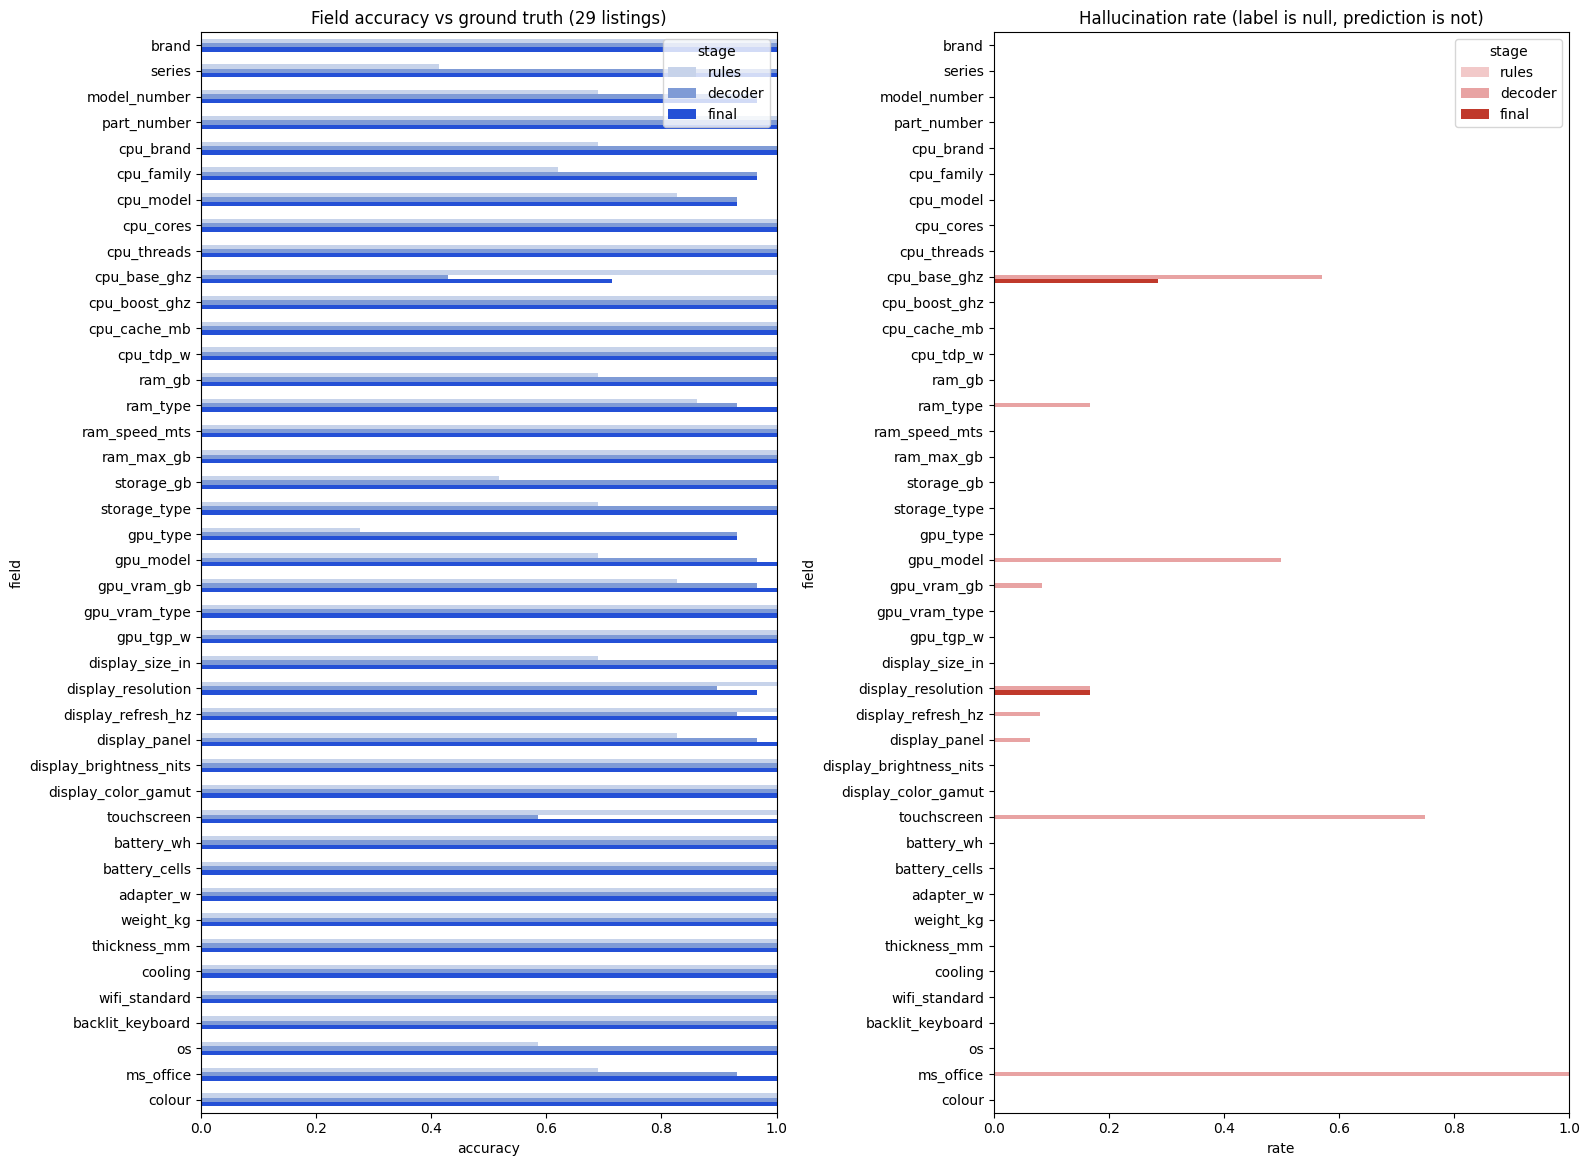

In [25]:
EVAL = {}
STAGES = ("rules", "decoder", "final")
if GROUND_TRUTH is None:
    log("Evaluation skipped: fixtures dataset not attached.", logging.WARNING)
else:
    gt_rows = []
    for lab in GROUND_TRUTH["listings"]:
        r = CONN.execute(
            "SELECT e.payload_json, e.source_conflicts_json, e.listing_id, e.rule_values_json, n.llm_values_json, "
            "n.validated_values_json, n.schema_valid, n.status, n.reasoning_mode, n.latency_s, n.forced_fields_json "
            "FROM pages p JOIN extractions e ON e.page_id=p.page_id AND e.adapter_version=? "
            f"LEFT JOIN llm_normalisations n ON n.llm_input_sha256=e.llm_input_sha256 AND {NORM_KEY_SQL} "
            "WHERE p.source='fixture' AND p.source_ref=?",
            (ADAPTER_VERSION, *NORM_KEY, lab["file"]),
        ).fetchone()
        gt_rows.append((lab, r))
    missing = [lab["file"] for lab, r in gt_rows if r is None or r["status"] != "ok"]
    if missing:
        log(
            f"{len(missing)} labelled snapshots have no successful LLM output and count as all-wrong: {missing}",
            logging.WARNING,
        )

    def stage_values(r):
        if r is None:
            return {s: {} for s in STAGES}
        ok = r["status"] == "ok"
        return {
            "rules": {
                k: v["value"]
                for k, v in json.loads(r["rule_values_json"] or "{}").items()
            },
            "decoder": json.loads(r["llm_values_json"]) if ok else {},
            "final": json.loads(r["validated_values_json"]) if ok else {},
        }

    cells = []
    for lab, r in gt_rows:
        preds = stage_values(r)
        # Only fields labelled for this listing are scored (the newer schema fields are labelled for a subset).
        for name in [n for n in FIELD_NAMES if n in lab["specs"]]:
            gold = lab["specs"][name]
            golds = gold if isinstance(gold, list) else [gold]
            for stage in STAGES:
                pred = preds[stage].get(name)
                cells.append(
                    {
                        "file": lab["file"],
                        "site": lab["site"],
                        "field": name,
                        "group": FIELD_BY_NAME[name].group,
                        "stage": stage,
                        "pred": pred,
                        "gold": gold,
                        "correct": values_match(name, pred, gold),
                        "gold_null_only": all(g is None for g in golds),
                        "pred_null": pred is None,
                    }
                )
    CELLS = pd.DataFrame(cells)

    def field_metrics(df):
        nn = df[~df.pred_null]
        stated = df[~df.gold_null_only]
        nulls = df[df.gold_null_only]
        return pd.Series(
            {
                "accuracy": df.correct.mean(),
                "precision": nn.correct.mean() if len(nn) else np.nan,
                "recall": (
                    (stated.correct & ~stated.pred_null).mean()
                    if len(stated)
                    else np.nan
                ),
                "hallucination_rate": (
                    (~nulls.pred_null).mean() if len(nulls) else np.nan
                ),
                "n": len(df),
            }
        )

    PER_FIELD = (
        CELLS.groupby(["stage", "field"])[["correct", "pred_null", "gold_null_only"]]
        .apply(field_metrics)
        .reset_index()
    )
    OVERALL = CELLS.groupby("stage")[["correct", "pred_null", "gold_null_only"]].apply(
        field_metrics
    )
    PER_SITE = (
        CELLS[CELLS.stage == "final"]
        .groupby("site")[["correct", "pred_null", "gold_null_only"]]
        .apply(field_metrics)
    )
    ok_rows = [r for _, r in gt_rows if r is not None and r["status"] == "ok"]
    EVAL["labelled_listings"] = len(gt_rows)
    EVAL["schema_validity"] = (
        float(np.mean([r["schema_valid"] for r in ok_rows])) if ok_rows else 0.0
    )
    EVAL["llm_success_rate"] = len(ok_rows) / len(gt_rows)
    EVAL["reasoning_truncated_rate"] = (
        float(np.mean([r["reasoning_mode"] == "truncated" for r in ok_rows]))
        if ok_rows
        else None
    )
    EVAL["forced_field_rate"] = (
        float(
            np.mean(
                [
                    len(json.loads(r["forced_fields_json"] or "[]")) / len(FIELDS)
                    for r in ok_rows
                ]
            )
        )
        if ok_rows
        else None
    )
    EVAL["extraction"] = {
        stage: OVERALL.loc[stage].round(4).to_dict() for stage in OVERALL.index
    }
    EVAL["extraction_final_by_site"] = {
        site: PER_SITE.loc[site].round(4).to_dict() for site in PER_SITE.index
    }
    PER_FIELD.to_csv(DIRS["metrics"] / "extraction_per_field.csv", index=False)
    CELLS.astype({"pred": str, "gold": str}).to_csv(
        DIRS["metrics"] / "extraction_cells.csv", index=False
    )
    display(OVERALL.round(3))
    display(PER_SITE.round(3))
    display(
        PER_FIELD.pivot(
            index="field",
            columns="stage",
            values=["accuracy", "hallucination_rate", "n"],
        ).round(2)
    )
    display(
        CELLS[(CELLS.stage == "final") & ~CELLS.correct][
            ["file", "site", "field", "pred", "gold"]
        ]
    )

    labelled = [n for n in FIELD_NAMES if n in set(CELLS.field)]
    fig, axes = plt.subplots(1, 2, figsize=(16, max(6, 0.28 * len(labelled))))
    pv = PER_FIELD.pivot(index="field", columns="stage", values="accuracy").loc[
        labelled, list(STAGES)
    ]
    pv.plot.barh(
        ax=axes[0], color={"rules": "#c7d3ea", "decoder": "#7f9bd6", "final": "#2450d6"}
    )
    axes[0].set(
        title=f"Field accuracy vs ground truth ({len(gt_rows)} listings)",
        xlabel="accuracy",
        xlim=(0, 1),
    )
    axes[0].invert_yaxis()
    hv = (
        PER_FIELD.pivot(index="field", columns="stage", values="hallucination_rate")
        .loc[labelled, list(STAGES)]
        .fillna(0)
    )
    hv.plot.barh(
        ax=axes[1], color={"rules": "#f2c9c9", "decoder": "#e8a3a3", "final": "#c0392b"}
    )
    axes[1].set(
        title="Hallucination rate (label is null, prediction is not)",
        xlabel="rate",
        xlim=(0, 1),
    )
    axes[1].invert_yaxis()
    plt.tight_layout()
    plt.savefig(DIRS["plots"] / "extraction_accuracy.png", dpi=120)
    plt.show()

### 19.1 Conflicts, matching precision and price correctness
- **Conflict detection**: expected self-contradictions in the labels (the IdeaPad's 8 GB vs 16 GB RAM, the Victus page
  whose title and spec table name different models) versus the conflicts the deterministic detector flagged.
- **Matching**: every pair of the 29 labelled listings is either the same product (7 pairs, each across both retailers) or
  not. A pair is predicted "same" only if both listings share a product with a trusted status. Precision is the
  headline metric because a false merge corrupts price comparisons.
- **Price correctness**: price, MRP, availability and condition from the adapters versus the labels.

,file,expected,flagged,tp,fp,fn
7,83e07f594e46577a.html.gz,[model_number],[model_number],1,0,0
9,3242ca4af547c9a5.html.gz,[ram_gb],[ram_gb],1,0,0


,a,b,gold_same,pred_same,status_a,status_b
12,75154e1bd4a0fbe3.html.gz,36bf0da094b2f6a9.html.gz,True,True,auto_matched,auto_matched
40,f1d5829f6b9d1864.html.gz,1d6b4ee510c79642.html.gz,True,False,needs_review,needs_review
67,855f888a149d6998.html.gz,f7ff779cdedbd541.html.gz,True,True,auto_matched,auto_matched
93,3c59151df5d9e6ea.html.gz,d62d8799d56d2726.html.gz,True,True,auto_matched,auto_matched
118,a1be7dc8fc4052e1.html.gz,5caecd8609b4d39c.html.gz,True,True,auto_matched,auto_matched
165,61e887ea4bff54a1.html.gz,96d0be6f2bf043c7.html.gz,True,True,auto_matched,auto_matched
277,d3221a3263a5e1da.html.gz,c3f1d165068e29db.html.gz,True,True,auto_matched,auto_matched


,file,site,price_ok,mrp_ok,availability_ok,condition_ok,price,gold_price


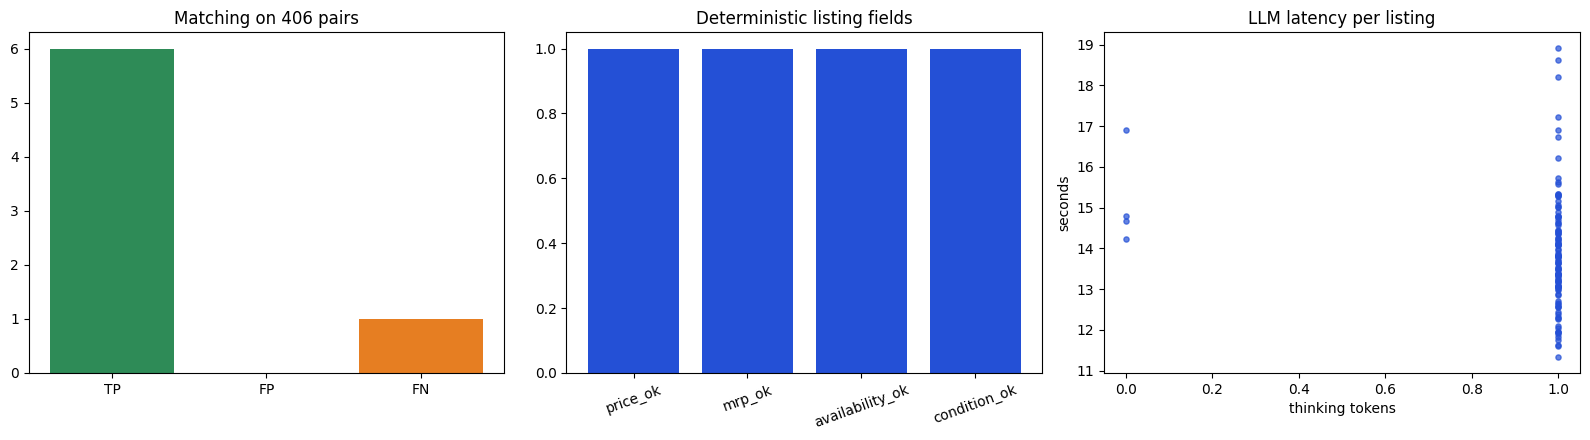

{
  "labelled_listings": 29,
  "schema_validity": 1.0,
  "llm_success_rate": 1.0,
  "reasoning_truncated_rate": 0.0,
  "forced_field_rate": 0.0008210180623973727,
  "extraction": {
    "decoder": {
      "accuracy": 0.955,
      "precision": 0.9504,
      "recall": 0.9802,
      "hallucination_rate": 0.1733,
      "n": 756.0
    },
    "final": {
      "accuracy": 0.9881,
      "precision": 0.9949,
      "recall": 0.9752,
      "hallucination_rate": 0.02,
      "n": 756.0
    },
    "rules": {
      "accuracy": 0.7923,
      "precision": 1.0,
      "recall": 0.7162,
      "hallucination_rate": 0.0,
      "n": 756.0
    }
  },
  "extraction_final_by_site": {
    "hpstore": {
      "accuracy": 0.9932,
      "precision": 0.9919,
      "recall": 0.9959,
      "hallucination_rate": 0.0417,
      "n": 294.0
    },
    "reliancedigital": {
      "accuracy": 0.989,
      "precision": 1.0,
      "recall": 0.96,
      "hallucination_rate": 0.0,
      "n": 273.0
    },
    "vijaysales": {
      "

In [26]:
if GROUND_TRUTH is not None:
    file_to_listing = {
        lab["file"]: (r["listing_id"] if r is not None else None) for lab, r in gt_rows
    }
    conf_rows = []
    for lab, r in gt_rows:
        flagged = (
            set(json.loads(r["source_conflicts_json"] or "{}"))
            if r is not None
            else set()
        )
        expected = set(lab["expected_conflicts"])
        conf_rows.append(
            {
                "file": lab["file"],
                "expected": sorted(expected),
                "flagged": sorted(flagged),
                "tp": len(expected & flagged),
                "fp": len(flagged - expected),
                "fn": len(expected - flagged),
            }
        )
    CONF = pd.DataFrame(conf_rows)
    tp, fp, fn = CONF.tp.sum(), CONF.fp.sum(), CONF.fn.sum()
    EVAL["conflict_detection"] = {
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "precision": float(tp / (tp + fp)) if tp + fp else None,
        "recall": float(tp / (tp + fn)) if tp + fn else None,
    }
    display(CONF[(CONF.tp + CONF.fp + CONF.fn) > 0])

    status = {
        r["listing_id"]: (r["product_key"], r["match_status"])
        for r in CONN.execute(
            "SELECT listing_id, product_key, match_status FROM seller_listings"
        )
    }
    gold_pairs = {tuple(sorted(p)) for p in GROUND_TRUTH["same_product_pairs"]}
    files = [lab["file"] for lab in GROUND_TRUTH["listings"]]
    pair_rows = []
    for i, a in enumerate(files):
        for b in files[i + 1 :]:
            la, lb = file_to_listing.get(a), file_to_listing.get(b)
            sa, sb = status.get(la, (None, None)), status.get(lb, (None, None))
            pred = (
                la != lb
                and sa[0] is not None
                and sa[0] == sb[0]
                and sa[1] in COMPARABLE_STATUSES
                and sb[1] in COMPARABLE_STATUSES
            )
            pair_rows.append(
                {
                    "a": a,
                    "b": b,
                    "gold_same": tuple(sorted((a, b))) in gold_pairs,
                    "pred_same": pred,
                    "status_a": sa[1],
                    "status_b": sb[1],
                }
            )
    PAIRS = pd.DataFrame(pair_rows)
    mtp = int((PAIRS.gold_same & PAIRS.pred_same).sum())
    mfp = int((~PAIRS.gold_same & PAIRS.pred_same).sum())
    mfn = int((PAIRS.gold_same & ~PAIRS.pred_same).sum())
    EVAL["matching"] = {
        "pairs": len(PAIRS),
        "gold_same_pairs": int(PAIRS.gold_same.sum()),
        "tp": mtp,
        "fp": mfp,
        "fn": mfn,
        "precision": mtp / (mtp + mfp) if mtp + mfp else None,
        "recall": mtp / (mtp + mfn) if mtp + mfn else None,
    }
    PAIRS.to_csv(DIRS["metrics"] / "matching_pairs.csv", index=False)
    display(PAIRS[PAIRS.gold_same | PAIRS.pred_same])

    price_rows = []
    for lab, r in gt_rows:
        p = json.loads(r["payload_json"]) if r is not None else {}
        price_rows.append(
            {
                "file": lab["file"],
                "site": lab["site"],
                "price_ok": p.get("price_inr") == lab["price_inr"],
                "mrp_ok": p.get("mrp_inr") == lab["mrp_inr"],
                "availability_ok": p.get("availability") == lab["availability"],
                "condition_ok": p.get("condition") == lab["condition"],
                "price": p.get("price_inr"),
                "gold_price": lab["price_inr"],
            }
        )
    PRICE_EVAL = pd.DataFrame(price_rows)
    EVAL["price"] = {
        k: float(PRICE_EVAL[k].mean())
        for k in ("price_ok", "mrp_ok", "availability_ok", "condition_ok")
    }
    display(
        PRICE_EVAL[
            ~PRICE_EVAL[["price_ok", "mrp_ok", "availability_ok", "condition_ok"]].all(
                axis=1
            )
        ]
    )

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].bar(
        ["TP", "FP", "FN"], [mtp, mfp, mfn], color=["#2e8b57", "#c0392b", "#e67e22"]
    )
    axes[0].set(title=f"Matching on {len(PAIRS)} pairs")
    axes[1].bar(list(EVAL["price"]), list(EVAL["price"].values()), color="#2450d6")
    axes[1].set(title="Deterministic listing fields", ylim=(0, 1.05))
    axes[1].tick_params(axis="x", rotation=20)
    lat = pd.read_sql_query(
        f"SELECT latency_s, reasoning_tokens FROM llm_normalisations n WHERE status='ok' AND {NORM_KEY_SQL}",
        CONN,
        params=NORM_KEY,
    )
    axes[2].scatter(
        lat.reasoning_tokens, lat.latency_s, s=14, alpha=0.7, color="#2450d6"
    )
    axes[2].set(
        title="LLM latency per listing", xlabel="thinking tokens", ylabel="seconds"
    )
    plt.tight_layout()
    plt.savefig(DIRS["plots"] / "matching_price_latency.png", dpi=120)
    plt.show()
    (DIRS["metrics"] / "evaluation.json").write_text(
        json.dumps(EVAL, indent=2, default=float), encoding="utf-8"
    )
    print(json.dumps(EVAL, indent=2, default=float))

## 20. Data-quality report
Covers the whole database, not only the labelled set: listings per site, field fill rates per site (after grounding),
conflicts and review load, the freshness of every current offer (fresh, stale or delisted, with ages), how many
spec values came from rules versus the LLM, availability and condition mix, fetch outcomes, and failures by stage.
The report is written to `reports/data_quality.md`, and the review queue to `reports/review_queue.csv`.

**Listings per site**

,site,listings,normalised,needs_review
0,hpstore,31,31,0
1,reliancedigital,43,43,3
2,vijaysales,39,39,1


**Match status**

,match_status,listings
0,auto_matched,12
1,needs_review,4
2,single_listing,90
3,unmatched_no_model_number,7


**Availability and condition (latest offer)**

...

,site,outcome,n
0,hpstore,error,6
1,hpstore,fetched_new_content,24
2,hpstore,sitemap_fetched,1
3,reliancedigital,fetched_new_content,30
4,reliancedigital,sitemap_fetched,18
5,vijaysales,fetched_new_content,30
6,vijaysales,sitemap_fetched,2


**Failures by stage (this run)**

,stage,n
0,fetch,6


**Pending review**

,relation,n
0,same_config_no_model_number,1
1,same_model_number_incompatible_specs,1


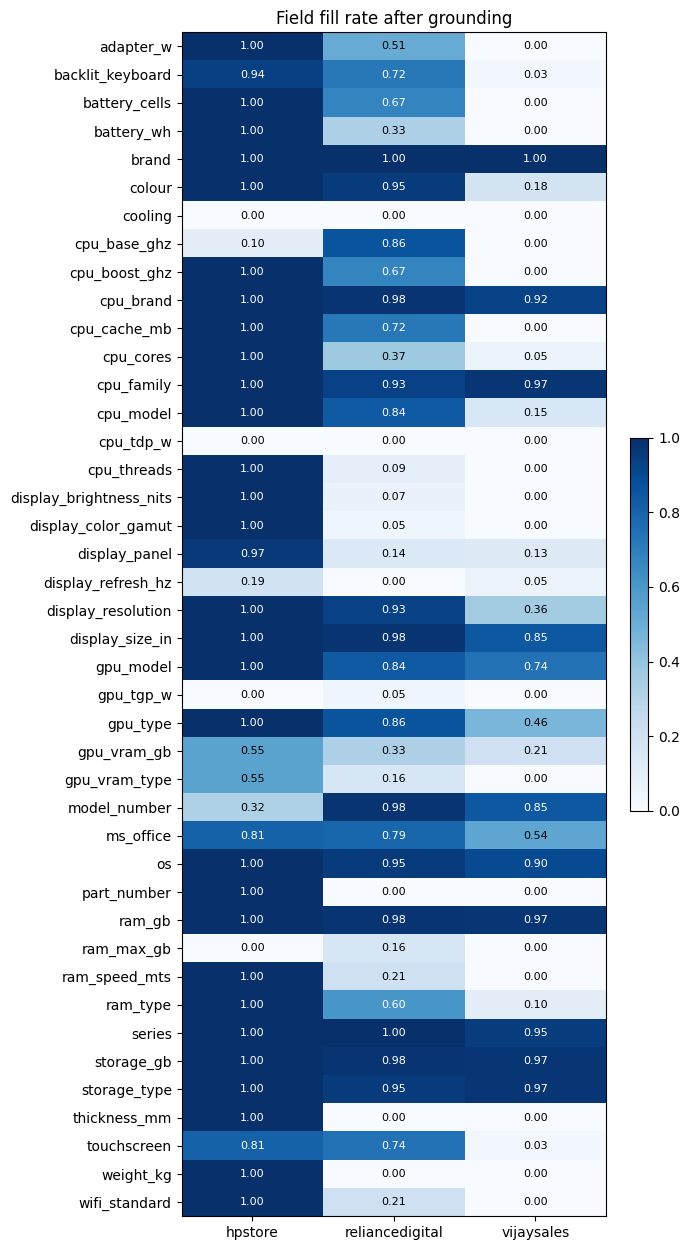

In [27]:
def df_to_md(df):
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += [
        "| " + " | ".join(str(v).replace("|", "/") for v in row) + " |"
        for row in df.itertuples(index=False)
    ]
    return chr(10).join(lines)


def data_quality_report(conn):
    rows = conn.execute(
        "SELECT l.site, n.validated_values_json FROM seller_listings l "
        "JOIN llm_normalisations n ON n.normalisation_id=l.latest_normalisation_id"
    ).fetchall()
    fill = pd.DataFrame(
        [
            {
                "site": r["site"],
                **{
                    k: v is not None
                    for k, v in json.loads(r["validated_values_json"]).items()
                },
            }
            for r in rows
        ]
    )
    fill_rate = fill.groupby("site").mean().T if len(fill) else pd.DataFrame()
    q = lambda sql: pd.read_sql_query(sql, conn)
    sections = {
        "Listings per site": q(
            "SELECT site, COUNT(*) AS listings, SUM(latest_normalisation_id IS NOT NULL) AS normalised, "
            "SUM(needs_review) AS needs_review FROM seller_listings GROUP BY site"
        ),
        "Match status": q(
            "SELECT match_status, COUNT(*) AS listings FROM seller_listings GROUP BY match_status"
        ),
        "Availability and condition (latest offer)": q(
            "SELECT l.site, o.availability, l.condition, COUNT(*) AS n FROM seller_listings l "
            "JOIN v_latest_offer o USING(listing_id) GROUP BY 1, 2, 3"
        ),
        "Freshness of current offers": q(
            "SELECT site, freshness, COUNT(*) AS offers, "
            "ROUND(MIN((julianday('now') - julianday(last_verified_at)) * 24), 1) AS min_age_h, "
            "ROUND(MAX((julianday('now') - julianday(last_verified_at)) * 24), 1) AS max_age_h "
            "FROM v_current_offers GROUP BY 1, 2"
        ),
        "Spec values by origin (rule or LLM)": q(
            "SELECT l.site, CASE WHEN j.value LIKE 'rule:%' THEN 'rule' ELSE 'llm' END AS origin, COUNT(*) AS values_n "
            "FROM seller_listings l JOIN llm_normalisations n ON n.normalisation_id=l.latest_normalisation_id, "
            "json_each(n.value_sources_json) j GROUP BY 1, 2"
        ),
        "Listings missing a price": q(
            "SELECT l.site, COUNT(*) AS n FROM seller_listings l JOIN v_latest_offer o "
            "USING(listing_id) WHERE o.price_inr IS NULL GROUP BY l.site"
        ),
        "Price signal disagreements": q(
            "SELECT listing_id, flags_json FROM price_history WHERE flags_json != '[]'"
        ),
        "Fetch outcomes (all runs)": q(
            "SELECT site, outcome, COUNT(*) AS n FROM fetch_log GROUP BY 1, 2"
        ),
        "Failures by stage (this run)": q(
            f"SELECT stage, COUNT(*) AS n FROM failures WHERE run_id='{RUN_ID}' GROUP BY stage"
        ),
        "Pending review": q(
            "SELECT relation, COUNT(*) AS n FROM match_candidates WHERE status='needs_review' GROUP BY 1"
        ),
    }
    review = q(
        "SELECT listing_id, site, url, match_status, match_reason, conflicts_json FROM seller_listings "
        "WHERE needs_review=1 OR match_status='unmatched_no_model_number'"
    )
    review.to_csv(DIRS["reports"] / "review_queue.csv", index=False)
    lines = [f"# Data-quality report ({RUN_ID})", ""]
    for title, df in sections.items():
        lines += [f"## {title}", "", df_to_md(df) if len(df) else "_none_", ""]
    lines += [
        "## Field fill rate after grounding (share of listings with a value)",
        "",
        (
            df_to_md(fill_rate.round(2).reset_index(names="field"))
            if len(fill_rate)
            else "_none_"
        ),
        "",
    ]
    (DIRS["reports"] / "data_quality.md").write_text("\n".join(lines), encoding="utf-8")
    return sections, fill_rate


DQ_SECTIONS, FILL_RATE = data_quality_report(CONN)
for _t, _df in DQ_SECTIONS.items():
    display(Markdown(f"**{_t}**"))
    display(_df)
if len(FILL_RATE):
    fig, ax = plt.subplots(figsize=(7, max(8, 0.3 * FILL_RATE.shape[0])))
    im = ax.imshow(FILL_RATE.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(FILL_RATE.shape[1]), FILL_RATE.columns)
    ax.set_yticks(range(FILL_RATE.shape[0]), FILL_RATE.index)
    for (i, j), v in np.ndenumerate(FILL_RATE.values):
        ax.text(
            j,
            i,
            f"{v:.2f}",
            ha="center",
            va="center",
            color="white" if v > 0.6 else "black",
            fontsize=8,
        )
    ax.set_title("Field fill rate after grounding")
    fig.colorbar(im, ax=ax, fraction=0.04)
    plt.tight_layout()
    plt.savefig(DIRS["plots"] / "field_fill_rate.png", dpi=120)
    plt.show()

### 20.1 Monitoring and health checks
Threshold checks turn the run's metrics into alerts, so a broken adapter, a blocked host or stale data is visible at
a glance and can be acted on between scheduled runs: fetch error rate per site, bot-protection pages, empty discovery,
extraction failure rate per site (a layout change), missing-price rate, share of stale offers, LLM failure rate and
truncated-reasoning rate. Thresholds live in the configuration cell. Alerts are stored in the `alerts` table, written
to `metrics/health.json` and logged. Expected output: `All health checks passed`, or the alert table.

In [28]:
def health_checks(conn):
    """Threshold checks over this run and the current data. Returns a DataFrame of alerts (empty when healthy)."""
    alerts = []

    def add(severity, check, subject, value, threshold, message):
        alerts.append(
            {
                "severity": severity,
                "check_name": check,
                "subject": subject,
                "value": None if value is None else round(float(value), 4),
                "threshold": threshold,
                "message": message,
            }
        )

    fetches = pd.read_sql_query(
        "SELECT site, outcome, COUNT(*) AS n FROM fetch_log WHERE run_id=? AND outcome NOT LIKE 'sitemap_%' "
        "GROUP BY 1, 2",
        conn,
        params=(RUN_ID,),
    )
    discovered = {
        stage.split(":", 1)[1]: v
        for stage, name, v in RUN_METRICS
        if stage.startswith("scrape:") and name == "discovered_urls"
    }
    for site in SITES_ENABLED if ENABLE_LIVE_SCRAPE else []:
        g = fetches[fetches.site == site]
        total, errors = (
            g.n.sum(),
            g[g.outcome.isin(["error", "host_blocked", "bot_wall"])].n.sum(),
        )
        if total and errors / total > ALERT_FETCH_ERROR_RATE:
            add(
                "error",
                "fetch_error_rate",
                site,
                errors / total,
                ALERT_FETCH_ERROR_RATE,
                f"{errors} of {total} requests failed or were blocked",
            )
        if (g.outcome == "bot_wall").any():
            add(
                "warning",
                "bot_wall",
                site,
                None,
                None,
                "bot-protection page served; host stopped for this run (never bypassed)",
            )
        if discovered.get(site, 0) == 0:
            add(
                "warning",
                "discovery_empty",
                site,
                0,
                None,
                "no laptop URLs discovered; only known listings were refreshed",
            )
    extraction = pd.read_sql_query(
        "SELECT p.site, AVG(e.ok = 0) AS failure_rate, COUNT(*) AS n FROM extractions e "
        "JOIN pages p ON p.page_id = e.page_id WHERE e.adapter_version=? GROUP BY p.site",
        conn,
        params=(ADAPTER_VERSION,),
    )
    for r in extraction.itertuples():
        if r.failure_rate > ALERT_EXTRACTION_FAILURE_RATE:
            add(
                "error",
                "extraction_failure_rate",
                r.site,
                r.failure_rate,
                ALERT_EXTRACTION_FAILURE_RATE,
                f"adapter may be broken by a layout change ({r.n} pages)",
            )
    offers = pd.read_sql_query(
        "SELECT site, AVG(price_inr IS NULL) AS missing_price, AVG(freshness = 'stale') AS stale, COUNT(*) AS n "
        "FROM v_current_offers WHERE freshness != 'delisted' GROUP BY site",
        conn,
    )
    for r in offers.itertuples():
        if r.missing_price > ALERT_MISSING_PRICE_RATE:
            add(
                "warning",
                "missing_price_rate",
                r.site,
                r.missing_price,
                ALERT_MISSING_PRICE_RATE,
                f"{r.n} current offers",
            )
        if r.stale > ALERT_STALE_SHARE:
            add(
                "warning",
                "stale_offer_share",
                r.site,
                r.stale,
                ALERT_STALE_SHARE,
                f"older than {PRICE_FRESHNESS_DAYS} days; refresh budget too small or fetches failing",
            )
    llm = conn.execute(
        "SELECT COUNT(*) AS n, AVG(status='failed') AS failed, AVG(reasoning_mode='truncated') AS truncated, "
        f"AVG(schema_valid) AS valid FROM llm_normalisations n WHERE {NORM_KEY_SQL}",
        NORM_KEY,
    ).fetchone()
    if llm["n"]:
        if llm["failed"] > ALERT_LLM_FAILURE_RATE:
            add(
                "error",
                "llm_failure_rate",
                "normalisation",
                llm["failed"],
                ALERT_LLM_FAILURE_RATE,
                f"{llm['n']} inputs",
            )
        if llm["truncated"] and llm["truncated"] > ALERT_TRUNCATED_RATE:
            add(
                "warning",
                "reasoning_truncated_rate",
                "normalisation",
                llm["truncated"],
                ALERT_TRUNCATED_RATE,
                "raise REASONING_BUDGET_TOKENS",
            )
    return pd.DataFrame(
        alerts,
        columns=["severity", "check_name", "subject", "value", "threshold", "message"],
    )


ALERTS = health_checks(CONN)
with CONN:
    for a in ALERTS.to_dict("records"):
        CONN.execute(
            "INSERT INTO alerts (run_id, severity, check_name, subject, value, threshold, message, created_at) "
            "VALUES (?,?,?,?,?,?,?,?)",
            (
                RUN_ID,
                a["severity"],
                a["check_name"],
                a["subject"],
                a["value"],
                a["threshold"],
                a["message"],
                now_iso(),
            ),
        )
(DIRS["metrics"] / "health.json").write_text(
    json.dumps(
        {"run_id": RUN_ID, "alerts": ALERTS.to_dict("records")}, indent=2, default=str
    ),
    encoding="utf-8",
)
for a in ALERTS.to_dict("records"):
    log(
        f"ALERT [{a['severity']}] {a['check_name']} {a['subject']}: {a['message']}",
        logging.WARNING,
    )
print(f"{len(ALERTS)} alert(s)" if len(ALERTS) else "All health checks passed")
display(ALERTS)

All health checks passed


,severity,check_name,subject,value,threshold,message


## 21. Example queries
The database is meant to be queried directly. Three examples: every current offer for each matched product with its
freshness and direct link (`v_current_offers`), the full price timeline of one listing, including every
re-verification (`v_price_timeline`), and the provenance of one product's specification (which listings support each
value, and whether it came from a spec rule or the LLM).

In [29]:
display(
    pd.read_sql_query(
        "SELECT p.display_name, o.site, o.seller_name, o.price_inr, o.availability, o.condition, o.match_status, "
        "o.freshness, o.last_verified_at, o.url FROM v_current_offers o "
        "JOIN canonical_products p USING(product_key) WHERE p.n_listings > 1 ORDER BY p.display_name, o.price_inr",
        CONN,
    )
)
_lid = CONN.execute(
    "SELECT listing_id FROM v_price_timeline GROUP BY listing_id ORDER BY COUNT(*) DESC LIMIT 1"
).fetchone()
if _lid:
    display(
        pd.read_sql_query(
            "SELECT observed_at, price_inr, mrp_inr, availability, event, page_id FROM v_price_timeline "
            "WHERE listing_id=? ORDER BY observed_at",
            CONN,
            params=(_lid[0],),
        )
    )
_pk = CONN.execute(
    "SELECT product_key FROM canonical_products ORDER BY n_listings DESC, product_key LIMIT 1"
).fetchone()
if _pk:
    _ps = CONN.execute(
        "SELECT * FROM product_specs WHERE product_key=?", (_pk[0],)
    ).fetchone()
    _src = json.loads(_ps["field_sources_json"])
    display(
        pd.DataFrame(
            [
                {
                    "field": n,
                    "value": _ps[n],
                    "supported_by": ", ".join(
                        f"{s['listing_id']} ({s['origin']})" for s in _src.get(n, [])
                    ),
                }
                for n in FIELD_NAMES
            ]
        )
    )

,display_name,site,seller_name,price_inr,availability,condition,match_status,freshness,last_verified_at,url
0,Asus ROG Strix G16 G615JHR-S5005WS,reliancedigital,Reliance Retail Ltd.,159990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:21:10+00:00,https://www.reliancedigital.in/product/asus-g6...
1,Asus ROG Strix G16 G615JHR-S5005WS,vijaysales,Vijay Sales,159990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:22:22+00:00,https://www.vijaysales.com/p/240725/asus-rog-s...
2,Asus ROG Strix G16 G615LM-S5128WS,reliancedigital,Reliance Retail Ltd.,199990.0,in_stock,new,auto_matched,fresh,2026-10-09T13:21:20+00:00,https://www.reliancedigital.in/product/asus-ro...
3,Asus ROG Strix G16 G615LM-S5128WS,vijaysales,Vijay Sales,199990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:22:37+00:00,https://www.vijaysales.com/p/240722/asus-rog-s...
4,HP Victus 15 15-FA2309TX,vijaysales,Vijay Sales,119990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:23:15+00:00,https://www.vijaysales.com/p/243615/hp-victus-...
5,HP Victus 15 15-FA2309TX,reliancedigital,Reliance Retail Ltd.,127495.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:22:14+00:00,https://www.reliancedigital.in/product/hp-vict...
6,Lenovo LOQ 15IRX9 83DV01JXIN,reliancedigital,Reliance Retail Ltd.,109990.0,in_stock,new,auto_matched,fresh,2026-10-09T13:21:40+00:00,https://www.reliancedigital.in/product/lenovo-...
7,Lenovo LOQ 15IRX9 83DV01JXIN,vijaysales,Vijay Sales,110999.0,in_stock,new,auto_matched,fresh,2026-10-09T13:23:07+00:00,https://www.vijaysales.com/p/258274/lenovo-loq...
8,Samsung Galaxy Book5 Pro NP940XHA-LG1IN,reliancedigital,Reliance Retail Ltd.,131990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:21:25+00:00,https://www.reliancedigital.in/product/samsung...
9,Samsung Galaxy Book5 Pro NP940XHA-LG1IN,vijaysales,Vijay Sales,131990.0,out_of_stock,new,auto_matched,fresh,2026-10-09T13:22:45+00:00,https://www.vijaysales.com/p/238688/samsung-ga...


,observed_at,price_inr,mrp_inr,availability,event,page_id
0,2026-10-09T13:23:07+00:00,110999.0,230290.0,in_stock,fixture:first_seen,20


,field,value,supported_by
0,brand,Asus,reliancedigital:9677787 (rule:spec:General Inf...
1,series,ROG Strix G16,reliancedigital:9677787 (rule:spec:General Inf...
2,model_number,G615JHR-S5005WS,reliancedigital:9677787 (rule:spec:General Inf...
3,part_number,None,
4,cpu_brand,Intel,reliancedigital:9677787 (rule:spec:Processor R...
5,cpu_family,Intel Core i7,reliancedigital:9677787 (rule:spec:Processor R...
6,cpu_model,14650HX,reliancedigital:9677787 (rule:spec:Processor R...
7,cpu_cores,16,reliancedigital:9677787 (rule:spec:Laptop Hard...
8,cpu_threads,24,reliancedigital:9677787 (rule:spec:Laptop Hard...
9,cpu_base_ghz,2.2,reliancedigital:9677787 (rule:spec:Processor R...


## 22. Run summary
One table with the key results of this run (resume source, stage times, volumes, stale and delisted offers, products
with known power limits, LLM throughput, alerts, evaluation metrics), saved as `metrics/run_summary.json`. Every
metric recorded during the run is written to `run_metrics`, and the run is marked `finished` (or
`finished_with_alerts`) in `scrape_runs`.

In [30]:
_n = lambda sql, params=(): CONN.execute(sql, params).fetchone()[0]
SUMMARY = {
    "run_id": RUN_ID,
    "resumed_from": RESUMED_FROM,
    "model": f"{MODEL_ID}@{MODEL_RESOLVED_REVISION}",
    "dtype": MODEL_DTYPE,
    "workers": len(WORKERS),
    "reasoning": f"{REASONING_EFFORT}, budget {REASONING_BUDGET_TOKENS}",
    "pages": _n("SELECT COUNT(*) FROM pages"),
    "live_pages": _n("SELECT COUNT(*) FROM pages WHERE source='live'"),
    "listings": _n("SELECT COUNT(*) FROM seller_listings"),
    "products": _n("SELECT COUNT(*) FROM canonical_products"),
    "auto_matched_products": _n(
        "SELECT COUNT(*) FROM canonical_products WHERE match_status='auto_matched'"
    ),
    "listings_needing_review": _n(
        "SELECT COUNT(*) FROM seller_listings WHERE needs_review=1"
    ),
    "products_with_lowest_price": _n(
        "SELECT COUNT(*) FROM lowest_prices WHERE lowest_price_inr IS NOT NULL"
    ),
    "stale_offers": _n("SELECT COUNT(*) FROM v_current_offers WHERE freshness='stale'"),
    "delisted_listings": _n(
        "SELECT COUNT(*) FROM seller_listings WHERE delisted_at IS NOT NULL"
    ),
    "products_with_known_power_limits": _n(
        "SELECT COUNT(*) FROM canonical_products WHERE power_limits_known=1"
    ),
    "llm_ok": _n(
        f"SELECT COUNT(*) FROM llm_normalisations n WHERE status='ok' AND {NORM_KEY_SQL}",
        NORM_KEY,
    ),
    "llm_failed": _n(
        f"SELECT COUNT(*) FROM llm_normalisations n WHERE status='failed' AND {NORM_KEY_SQL}",
        NORM_KEY,
    ),
    "llm_mean_latency_s": _n(
        f"SELECT ROUND(AVG(latency_s), 2) FROM llm_normalisations n WHERE status='ok' AND {NORM_KEY_SQL}",
        NORM_KEY,
    ),
    "failures_this_run": _n("SELECT COUNT(*) FROM failures WHERE run_id=?", (RUN_ID,)),
    "alerts": dict(Counter(ALERTS.severity)),
    "stage_seconds": {k: round(v, 1) for k, v in STAGE_TIMES.items()},
    "peak_gpu_memory_gib": {
        f"cuda:{i}": round(torch.cuda.max_memory_allocated(i) / 2**30, 2)
        for i in range(N_GPUS)
    },
    "evaluation": EVAL or "skipped (fixtures not attached)",
}
(DIRS["metrics"] / "run_summary.json").write_text(
    json.dumps(SUMMARY, indent=2, default=float), encoding="utf-8"
)
CONN.executemany(
    "INSERT INTO run_metrics (run_id, stage, metric, value, recorded_at) VALUES (?,?,?,?,?)",
    [(RUN_ID, s, m, v, now_iso()) for s, m, v in RUN_METRICS],
)
CONN.execute(
    "UPDATE scrape_runs SET finished_at=?, status=? WHERE run_id=?",
    (now_iso(), "finished_with_alerts" if len(ALERTS) else "finished", RUN_ID),
)
CONN.commit()
_flat = {k: v for k, v in SUMMARY.items() if not isinstance(v, dict)}
if EVAL:
    _flat.update(
        {
            "final_field_accuracy": EVAL["extraction"]["final"]["accuracy"],
            "final_hallucination_rate": EVAL["extraction"]["final"][
                "hallucination_rate"
            ],
            "rules_field_accuracy": EVAL["extraction"]["rules"]["accuracy"],
            "decoder_hallucination_rate": EVAL["extraction"]["decoder"][
                "hallucination_rate"
            ],
            "schema_validity": EVAL["schema_validity"],
            "matching_precision": EVAL["matching"]["precision"],
            "matching_recall": EVAL["matching"]["recall"],
            "price_correct": EVAL["price"]["price_ok"],
        }
    )
display(pd.DataFrame(_flat.items(), columns=["metric", "value"]))

,metric,value
0,run_id,20261009T192530Z
1,resumed_from,None
2,model,IFM/K2-Horizon-3.7B@d6e5432c59637093c0e125e791...
3,dtype,float16
4,workers,2
5,reasoning,"low, budget 512"
6,pages,113
7,live_pages,84
8,listings,113
9,products,107


## 23. Limitations and next steps
**Limitations**
- **Coverage**: two retailers and one manufacturer store. Most large Indian sellers and manufacturers forbid automated
  access in their terms or sit behind bot walls (see the overview); no retailer or affiliate API credentials are
  configured. Vijay Sales' server-rendered pages carry no spec table, so many fields are `null` there by design.
- **Power limits, benchmarks and thermals**: none of the current sources state CPU TDP or GPU TGP for these listings,
  so `cpu_tdp_w` and `gpu_tgp_w` are usually `null` and `power_limits_known` is usually 0; products are then compared
  on everything else and flagged. No permitted source of measured benchmarks, sustained performance or thermal limits
  was found; the `benchmarks` table is ready but empty. Component data sites (Intel, NVIDIA) forbid automated access.
- **Freshness**: this is batch, not real time. Prices are as fresh as the last scheduled run (each run refreshes at
  most `MAX_FETCHES_PER_SITE` pages per site, oldest first); anything older than `PRICE_FRESHNESS_DAYS` is labelled
  stale and excluded from current prices.
- **Network**: Kaggle runs on cloud IPs, which retailers may block (Vijay Sales discovery returned no URLs from Kaggle
  on 2026-10-09). The circuit breaker stops a failing host and the alerts say so; the fixtures keep the pipeline and
  evaluation meaningful without live access.
- **Thinking budget**: the model card recommends `high` effort with 32k output tokens. This prototype uses `low` with a
  512-token budget for throughput, and reports how often thinking was truncated. In the 2026-10-09 run the model
  closed its `low`-effort thinking block after one token on every listing (mean latency 9.6 s per listing), so answers
  were produced without reasoning; quality at `medium` or `high` is not measured here.
- **FP16 on T4**: the checkpoint is BF16. The FP16 sanity check covers a short prompt only; non-finite logits during a
  real listing make that item fail with a recorded error (it is retried without thinking).
- **Grounding** removes unsupported values but cannot catch a wrong value that also appears in the text (for example
  the "16320H" typo in one Reliance Digital spec table; the rules no longer prefill a CPU code that the title
  contradicts). Source conflicts are detected only for RAM, storage and the Reliance Digital model field.
- **Ground truth** is small (29 listings, 7 same-product pairs; the 21 new fields are labelled only on the 7 HP pages)
  and was labelled by an AI assistant from the snapshots; spot-check it before relying on the numbers. Metrics on
  this many listings have wide confidence intervals.
- **Matching** needs a model code or part number on both sides to merge automatically. Listings without one are only
  proposed for review. Colour variants have different model numbers and are separate products.
- **Availability** for Reliance Digital comes from `product_meta.sellable` in the page state, which may depend on the
  default delivery location; Vijay Sales uses schema.org availability; HP uses the page's stock label.

**Next steps**
1. Add sources that permit automated access or offer feeds (affiliate APIs with credentials, manufacturer feeds), and
   a permitted benchmark source keyed by power mode.
2. Grow the labelled set (more brands, power-limit statements, refurbished listings) and report confidence intervals.
3. Compare `reasoning_effort` (`low` closed thinking immediately in the last run) and budget settings on the labelled
   set to pick the best accuracy per second.
4. Add a small review UI over `match_candidates` that writes `match_reviews`.
5. Schedule runs (each attaching the previous output) and send `alerts` and price drops to a notification channel.

## 24. Package outputs
Zips everything in `/kaggle/working/` except caches into `outputs.zip` and shows a download link. After a saved run,
the zip and the individual files also appear in the notebook's Output tab; attaching that output to the next run lets
it resume (section 2.2), which is why the raw HTML archive is kept. Already compressed files are stored without
recompression. The SQLite connection is checkpointed and closed first so the database file is complete.

In [ ]:
CONN.execute("PRAGMA wal_checkpoint(TRUNCATE)")
CONN.close()
ZIP_PATH = WORK / "outputs.zip"
EXCLUDE_PARTS = {"__pycache__", ".cache", ".ipynb_checkpoints", "cache", "tmp", "wandb"}
STORED_SUFFIXES = {
    ".zip",
    ".png",
    ".jpg",
    ".jpeg",
    ".pt",
    ".pth",
    ".bin",
    ".safetensors",
    ".gz",
    ".npz",
}
files = [
    p
    for p in WORK.rglob("*")
    if p.is_file()
    and p != ZIP_PATH
    and not EXCLUDE_PARTS.intersection(p.relative_to(WORK).parts)
]
total_bytes = sum(p.stat().st_size for p in files)
free_bytes = shutil.disk_usage(WORK).free
assert (
    free_bytes > total_bytes * 1.05
), f"Not enough disk space to zip {total_bytes / 1e9:.2f} GB with {free_bytes / 1e9:.2f} GB free."
with zipfile.ZipFile(ZIP_PATH, "w", allowZip64=True) as archive:
    for p in tqdm(files, desc="Zipping outputs", unit="file"):
        method = (
            zipfile.ZIP_STORED
            if p.suffix.lower() in STORED_SUFFIXES
            else zipfile.ZIP_DEFLATED
        )
        archive.write(p, p.relative_to(WORK), compress_type=method)
print(
    f"Zipped {len(files)} files ({total_bytes / 1e9:.3f} GB) into {ZIP_PATH}",
    flush=True,
)
display(FileLink(os.path.relpath(ZIP_PATH)))